In [34]:
import pandas as pd
import numpy as np
import subprocess
import os
import seaborn as sns
import sys
sys.path.append("/Genomics/argo/users/yz8667/src/")
import all_function_py3
from os import path
import matplotlib.pyplot as plt
from matplotlib_venn import venn2
from scipy.stats import mannwhitneyu
from itertools import combinations
import ipynbname

# General preparation (run this before running any code)

In [35]:
def bayesian_fdr(BF, pi0):
    """
    Compute Bayesian FDR from Bayes Factors.

    Parameters
    ----------
    BF : array-like
        Bayes factors (1D array)
    pi0 : float
        Prior probability of the null hypothesis

    Returns
    -------
    FDR : np.ndarray
        Bayesian FDR values, in the original order
    """
    BF = np.asarray(BF)

    # order BF in decreasing order
    order = np.argsort(-BF)
    BF_sorted = BF[order]

    # prior probability of alternative
    pi = 1.0 - pi0

    # posterior probability of alternative (PPA)
    q = pi * BF_sorted / (1 - pi + pi * BF_sorted)

    # posterior probability of null
    q0 = 1.0 - q

    # Bayesian FDR at each cutoff
    fdr_sorted = np.cumsum(q0) / np.arange(1, len(BF_sorted) + 1)

    # reorder back to original order
    FDR = np.empty_like(fdr_sorted)
    FDR[order] = fdr_sorted

    return FDR

def q2p(x):
    """
    Rank-based normalization of scores to a pseudo-p scale.

    Parameters
    ----------
    x : pandas.Series
        Named numeric vector (e.g., gene -> score)

    Returns
    -------
    p : pandas.Series
        Rank-scaled pseudo-p values, aligned to original index
    """
    if not isinstance(x, pd.Series):
        raise TypeError("q2p expects a pandas Series with index")

    # sort values
    ec = x.sort_values()

    n = len(ec)
    ranks = np.arange(1, n + 1)

    # rank-scaled normalization
    ec_scaled = ec.values * ranks / n / ec.values.max()

    # return in original order
    return pd.Series(ec_scaled, index=ec.index).loc[x.index]

[1] "in_misa analysis is enabled."
Finished replicate 840/1000


Loading required package: stats4
Loading required package: BiocGenerics

Attaching package: ‘BiocGenerics’

The following objects are masked from ‘package:stats’:

    IQR, mad, sd, var, xtabs

The following objects are masked from ‘package:base’:

    anyDuplicated, aperm, append, as.data.frame, basename, cbind,
    colnames, dirname, do.call, duplicated, eval, evalq, Filter, Find,
    get, grep, grepl, intersect, is.unsorted, lapply, Map, mapply,
    match, mget, order, paste, pmax, pmax.int, pmin, pmin.int,
    Position, rank, rbind, Reduce, rownames, sapply, setdiff, sort,
    table, tapply, union, unique, unsplit, which.max, which.min

Loading required package: S4Vectors

Attaching package: ‘S4Vectors’

The following object is masked from ‘package:utils’:

    findMatches

The following objects are masked from ‘package:base’:

    expand.grid, I, unname

Loading required package: IRanges
Loading required package: GenomeInfoDb

Attaching package: ‘dplyr’

The following objects are 

[1] "dn_ptv analysis is enabled."
[1] "in_ptv analysis is enabled."
[1] "dn_misb analysis is enabled."
[1] "in_misb analysis is enabled."
[1] "dn_misa analysis is enabled."
[1] "in_misa analysis is enabled."


Loading required package: stats4
Loading required package: BiocGenerics

Attaching package: ‘BiocGenerics’

The following objects are masked from ‘package:stats’:

    IQR, mad, sd, var, xtabs

The following objects are masked from ‘package:base’:

    anyDuplicated, aperm, append, as.data.frame, basename, cbind,
    colnames, dirname, do.call, duplicated, eval, evalq, Filter, Find,
    get, grep, grepl, intersect, is.unsorted, lapply, Map, mapply,
    match, mget, order, paste, pmax, pmax.int, pmin, pmin.int,
    Position, rank, rbind, Reduce, rownames, sapply, setdiff, sort,
    table, tapply, union, unique, unsplit, which.max, which.min

Loading required package: S4Vectors

Attaching package: ‘S4Vectors’

The following object is masked from ‘package:utils’:

    findMatches

The following objects are masked from ‘package:base’:

    expand.grid, I, unname

Loading required package: IRanges
Loading required package: GenomeInfoDb

Attaching package: ‘dplyr’

The following objects are 

[1] "dn_ptv analysis is enabled."
[1] "in_ptv analysis is enabled."
[1] "dn_misb analysis is enabled."
[1] "in_misb analysis is enabled."
[1] "dn_misa analysis is enabled."
[1] "in_misa analysis is enabled."


Loading required package: stats4
Loading required package: BiocGenerics

Attaching package: ‘BiocGenerics’

The following objects are masked from ‘package:stats’:

    IQR, mad, sd, var, xtabs

The following objects are masked from ‘package:base’:

    anyDuplicated, aperm, append, as.data.frame, basename, cbind,
    colnames, dirname, do.call, duplicated, eval, evalq, Filter, Find,
    get, grep, grepl, intersect, is.unsorted, lapply, Map, mapply,
    match, mget, order, paste, pmax, pmax.int, pmin, pmin.int,
    Position, rank, rbind, Reduce, rownames, sapply, setdiff, sort,
    table, tapply, union, unique, unsplit, which.max, which.min

Loading required package: S4Vectors

Attaching package: ‘S4Vectors’

The following object is masked from ‘package:utils’:

    findMatches

The following objects are masked from ‘package:base’:

    expand.grid, I, unname

Loading required package: IRanges
Loading required package: GenomeInfoDb

Attaching package: ‘dplyr’

The following objects are 

... (309 outputs left out)

Loading required package: stats4
Loading required package: BiocGenerics

Attaching package: ‘BiocGenerics’

The following objects are masked from ‘package:stats’:

    IQR, mad, sd, var, xtabs

The following objects are masked from ‘package:base’:

    anyDuplicated, aperm, append, as.data.frame, basename, cbind,
    colnames, dirname, do.call, duplicated, eval, evalq, Filter, Find,
    get, grep, grepl, intersect, is.unsorted, lapply, Map, mapply,
    match, mget, order, paste, pmax, pmax.int, pmin, pmin.int,
    Position, rank, rbind, Reduce, rownames, sapply, setdiff, sort,
    table, tapply, union, unique, unsplit, which.max, which.min

Loading required package: S4Vectors

Attaching package: ‘S4Vectors’

The following object is masked from ‘package:utils’:

    findMatches

The following objects are masked from ‘package:base’:

    expand.grid, I, unname

Loading required package: IRanges
Loading required package: GenomeInfoDb

Attaching package: ‘dplyr’

The following objects are 

[1] "dn_ptv analysis is enabled."
[1] "in_ptv analysis is enabled."
[1] "dn_misb analysis is enabled."
[1] "in_misb analysis is enabled."
[1] "dn_misa analysis is enabled."
[1] "in_misa analysis is enabled."


Loading required package: stats4
Loading required package: BiocGenerics

Attaching package: ‘BiocGenerics’

The following objects are masked from ‘package:stats’:

    IQR, mad, sd, var, xtabs

The following objects are masked from ‘package:base’:

    anyDuplicated, aperm, append, as.data.frame, basename, cbind,
    colnames, dirname, do.call, duplicated, eval, evalq, Filter, Find,
    get, grep, grepl, intersect, is.unsorted, lapply, Map, mapply,
    match, mget, order, paste, pmax, pmax.int, pmin, pmin.int,
    Position, rank, rbind, Reduce, rownames, sapply, setdiff, sort,
    table, tapply, union, unique, unsplit, which.max, which.min

Loading required package: S4Vectors

Attaching package: ‘S4Vectors’

The following object is masked from ‘package:utils’:

    findMatches

The following objects are masked from ‘package:base’:

    expand.grid, I, unname

Loading required package: IRanges
Loading required package: GenomeInfoDb

Attaching package: ‘dplyr’

The following objects are 

[1] "dn_ptv analysis is enabled."
[1] "in_ptv analysis is enabled."
[1] "dn_misb analysis is enabled."
[1] "in_misb analysis is enabled."
[1] "dn_misa analysis is enabled."
[1] "in_misa analysis is enabled."
All downsampling replicates finished.


In [36]:
def combine_ucsf_fusup11_tada_results(df_fu_sup11, tada_output_path, sample_tag, method_tag, rr_tag):
    df = pd.read_csv(tada_output_path + f"TADA_FuScaled_{sample_tag}_Roulette_MR_{method_tag}_{rr_tag}.txt", sep = "\t")
    df["l10BF_ASD_EM"] = df.apply(lambda x: np.log10(x["bf.dn.em"] * x["bf.in.em"]), axis=1)
    df_merge = pd.merge(df_fu_sup11, df[["gene_id", "l10BF_ASD_EM"]], on="gene_id", how="left")
    lbf_asd_cols = []
    bf_asd_cols = []
    for x in df_merge.columns:
        if x.startswith("l10BF_ASD"):
            lbf_asd_cols.append(x)
            bf_asd_cols.append(x.replace("l10", ""))
            df_merge[x.replace("l10", "")] = df_merge[x].apply(lambda y: 10 ** y)
            print(df_merge[x.replace("l10", "")].min())
    df_output = df_merge[["gene", "gene_gencodeV33", "gene_id", "FDR_TADA_ASD", "p_TADA_ASD"] + lbf_asd_cols + bf_asd_cols]
    df_output["bf"] = df_output[bf_asd_cols].prod(axis=1, skipna=True)
    df_output["fdr"] = bayesian_fdr(df_output["bf"].to_numpy(), pi0=0.95)
    qval = pd.Series(df_output["fdr"].to_numpy(), index=df_output["gene_id"].astype(str).to_numpy())
    pval_by_gene = q2p(qval)                
    df_output["pval"] = df_output["gene_id"].astype(str).map(pval_by_gene)
    df_output = df_output.rename(columns = {"bf": "BF_ASD", "fdr": "FDR_TADA_ASD_AddEM", "pval": "p_TADA_ASD_AddEM"})
    df_output.to_csv(f"{tada_output_path}TADA_FuRawSup11_{sample_tag}_Roulette_MR_{method_tag}_{rr_tag}.txt", sep = "\t", header = True, index=False)
    return df_output


In [37]:
def lbf_heatmap(df, vmax=None, figtitle=None):
    celltype_cols = [
        "l10BF_ASD_EM_Excitatory_Neurons",
        "l10BF_ASD_EM_Microglia",
        "l10BF_ASD_EM_Astrocytes",
        # "l10BF_ASD_EM_Other_Cerebral_Cortex",
        "l10BF_ASD_Coding",
    ]

    heatmap_df = df.set_index("gene")[celltype_cols].T  

    heatmap_df.index = [
        "Excitatory neurons",
        "Microglia",
        "Astrocytes",
        # "Other elements in cerebral cortex",
        "Coding"
    ]

    plt.figure(figsize=(0.4 * heatmap_df.shape[1], 3))
    sns.heatmap(
        heatmap_df,
        cmap="Reds",
        vmin=0,
        vmax=vmax,          # 🔥 cap the reddest here
        linewidths=0.3,
        cbar_kws={"label": "log10 Bayes factor"}
    )
    plt.xlabel("Genes(n={})".format(heatmap_df.shape[1]))
    plt.ylabel("Cell type")
    plt.xticks(fontsize=12, rotation=90)
    plt.yticks(fontsize=12)
    plt.tight_layout()
    if figtitle:
        plt.title(figtitle)
    plt.show()


In [38]:
def tada_analysis(df, asd_genes, title, gene_col = "gene", coding_fdr_col = "FDR_TADA_ASD", all_fdr_col = "FDR_TADA_ASD_AddEM", significant_threshold = 0.05):
    all_genes = set(df[gene_col])
    tada_coding_genes = set(df[df[coding_fdr_col] < significant_threshold][gene_col])
    tada_all_genes = set(df[df[all_fdr_col] < significant_threshold][gene_col])

    # venn
    plt.figure(figsize=(3,3))
    venn2(
        [set(tada_coding_genes), set(tada_all_genes)],
        set_labels=("TADA_coding", "TADA_coding+noncoding")
    )
    plt.title(title)
    plt.show()

    # bar
    tag2genes = {"TADA coding": tada_coding_genes, "TADA additional": tada_all_genes - tada_coding_genes}
    c2 = len(asd_genes & all_genes)
    n2 = len(all_genes)
    xtick_list = []
    y_list = []
    yerr_list = []
    pval_list = []
    i = 0
    for tag, genes in tag2genes.items():
        c1 = len(genes & asd_genes)
        n1 = len(genes)
        enr, log_enr, SE_log_enr, pval, z, conf_intervals = all_function_py3.calc_enr(c1, n1, c2, n2, confidence_level = 0.95)
        print(f"c1: {c1}, n1: {n1}, c2: {c2}, n2: {n2}")
        print(f"enrichment: {enr}, log_enr: {log_enr}, SE_log_enr: {SE_log_enr}, pval: {pval}, z: {z}, conf_intervals: {conf_intervals}")
        xtick_list.append((f"{tag}(n={len(genes)})", i))
        y_list.append(log_enr)
        yerr_list.append(SE_log_enr)
        pval_list.append(pval)
        i += 1
    all_function_py3.bar_graph(xtick_list, y_list, ["#DEB491", "#8EC695"], output=None, y_err=yerr_list, xtick_rotation = 90, xtick_align_ha = "right", xtick_align_va = "top", title = title, figsize = (2,4), fontsize = 12, ylabel="log2(enrichment)", pval_list = pval_list, pval_sci = True)

    return tada_coding_genes, tada_all_genes

In [39]:
def violin_analysis(tag2file, df_idmap, df_haplo, asd_genes, all_genes, title, fdr_col = "fdr", gene_col = "Hugo_Symbol", color_dict = None):
    def mannwhitney_test_haplo(df):
        df_output = {"group_x": [], "group_y": [], "pval": []}
        for x,y in combinations(df["group"].unique().tolist(), 2):
            x_score = df[df["group"] == x]["Haploinsufficiency_Score"].tolist()
            y_score = df[df["group"] == y]["Haploinsufficiency_Score"].tolist()
            u, p = mannwhitneyu(x_score, y_score, alternative="two-sided")
            df_output["group_x"].append(x)
            df_output["group_y"].append(y)
            df_output["pval"].append(p)
        df_output = pd.DataFrame(df_output)
        display(df_output)

    df_output = {"group": [f"SFARI_genes (n={len(asd_genes)})"] * len(asd_genes), "gene": sorted(asd_genes)}
    df_unique = {"group": [f"SFARI_genes (n={len(asd_genes)})"] * len(asd_genes), "gene": sorted(asd_genes)}
    x_list = []
    ytick_list = []
    last_genes = set()
    for tag,file in tag2file.items():
        if os.path.exists(file) == False:
            continue
        print(file)
        df = pd.read_csv(file, sep = "\t")
        if tag.find("network") == -1:
            genes = sorted(set(df[df[fdr_col] <= 0.05][gene_col]))
        else:
            df = df[df["Subnetwork_size"] > 5]
            prots = []
            for y in df["Subnetwork_genes"]:
                prots.extend(y.split(","))
            prots = set(prots)
            genes = sorted(set(df_idmap[df_idmap["UniProt"].isin(prots)]["ID"]))
            print(f"Number of subnetworks: {len(df)}")
        unique_genes = set(genes) - last_genes
        print(f"{tag}: total genes = {len(genes)}, last genes = {len(last_genes)}, unique genes = {len(unique_genes)}")
        df_output["group"].extend([tag + f" (n={len(genes)})"] * len(genes))
        df_output["gene"].extend(genes)
        if tag == "coding":
            df_unique["group"].extend([tag + f" (n={len(unique_genes)})"] * len(unique_genes))
        else:
            df_unique["group"].extend([tag + f"_additional (n={len(unique_genes)})"] * len(unique_genes))
        df_unique["gene"].extend(unique_genes)
        x_list.append(len(genes))
        ytick_list.append(tag + f" (n={len(genes)})")
        last_genes = set(genes)
    df_output["group"].extend([f"all_genes (n={len(all_genes)})"] * len(all_genes))
    df_output["gene"].extend(sorted(all_genes))
    df_unique["group"].extend([f"all_genes (n={len(all_genes)})"] * len(all_genes))
    df_unique["gene"].extend(sorted(all_genes))

    all_function_py3.horizontal_bar_graph(ytick_list, x_list, x_original_2 = None, output = None, xerr_original = None, pval_list = None, figsize = (3,3), color = None, label = None, fontsize = 12, title = title, \
        cutoff = None, xlim = None, ylim = None, invert = False, tick_bins = None, labelpad = 10, ax = None, show = True, capsize = 5, barWidth = 0.618, logbase = None)

    df_output = pd.DataFrame(df_output)
    print("before haploinsufficiency annotation:", df_output.shape[0])
    df_output = pd.merge(df_output, df_haplo[["gene", "Haploinsufficiency_Score"]], on = "gene")
    print("after haploinsufficiency annotation:", df_output.shape[0])
    if color_dict is None:
        color_dict = {}
        for x in df_output["group"].unique():
            if x.find("SFARI_genes") != -1:
                color_dict[x] = "red"
            elif x.find("all_genes") != -1:
                color_dict[x] = "gray"
            else:
                color_dict[x] = "orange"
    all_function_py3.violin_plot(df_output, "group", "Haploinsufficiency_Score", color_dict = color_dict, x_col_order = None, contrast_col = None, output = None, title = title, subplot = False, \
        ylim = None, xlim = None, trunc = False, linewidth = 1.5, fontsize = 16, figsize = None, tick_rotation = 30, tick_align = "right", \
        tick_bins = 4, orientation = "vertical", scale = "area", with_edge = False, width = 1, legend = True, labelpad = 10, ax = None)
    mannwhitney_test_haplo(df_output)

    df_unique = pd.DataFrame(df_unique)
    print("before haploinsufficiency annotation (unique):", df_unique.shape[0])
    df_unique = pd.merge(df_unique, df_haplo[["gene", "Haploinsufficiency_Score"]], on = "gene")
    print("after haploinsufficiency annotation (unique):", df_unique.shape[0])
    color_dict = {}
    for x in df_unique["group"].unique():
        if x.find("SFARI_genes") != -1:
            color_dict[x] = "red"
        elif x.find("all_genes") != -1:
            color_dict[x] = "gray"
        else:
            color_dict[x] = "orange"
    all_function_py3.violin_plot(df_unique, "group", "Haploinsufficiency_Score", color_dict = color_dict, x_col_order = None, contrast_col = None, output = None, title = title, subplot = False, \
        ylim = None, xlim = None, trunc = False, linewidth = 1.5, fontsize = 16, figsize = None, tick_rotation = 30, tick_align = "right", \
        tick_bins = 4, orientation = "vertical", scale = "area", with_edge = False, width = 1, legend = True, labelpad = 10, ax = None)
    mannwhitney_test_haplo(df_unique)
    
    return df_output, df_unique


In [58]:
def violin_analysis_new(tag2file, df_idmap, df_haplo, asd_genes, all_genes, title, fdr_col = "fdr", gene_col = "Hugo_Symbol", color_dict = None, ylim = (-0.1, 1.5)):
    def mannwhitney_test_haplo(df):
        df_output = {"group_x": [], "group_y": [], "pval": []}
        for x,y in combinations(df["group"].unique().tolist(), 2):
            x_score = df[df["group"] == x]["Haploinsufficiency_Score"].tolist()
            y_score = df[df["group"] == y]["Haploinsufficiency_Score"].tolist()
            u, p = mannwhitneyu(x_score, y_score, alternative="two-sided")
            df_output["group_x"].append(x)
            df_output["group_y"].append(y)
            df_output["pval"].append(p)
        df_output = pd.DataFrame(df_output)
        display(df_output)

    df_output = {"group": [f"SFARI_genes (n={len(asd_genes)})"] * len(asd_genes), "gene": sorted(asd_genes)}
    df_unique = {"group": [f"SFARI_genes (n={len(asd_genes)})"] * len(asd_genes), "gene": sorted(asd_genes)}
    x_list = []
    ytick_list = []
    last_genes = set()
    for tag,file in tag2file.items():
        if os.path.exists(file) == False:
            continue
        print(file)
        df = pd.read_csv(file, sep = "\t")
        genes = sorted(df[gene_col].unique())
        print(f"{tag}: total genes = {len(genes)}")
        df_output["group"].extend([tag + f" (n={len(genes)})"] * len(genes))
        df_output["gene"].extend(genes)
        x_list.append(len(genes))
        ytick_list.append(tag + f" (n={len(genes)})")
    df_output["group"].extend([f"all_genes (n={len(all_genes)})"] * len(all_genes))
    df_output["gene"].extend(sorted(all_genes))
    
    df_output = pd.DataFrame(df_output)
    print("before haploinsufficiency annotation:", df_output.shape[0])
    df_output = pd.merge(df_output, df_haplo[["gene", "Haploinsufficiency_Score"]], on = "gene")
    print("after haploinsufficiency annotation:", df_output.shape[0])
    color_dict_full = {}
    for x in df_output["group"].unique():
        if x.find("SFARI_genes") != -1:
            color_dict_full[x] = "red"
        elif x.find("all_genes") != -1:
            color_dict_full[x] = "gray"
        else:
            color_dict_full[x] = color_dict[x.split(" ")[0]]
    all_function_py3.violin_plot(df_output, "group", "Haploinsufficiency_Score", color_dict = color_dict_full, x_col_order = None, contrast_col = None, output = None, title = title, subplot = False, \
        ylim = ylim, xlim = None, trunc = False, linewidth = 1.5, fontsize = 20, figsize = None, tick_rotation = 30, tick_align = "right", \
        tick_bins = 4, orientation = "vertical", scale = "area", with_edge = False, width = 1, legend = True, labelpad = 10, ax = None)
    mannwhitney_test_haplo(df_output)
    
    return df_output, df_unique


In [59]:
folder_path = str(ipynbname.path().parent) + "/../"
print(folder_path)

/Genomics/argo/users/yz8667/Autism_network_integration/scripts/GitHub/analysis/../


In [60]:
tada_output_path = f"{folder_path}/data/TADA/output/InhAll_DNVAll/"
fu_sup_tab11 = f"{folder_path}/ref/NIHMS1844621-supplement-Supplementary_Table.xlsx"
df_fu_sup11 = pd.read_excel(fu_sup_tab11, sheet_name="Supplementary Table 11").dropna(subset = "chromosome")

In [61]:
dr = f"{folder_path}/ref/"
asd_genes = set(pd.read_csv(f"{dr}SFARI_GeneList/Siwei_GeneList.txt", sep="\t", header=None)[0])
print(len(asd_genes), list(asd_genes)[:20])

511 ['IQSEC2', 'ACTL6B', 'SLC35B1', 'MSNP1AS', 'NAA15', 'ALDH1A3', 'GATM', 'PON1', 'SIN3A', 'PRICKLE1', 'GABBR2', 'POMGNT1', 'PCDH19', 'GABRB2', 'NIPBL', 'NTRK2', 'PRKD2', 'SLC7A3', 'RAC1', 'PPP2CA']


In [62]:
df = pd.read_csv(f"{folder_path}/data/TADA/output/InhAll_DNVAll/TADA_FuRawSup11_Combined_Simple_Roulette_MR_ScaleByLOEUF.txt", sep = "\t")
# all_genes = set(df["gene_gencodeV33"])
all_genes = set(df["gene"])  
print(df.shape[0], len(all_genes), list(all_genes)[:20])

18128 18128 ['FGFBP1', 'C2orf82', 'AMBRA1', 'PRAMEF14', 'NAA15', 'LRR1', 'ATP5E', 'RYR2', 'PICALM', 'ZRANB1', 'NSF', 'TBATA', 'BTBD6', 'ETFA', 'SLC2A14', 'SCRG1', 'DEFB110', 'PPAP2B', 'WDR78', 'ZNF230']


In [63]:
df_haplo = pd.read_csv(f"{folder_path}/ref/pgen.1001154.s001.txt", sep = "\t", header = None)
display(df_haplo.head())
print(df_haplo.shape[0])
display(df_haplo.dropna(subset = [4]))
df_haplo["gene"] = df_haplo[3].apply(lambda x: x.split("|")[0])
df_haplo = df_haplo.rename(columns={4: "Haploinsufficiency_Score"})
df_haplo

,0,1,2,3,4,5,6,7,8
0,chr1,869458,884494,NOC2L|0.379|41.5%,0.379,.,869459,884494,"125,130,0"
1,chr1,924207,925333,HES4|0.319|50.8%,0.319,.,924208,925333,"100,155,0"
2,chr1,938741,939782,ISG15|0.191|80.5%,0.191,.,938742,939782,"25,230,0"
3,chr1,1128751,1131952,TNFRSF18|0.088|98.0%,0.088,.,1128752,1131952,"0,255,0"
4,chr1,1136582,1139411,TNFRSF4|0.165|86.9%,0.165,.,1136583,1139411,"25,230,0"


12218


,0,1,2,3,4,5,6,7,8
0,chr1,869458,884494,NOC2L|0.379|41.5%,0.379,.,869459,884494,"125,130,0"
1,chr1,924207,925333,HES4|0.319|50.8%,0.319,.,924208,925333,"100,155,0"
2,chr1,938741,939782,ISG15|0.191|80.5%,0.191,.,938742,939782,"25,230,0"
3,chr1,1128751,1131952,TNFRSF18|0.088|98.0%,0.088,.,1128752,1131952,"0,255,0"
4,chr1,1136582,1139411,TNFRSF4|0.165|86.9%,0.165,.,1136583,1139411,"25,230,0"
...,...,...,...,...,...,...,...,...,...
12213,chrX,153766510,153767027,H2AFB1|0.192|80.1%,0.192,.,153766511,153767027,"25,230,0"
12214,chrX,153908257,153938384,FUNDC2|0.077|98.7%,0.077,.,153908258,153938384,"0,255,0"
12215,chrX,154140720,154147046,RAB39B|0.562|21.8%,0.562,.,154140721,154147046,"175,80,0"
12216,chrX,154158719,154217180,CLIC2|0.340|47.2%,0.340,.,154158720,154217180,"125,130,0"


,0,1,2,3,Haploinsufficiency_Score,5,6,7,8,gene
0,chr1,869458,884494,NOC2L|0.379|41.5%,0.379,.,869459,884494,"125,130,0",NOC2L
1,chr1,924207,925333,HES4|0.319|50.8%,0.319,.,924208,925333,"100,155,0",HES4
2,chr1,938741,939782,ISG15|0.191|80.5%,0.191,.,938742,939782,"25,230,0",ISG15
3,chr1,1128751,1131952,TNFRSF18|0.088|98.0%,0.088,.,1128752,1131952,"0,255,0",TNFRSF18
4,chr1,1136582,1139411,TNFRSF4|0.165|86.9%,0.165,.,1136583,1139411,"25,230,0",TNFRSF4
...,...,...,...,...,...,...,...,...,...,...
12213,chrX,153766510,153767027,H2AFB1|0.192|80.1%,0.192,.,153766511,153767027,"25,230,0",H2AFB1
12214,chrX,153908257,153938384,FUNDC2|0.077|98.7%,0.077,.,153908258,153938384,"0,255,0",FUNDC2
12215,chrX,154140720,154147046,RAB39B|0.562|21.8%,0.562,.,154140721,154147046,"175,80,0",RAB39B
12216,chrX,154158719,154217180,CLIC2|0.340|47.2%,0.340,.,154158720,154217180,"125,130,0",CLIC2


In [64]:
# load canonical UniProts
fasta_dict = {}
with open(f"{folder_path}src/NetFlow3D/metadata/UP000005640_9606.fasta") as f:
    header = None
    seq_chunks = []

    for line in f:
        line = line.strip()
        if line.startswith(">"):
            if header is not None:
                fasta_dict[header] = "".join(seq_chunks)

            # parse header: >tr|A0A075B6V1|A0A075B6V1_HUMAN ...
            parts = line[1:].split("|")
            header = parts[1]
            seq_chunks = []
        else:
            seq_chunks.append(line)

    # last sequence
    if header is not None:
        fasta_dict[header] = "".join(seq_chunks)
len(fasta_dict)

20596

In [65]:
# load id mapping file
df_idmap = pd.read_csv(f"{folder_path}src/NetFlow3D/metadata/HUMAN_9606_idmapping.dat.gz", sep="\t", header=None, names=["UniProt", "ID_type", "ID"])
df_idmap = df_idmap[df_idmap["ID_type"] == "Gene_Name"]
df_idmap["UniProt"] = df_idmap["UniProt"].apply(lambda x: x.split("-")[0])
df_idmap["ID"] = df_idmap["ID"].apply(lambda x: x.split(".")[0])
df_idmap_slim = df_idmap[df_idmap["UniProt"].isin(fasta_dict.keys())]
display(df_idmap)
display(df_idmap_slim)

,UniProt,ID_type,ID
1,P31946,Gene_Name,YWHAB
118,P62258,Gene_Name,YWHAE
246,Q04917,Gene_Name,YWHAH
336,P61981,Gene_Name,YWHAG
462,P31947,Gene_Name,SFN
...,...,...,...
6198707,A0A678ZI47,Gene_Name,HLA-DRB1
6198717,A0A678ZTH6,Gene_Name,HLA-DQB1
6198728,A0A1C8DU67,Gene_Name,HLA-DRB1
6198740,A0A1D8MAN8,Gene_Name,HLA-A


,UniProt,ID_type,ID
1,P31946,Gene_Name,YWHAB
118,P62258,Gene_Name,YWHAE
246,Q04917,Gene_Name,YWHAH
336,P61981,Gene_Name,YWHAG
462,P31947,Gene_Name,SFN
...,...,...,...
5924608,A0A0J9YVS3,Gene_Name,IGHJ4
6024285,A0A0J9YW14,Gene_Name,IGHJ3
6026795,A0A0G2JNF4,Gene_Name,KIR2DP1
6062812,A0A140TA62,Gene_Name,LOC100653049


# E-G linkage

In [27]:
# retrieved from cbsuhy01: /local/storage/NetFlow_ASD/Week8_429/Promoters
dr = f"{folder_path}ref/"
df = pd.read_csv(dr + "promoters_1kb_tss_centered.coding.v43.bed", sep="\t", header=None)
df["tss_start"] = df.apply(lambda x: int((x[1] + x[2]) / 2), axis=1)
df["tss_end"] = df["tss_start"] + 1
display(df[[0, "tss_start", "tss_end", 7, 3, 6, 5]])
df[[0, "tss_start", "tss_end", 7, 3, 6, 5]].to_csv(dr + "gencode_hg38_TSS.bed", sep="\t", header=False, index=False)

,0,tss_start,tss_end,7,3,6,5
0,chr1,65418,65419,ENSG00000186092.7,ENST00000641515.2,OR4F5,+
1,chr1,451678,451679,ENSG00000284733.2,ENST00000426406.4,OR4F29,-
2,chr1,686654,686655,ENSG00000284662.2,ENST00000332831.5,OR4F16,-
3,chr1,923922,923923,ENSG00000187634.13,ENST00000616016.5,SAMD11,+
4,chr1,923922,923923,ENSG00000187634.13,ENST00000618323.5,SAMD11,+
...,...,...,...,...,...,...,...
170683,chrM,10469,10470,ENSG00000212907.2,ENST00000361335.1,MT-ND4L,+
170684,chrM,10759,10760,ENSG00000198886.2,ENST00000361381.2,MT-ND4,+
170685,chrM,12336,12337,ENSG00000198786.2,ENST00000361567.2,MT-ND5,+
170686,chrM,14673,14674,ENSG00000198695.2,ENST00000361681.2,MT-ND6,-


In [28]:
dr = f"{folder_path}data/TADA/input/InhAll_DNVAll/"
for x in ["Combined_Simple", "Cerebral_Cortex", "Deconv_Excitatory_Neurons", "Deconv_Microglia", "Deconv_Astrocytes"]:
    df = pd.read_csv(dr + f"TADA_{x}_roulette.txt", sep="\t", dtype = str)
    df[["chrom", "start", "end"]] = df["enh_id"].apply(lambda x: pd.Series([x.split(":")[0]] + x.split(":")[1].split("-")))
    df[["chrom", "start", "end", "enh_id"]].to_csv(dr + f"TADA_{x}_Elements.bed", sep="\t", header=False, index=False)

In [29]:
# parameters
flank = 100000

In [30]:
tss_file =  f"{folder_path}ref/gencode_hg38_TSS.bed"
dr = f"{folder_path}data/TADA/input/InhAll_DNVAll/"
for x in ["Combined_Simple", "Deconv_Microglia", "Deconv_Excitatory_Neurons", "Deconv_Astrocytes", "Cerebral_Cortex"]:
    input_file = dr + "TADA_" + x + "_Elements.bed"
    output_file   = dr + "TADA_" + x + "_Elements_CenteredWindow" + str(flank) + "_V43CodingTSS.bed"
    cmd = [
        "bedtools", "window",
        "-a", input_file,
        "-b", tss_file,
        "-w", str(flank)
    ]

    with open(output_file, "w") as f:
        subprocess.run(cmd, stdout=f, check=True)

    print("Finished:", output_file)

Finished: /Genomics/argo/users/yz8667/Autism_network_integration/scripts/GitHub/analysis/../data/TADA/input/InhAll_DNVAll/TADA_Combined_Simple_Elements_CenteredWindow100000_V43CodingTSS.bed
Finished: /Genomics/argo/users/yz8667/Autism_network_integration/scripts/GitHub/analysis/../data/TADA/input/InhAll_DNVAll/TADA_Deconv_Microglia_Elements_CenteredWindow100000_V43CodingTSS.bed
Finished: /Genomics/argo/users/yz8667/Autism_network_integration/scripts/GitHub/analysis/../data/TADA/input/InhAll_DNVAll/TADA_Deconv_Excitatory_Neurons_Elements_CenteredWindow100000_V43CodingTSS.bed
Finished: /Genomics/argo/users/yz8667/Autism_network_integration/scripts/GitHub/analysis/../data/TADA/input/InhAll_DNVAll/TADA_Deconv_Astrocytes_Elements_CenteredWindow100000_V43CodingTSS.bed
Finished: /Genomics/argo/users/yz8667/Autism_network_integration/scripts/GitHub/analysis/../data/TADA/input/InhAll_DNVAll/TADA_Cerebral_Cortex_Elements_CenteredWindow100000_V43CodingTSS.bed


In [31]:
dr = f"{folder_path}data/TADA/input/InhAll_DNVAll/"
for x in ["Combined_Simple", "Deconv_Microglia", "Deconv_Excitatory_Neurons", "Deconv_Astrocytes", "Cerebral_Cortex"]:
    input_file = dr + "TADA_" + x + "_Elements.bed"
    df_in = pd.read_csv(input_file, sep="\t", header=None)
    output_file   = dr + "TADA_" + x + "_Elements_CenteredWindow" + str(flank) + "_V43CodingTSS.bed"
    df_out = pd.read_csv(output_file, sep="\t", header=None)
    df_out[7] = df_out[7].apply(lambda x: x.split(".")[0])  # gene_name
    df_out["element_center"] = df_out.apply(lambda row: int((row[1] + row[2]) / 2), axis=1)
    df_out["dist"] = abs(df_out["element_center"] - df_out[5]) # distance
    print(df_in.shape[0], len(df_out[3].unique()), df_out.shape[0])
    display(df_out.head())
    df_final = {"enh_id": [], "gene_id": [], "distance": []}
    for y,df_one in df_out.groupby(3):
        gene_list = []
        dist_list = []
        for z,df_two in df_one.groupby(7):
            gene_list.append(z)
            dist_list.append(str(df_two["dist"].min()))
        df_final["enh_id"].append(y)
        df_final["gene_id"].append(",".join(gene_list))
        df_final["distance"].append(",".join(dist_list))
    df_final = pd.DataFrame(df_final)
    df_tada_input = pd.read_csv(dr + "TADA_" + x + "_roulette.txt", sep="\t", dtype = str).drop(columns=["gene_id"])
    df_final = pd.merge(df_tada_input, df_final, on="enh_id")
    display(df_final)
    print(df_tada_input.shape[0], df_final.shape[0])
    df_final.to_csv(dr + "TADA_" + x + "_roulette_dist.txt", sep="\t", index=False)
    os.remove(output_file)

29430 29430 772473


,0,1,2,3,4,5,6,7,8,9,10,element_center,dist
0,chr1,904235,905016,chr1:904235-905016,chr1,923922,923923,ENSG00000187634,ENST00000616016.5,SAMD11,+,904625,19297
1,chr1,904235,905016,chr1:904235-905016,chr1,923922,923923,ENSG00000187634,ENST00000618323.5,SAMD11,+,904625,19297
2,chr1,904235,905016,chr1:904235-905016,chr1,925149,925150,ENSG00000187634,ENST00000437963.5,SAMD11,+,904625,20524
3,chr1,904235,905016,chr1:904235-905016,chr1,925730,925731,ENSG00000187634,ENST00000342066.8,SAMD11,+,904625,21105
4,chr1,904235,905016,chr1:904235-905016,chr1,925941,925942,ENSG00000187634,ENST00000616125.5,SAMD11,+,904625,21316


,enh_id,dn.em,dn.em.sib,in.t.em,in.u.em,Roulette_MR,Roulette_MG,gene_id,distance
0,chr1:904235-905016,0,0,0,0,1.39833e-06,2.54826e-06,"ENSG00000187583,ENSG00000187608,ENSG0000018763...","61856,96512,19297,72016,55958,95356,40937"
1,chr1:906635-907190,0,0,0,0,7.43574e-07,8.03046e-07,"ENSG00000187583,ENSG00000187608,ENSG0000018763...","59569,94225,17010,69729,53671,93069,38650"
2,chr1:909860-910433,0,0,1,0,9.57036e-07,1.68786e-06,"ENSG00000187583,ENSG00000187608,ENSG0000018763...","56335,90991,13776,66495,50437,89835,35416"
3,chr1:910936-911639,0,0,1,2,1.02802e-06,1.07417e-06,"ENSG00000187583,ENSG00000187608,ENSG0000018763...","55194,89850,12635,65354,49296,88694,34275"
4,chr1:990259-990866,0,0,0,0,9.57213e-07,8.89628e-07,"ENSG00000131591,ENSG00000187583,ENSG0000018760...","93510,17051,10575,48397,8445,27011,29557,9419,..."
...,...,...,...,...,...,...,...,...,...
29425,chr22:50656146-50656722,0,0,0,1,7.30067e-07,7.3299e-07,"ENSG00000008735,ENSG00000100288,ENSG0000010029...","53302,54979,28261,81761,77969,93515,17980,73469"
29426,chr22:50670424-50671088,0,0,0,0,6.66586e-07,7.13674e-07,"ENSG00000008735,ENSG00000079974,ENSG0000010028...","67624,99746,69301,42583,67439,92291,3658,87791"
29427,chr22:50671619-50672147,0,0,3,1,6.61283e-07,6.94439e-07,"ENSG00000008735,ENSG00000079974,ENSG0000010028...","68751,98619,70428,43710,66312,93418,2531,88918"
29428,chr22:50672322-50673022,0,0,2,1,9.26841e-07,1.04644e-06,"ENSG00000008735,ENSG00000079974,ENSG0000010028...","69540,97830,71217,44499,65523,94207,1742,89707"


29430 29430
19033 19033 527618


,0,1,2,3,4,5,6,7,8,9,10,element_center,dist
0,chr1,904412,905016,chr1:904412-905016,chr1,923922,923923,ENSG00000187634,ENST00000616016.5,SAMD11,+,904714,19208
1,chr1,904412,905016,chr1:904412-905016,chr1,923922,923923,ENSG00000187634,ENST00000618323.5,SAMD11,+,904714,19208
2,chr1,904412,905016,chr1:904412-905016,chr1,925149,925150,ENSG00000187634,ENST00000437963.5,SAMD11,+,904714,20435
3,chr1,904412,905016,chr1:904412-905016,chr1,925730,925731,ENSG00000187634,ENST00000342066.8,SAMD11,+,904714,21016
4,chr1,904412,905016,chr1:904412-905016,chr1,925941,925942,ENSG00000187634,ENST00000616125.5,SAMD11,+,904714,21227


,enh_id,dn.em,dn.em.sib,in.t.em,in.u.em,Roulette_MR,Roulette_MG,gene_id,distance
0,chr1:904412-905016,0,0,0,0,1.12707e-06,2.17827e-06,"ENSG00000187583,ENSG00000187608,ENSG0000018763...","61767,96423,19208,71927,55869,95267,40848"
1,chr1:906635-907190,0,0,0,0,7.43574e-07,8.03046e-07,"ENSG00000187583,ENSG00000187608,ENSG0000018763...","59569,94225,17010,69729,53671,93069,38650"
2,chr1:1038598-1039192,0,0,0,1,7.10684e-07,6.60764e-07,"ENSG00000131591,ENSG00000187583,ENSG0000018760...","45177,65384,25399,96730,56778,75344,4029,38723..."
3,chr1:1039465-1039920,0,0,0,1,6.2275e-07,6.82232e-07,"ENSG00000131591,ENSG00000187583,ENSG0000018760...","44380,66181,26196,97527,57575,76141,4826,39520..."
4,chr1:1040477-1041006,0,0,1,2,9.17271e-07,1.6633e-06,"ENSG00000131591,ENSG00000187583,ENSG0000018760...","43331,67230,27245,98576,58624,77190,4657,40569..."
...,...,...,...,...,...,...,...,...,...
19028,chr22:50543960-50544725,0,0,0,0,9.76871e-07,1.71413e-06,"ENSG00000008735,ENSG00000025708,ENSG0000002577...","56450,14310,21818,60419,56958,36640,35911,7898..."
19029,chr22:50621477-50622049,0,0,0,0,6.58016e-07,7.61024e-07,"ENSG00000008735,ENSG00000025708,ENSG0000002577...","18631,91731,99239,20308,1563,73731,89257,43298..."
19030,chr22:50656146-50656722,0,0,0,1,7.30067e-07,7.3299e-07,"ENSG00000008735,ENSG00000100288,ENSG0000010029...","53302,54979,28261,81761,77969,93515,17980,73469"
19031,chr22:50670424-50671088,0,0,0,0,6.66586e-07,7.13674e-07,"ENSG00000008735,ENSG00000079974,ENSG0000010028...","67624,99746,69301,42583,67439,92291,3658,87791"


... (6 outputs left out)

8695 8695
15884 15884 416539


,0,1,2,3,4,5,6,7,8,9,10,element_center,dist
0,chr1,904235,905016,chr1:904235-905016,chr1,923922,923923,ENSG00000187634,ENST00000616016.5,SAMD11,+,904625,19297
1,chr1,904235,905016,chr1:904235-905016,chr1,923922,923923,ENSG00000187634,ENST00000618323.5,SAMD11,+,904625,19297
2,chr1,904235,905016,chr1:904235-905016,chr1,925149,925150,ENSG00000187634,ENST00000437963.5,SAMD11,+,904625,20524
3,chr1,904235,905016,chr1:904235-905016,chr1,925730,925731,ENSG00000187634,ENST00000342066.8,SAMD11,+,904625,21105
4,chr1,904235,905016,chr1:904235-905016,chr1,925941,925942,ENSG00000187634,ENST00000616125.5,SAMD11,+,904625,21316


,enh_id,dn.em,dn.em.sib,in.t.em,in.u.em,Roulette_MR,Roulette_MG,gene_id,distance
0,chr1:904235-905016,0,0,0,0,1.39833e-06,2.54826e-06,"ENSG00000187583,ENSG00000187608,ENSG0000018763...","61856,96512,19297,72016,55958,95356,40937"
1,chr1:909860-910433,0,0,1,0,9.57036e-07,1.68786e-06,"ENSG00000187583,ENSG00000187608,ENSG0000018763...","56335,90991,13776,66495,50437,89835,35416"
2,chr1:910936-911639,0,0,1,2,1.02802e-06,1.07417e-06,"ENSG00000187583,ENSG00000187608,ENSG0000018763...","55194,89850,12635,65354,49296,88694,34275"
3,chr1:1032321-1032848,0,0,0,0,6.97677e-07,8.3147e-07,"ENSG00000131591,ENSG00000187583,ENSG0000018760...","51488,59073,19088,90419,50467,69033,1521,32412..."
4,chr1:1040476-1041153,0,0,1,2,1.29349e-06,2.13848e-06,"ENSG00000131591,ENSG00000187583,ENSG0000018760...","43258,67303,27318,98649,58697,77263,4584,40642..."
...,...,...,...,...,...,...,...,...,...
15879,chr22:50656146-50656722,0,0,0,1,7.30067e-07,7.3299e-07,"ENSG00000008735,ENSG00000100288,ENSG0000010029...","53302,54979,28261,81761,77969,93515,17980,73469"
15880,chr22:50670424-50671088,0,0,0,0,6.66586e-07,7.13674e-07,"ENSG00000008735,ENSG00000079974,ENSG0000010028...","67624,99746,69301,42583,67439,92291,3658,87791"
15881,chr22:50671619-50672147,0,0,3,1,6.61283e-07,6.94439e-07,"ENSG00000008735,ENSG00000079974,ENSG0000010028...","68751,98619,70428,43710,66312,93418,2531,88918"
15882,chr22:50672322-50673022,0,0,2,1,9.26841e-07,1.04644e-06,"ENSG00000008735,ENSG00000079974,ENSG0000010028...","69540,97830,71217,44499,65523,94207,1742,89707"


15884 15884


# Separate out other enhancer elements in cerebral cortex, which are not in astrocytes, microglia, or excitatory cortical neurons

In [ ]:
dr = f"{folder_path}/data/TADA/input/InhAll_DNVAll/"
cortex_file = f"{dr}TADA_Cerebral_Cortex_Elements.bed"
microglia_file = f"{dr}TADA_Deconv_Microglia_Elements.bed"
astrocyte_file = f"{dr}TADA_Deconv_Astrocytes_Elements.bed"
excitatory_file = f"{dr}TADA_Deconv_Excitatory_Neurons_Elements.bed"

In [20]:
!head {cortex_file}

chr1	904235	905016	chr1:904235-905016
chr1	909860	910433	chr1:909860-910433
chr1	910936	911639	chr1:910936-911639
chr1	1032321	1032848	chr1:1032321-1032848
chr1	1040476	1041153	chr1:1040476-1041153
chr1	1069071	1069606	chr1:1069071-1069606
chr1	1069764	1070278	chr1:1069764-1070278
chr1	1080053	1080556	chr1:1080053-1080556
chr1	1107393	1107929	chr1:1107393-1107929
chr1	1157363	1157868	chr1:1157363-1157868


In [21]:
!bedtools subtract -a {cortex_file} -b {microglia_file} {astrocyte_file} {excitatory_file} > {dr}TADA_Other_Cerebral_Cortex_Elements.subtract.bed

In [22]:
!bedtools intersect -v -a {cortex_file} -b {microglia_file} {astrocyte_file} {excitatory_file} > {dr}TADA_Other_Cerebral_Cortex_Elements.no_overlap.bed

In [25]:
df1 = pd.read_csv(f"{dr}TADA_Other_Cerebral_Cortex_Elements.subtract.bed", sep="\t", header=None)
df2 = pd.read_csv(f"{dr}TADA_Other_Cerebral_Cortex_Elements.no_overlap.bed", sep="\t", header=None)
display(df1)
display(df2)

,0,1,2,3
0,chr1,904235,904412,chr1:904235-905016
1,chr1,1069764,1070278,chr1:1069764-1070278
2,chr1,1426974,1427031,chr1:1426974-1428415
3,chr1,1427795,1428415,chr1:1426974-1428415
4,chr1,1430096,1430873,chr1:1430096-1430873
...,...,...,...,...
3366,chr22,49937896,49938402,chr22:49937896-49938402
3367,chr22,49992783,49993448,chr22:49992783-49993448
3368,chr22,50112601,50112686,chr22:50112125-50112686
3369,chr22,50471124,50471653,chr22:50471124-50471653


,0,1,2,3
0,chr1,1069764,1070278,chr1:1069764-1070278
1,chr1,1430096,1430873,chr1:1430096-1430873
2,chr1,1840461,1840951,chr1:1840461-1840951
3,chr1,2087688,2088202,chr1:2087688-2088202
4,chr1,2445742,2446176,chr1:2445742-2446176
...,...,...,...,...
2904,chr22,48699932,48700481,chr22:48699932-48700481
2905,chr22,49937896,49938402,chr22:49937896-49938402
2906,chr22,49992783,49993448,chr22:49992783-49993448
2907,chr22,50471124,50471653,chr22:50471124-50471653


In [31]:
df_merge = pd.merge(df1, df2, on=[0, 1, 2], how = "left")
df_merge

,0,1,2,3_x,3_y
0,chr1,904235,904412,chr1:904235-905016,NaN
1,chr1,1069764,1070278,chr1:1069764-1070278,chr1:1069764-1070278
2,chr1,1426974,1427031,chr1:1426974-1428415,NaN
3,chr1,1427795,1428415,chr1:1426974-1428415,NaN
4,chr1,1430096,1430873,chr1:1430096-1430873,chr1:1430096-1430873
...,...,...,...,...,...
3366,chr22,49937896,49938402,chr22:49937896-49938402,chr22:49937896-49938402
3367,chr22,49992783,49993448,chr22:49992783-49993448,chr22:49992783-49993448
3368,chr22,50112601,50112686,chr22:50112125-50112686,NaN
3369,chr22,50471124,50471653,chr22:50471124-50471653,chr22:50471124-50471653


In [32]:
df_merge.dropna(subset = ["3_y"])

,0,1,2,3_x,3_y
1,chr1,1069764,1070278,chr1:1069764-1070278,chr1:1069764-1070278
4,chr1,1430096,1430873,chr1:1430096-1430873,chr1:1430096-1430873
6,chr1,1840461,1840951,chr1:1840461-1840951,chr1:1840461-1840951
7,chr1,2087688,2088202,chr1:2087688-2088202,chr1:2087688-2088202
9,chr1,2445742,2446176,chr1:2445742-2446176,chr1:2445742-2446176
...,...,...,...,...,...
3365,chr22,48699932,48700481,chr22:48699932-48700481,chr22:48699932-48700481
3366,chr22,49937896,49938402,chr22:49937896-49938402,chr22:49937896-49938402
3367,chr22,49992783,49993448,chr22:49992783-49993448,chr22:49992783-49993448
3369,chr22,50471124,50471653,chr22:50471124-50471653,chr22:50471124-50471653


In [39]:
3371 - 2909

462

In [38]:
df_merge[df_merge["3_y"].isna()]

,0,1,2,3_x,3_y
0,chr1,904235,904412,chr1:904235-905016,NaN
2,chr1,1426974,1427031,chr1:1426974-1428415,NaN
3,chr1,1427795,1428415,chr1:1426974-1428415,NaN
5,chr1,1431482,1432139,chr1:1431482-1432681,NaN
8,chr1,2443447,2443742,chr1:2443447-2444278,NaN
...,...,...,...,...,...
3335,chr22,39489981,39489983,chr22:39489523-39489983,NaN
3348,chr22,42608715,42609007,chr22:42608715-42609443,NaN
3357,chr22,45224841,45225055,chr22:45224841-45225537,NaN
3361,chr22,46244881,46245541,chr22:46244881-46246017,NaN


In [59]:
df_check = df_merge[df_merge["3_y"].isna()]
df_check["len"] = df_check[2] - df_check[1]
display(df_check.head())
print(df_check["len"].min())
df_check["len"].sum()

/tmp/ipykernel_1357408/1731662849.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_check["len"] = df_check[2] - df_check[1]


,0,1,2,3_x,3_y,len
0,chr1,904235,904412,chr1:904235-905016,NaN,177
2,chr1,1426974,1427031,chr1:1426974-1428415,NaN,57
3,chr1,1427795,1428415,chr1:1426974-1428415,NaN,620
5,chr1,1431482,1432139,chr1:1431482-1432681,NaN,657
8,chr1,2443447,2443742,chr1:2443447-2444278,NaN,295


1


np.int64(106819)

In [60]:
df2

,0,1,2,3,len
0,chr1,1069764,1070278,chr1:1069764-1070278,514
1,chr1,1430096,1430873,chr1:1430096-1430873,777
2,chr1,1840461,1840951,chr1:1840461-1840951,490
3,chr1,2087688,2088202,chr1:2087688-2088202,514
4,chr1,2445742,2446176,chr1:2445742-2446176,434
...,...,...,...,...,...
2904,chr22,48699932,48700481,chr22:48699932-48700481,549
2905,chr22,49937896,49938402,chr22:49937896-49938402,506
2906,chr22,49992783,49993448,chr22:49992783-49993448,665
2907,chr22,50471124,50471653,chr22:50471124-50471653,529


In [61]:
df2["len"] = df2[2] - df2[1]
print(df2["len"].min())
df2["len"].sum()

400


np.int64(1515064)

In [62]:
df_check["len"].sum() / df2["len"].sum()

np.float64(0.07050461234640913)

In [64]:
df_count_table = pd.read_csv(f"{dr}TADA_Cerebral_Cortex_roulette_dist.txt", sep="\t")
df_count_table

,enh_id,dn.em,dn.em.sib,in.t.em,in.u.em,Roulette_MR,Roulette_MG,gene_id,distance
0,chr1:904235-905016,0,0,0,0,1.39833e-06,2.54826e-06,"ENSG00000187583,ENSG00000187608,ENSG0000018763...","61856,96512,19297,72016,55958,95356,40937"
1,chr1:909860-910433,0,0,1,0,9.57036e-07,1.68786e-06,"ENSG00000187583,ENSG00000187608,ENSG0000018763...","56335,90991,13776,66495,50437,89835,35416"
2,chr1:910936-911639,0,0,1,2,1.02802e-06,1.07417e-06,"ENSG00000187583,ENSG00000187608,ENSG0000018763...","55194,89850,12635,65354,49296,88694,34275"
3,chr1:1032321-1032848,0,0,0,0,6.97677e-07,8.3147e-07,"ENSG00000131591,ENSG00000187583,ENSG0000018760...","51488,59073,19088,90419,50467,69033,1521,32412..."
4,chr1:1040476-1041153,0,0,1,2,1.29349e-06,2.13848e-06,"ENSG00000131591,ENSG00000187583,ENSG0000018760...","43258,67303,27318,98649,58697,77263,4584,40642..."
...,...,...,...,...,...,...,...,...,...
15879,chr22:50656146-50656722,0,0,0,1,7.30067e-07,7.3299e-07,"ENSG00000008735,ENSG00000100288,ENSG0000010029...","53302,54979,28261,81761,77969,93515,17980,73469"
15880,chr22:50670424-50671088,0,0,0,0,6.66586e-07,7.13674e-07,"ENSG00000008735,ENSG00000079974,ENSG0000010028...","67624,99746,69301,42583,67439,92291,3658,87791"
15881,chr22:50671619-50672147,0,0,3,1,6.61283e-07,6.94439e-07,"ENSG00000008735,ENSG00000079974,ENSG0000010028...","68751,98619,70428,43710,66312,93418,2531,88918"
15882,chr22:50672322-50673022,0,0,2,1,9.26841e-07,1.04644e-06,"ENSG00000008735,ENSG00000079974,ENSG0000010028...","69540,97830,71217,44499,65523,94207,1742,89707"


In [66]:
df_other = df_count_table[df_count_table["enh_id"].isin(set(df2[3]))]
df_other

,enh_id,dn.em,dn.em.sib,in.t.em,in.u.em,Roulette_MR,Roulette_MG,gene_id,distance
6,chr1:1069764-1070278,0,0,0,0,8.33903e-07,9.98958e-07,"ENSG00000131591,ENSG00000187583,ENSG0000018760...","14051,96510,56525,87904,18036,69849,4285"
13,chr1:1430096-1430873,0,0,2,1,1.09087e-06,1.23465e-06,"ENSG00000107404,ENSG00000160072,ENSG0000016257...","81066,41280,68707,99205,55277,4376,81677,4614,..."
17,chr1:1840461-1840951,0,0,0,0,5.76567e-07,5.45605e-07,"ENSG00000008130,ENSG00000078369,ENSG0000014260...","60249,1468,86697,74401,78091"
20,chr1:2087688-2088202,0,0,0,0,9.26889e-07,8.82291e-07,"ENSG00000067606,ENSG00000142609,ENSG00000187730","5698,84108,59027"
36,chr1:2445742-2446176,0,0,2,1,7.57548e-07,7.53102e-07,"ENSG00000116151,ENSG00000149527,ENSG0000015788...","54252,19980,67054,32162,44009,84304"
...,...,...,...,...,...,...,...,...,...
15854,chr22:48699932-48700481,0,0,0,0,8.30404e-07,7.73632e-07,ENSG00000219438,6960
15860,chr22:49937896-49938402,0,0,0,5,8.99241e-07,8.40102e-07,"ENSG00000100426,ENSG00000182858,ENSG0000018416...","84306,19711,14940,74510,22618"
15865,chr22:49992783-49993448,0,0,0,0,8.94232e-07,9.4551e-07,"ENSG00000073146,ENSG00000100427,ENSG0000013889...","96763,79700,57103,74677,69906,19544,32344"
15873,chr22:50471124-50471653,0,0,0,0,9.57179e-07,8.60642e-07,"ENSG00000025708,ENSG00000025770,ENSG0000010023...","54949,36835,28302,1456,15395,33869,10154,74510..."


In [67]:
df_other.to_csv(f"{dr}TADA_Other_Cerebral_Cortex_roulette_dist.txt", sep="\t", index=False, header = True)

# Format TADA input files

## UCSF noncoding input

In [ ]:
dr = f"{folder_path}/data/TADA/input/InhAll_DNVAll/"
for x in ["Combined", "Combined_Simple", "Deconv_Microglia", "Deconv_Excitatory_Neurons", "Deconv_Astrocytes", "Cerebral_Cortex", "Other_Cerebral_Cortex"]:
    df = pd.read_csv(dr + "TADA_" + x + "_roulette_dist.txt", sep="\t", dtype = str)
    df = df.rename(columns = {"Roulette_MR": "mut.em"})
    print(sorted(df["mut.em"].unique()))
    print(df.shape[0], df[df["mut.em"] == "."].shape[0], df[df["mut.em"] == "."].shape[0] / df.shape[0])
    df = df[df["mut.em"] != "."]
    display(df)
    df.to_csv(dr + "TADA_" + x + "_roulette_formatted.txt", sep = "\t", index=False, header=True)

['.', '1.00011e-06', '1.00012e-06', '1.00034e-06', '1.00049e-06', '1.00052e-06', '1.00072e-06', '1.0008e-06', '1.0009e-06', '1.00115e-06', '1.00118e-06', '1.0013e-06', '1.00142e-06', '1.00146e-06', '1.00147e-06', '1.0014e-06', '1.00168e-06', '1.00181e-06', '1.00199e-06', '1.00222e-06', '1.00255e-06', '1.00274e-06', '1.00281e-06', '1.00301e-06', '1.00333e-06', '1.00366e-06', '1.0037e-06', '1.00383e-06', '1.00387e-06', '1.00409e-06', '1.00438e-06', '1.00449e-06', '1.0045e-06', '1.00564e-06', '1.00636e-06', '1.00638e-06', '1.00706e-06', '1.00721e-06', '1.00752e-06', '1.00762e-06', '1.00765e-06', '1.00778e-06', '1.00785e-06', '1.00818e-06', '1.0086e-06', '1.00885e-06', '1.00907e-06', '1.00946e-06', '1.00997e-06', '1.01014e-06', '1.01016e-06', '1.0101e-06', '1.01023e-06', '1.01026e-06', '1.01055e-06', '1.01079e-06', '1.01117e-06', '1.01122e-06', '1.01132e-06', '1.01137e-06', '1.0116e-06', '1.01202e-06', '1.0121e-06', '1.01221e-06', '1.01231e-06', '1.01234e-06', '1.01257e-06', '1.01294e-06',

,enh_id,dn.em,dn.em.sib,in.t.em,in.u.em,mut.em,Roulette_MG,gene_id,distance
0,chr1:904235-905016,0,0,0,0,1.39833e-06,2.54826e-06,"ENSG00000187583,ENSG00000187608,ENSG0000018763...","61856,96512,19297,72016,55958,95356,40937"
1,chr1:909860-910433,0,0,1,0,9.57036e-07,1.68786e-06,"ENSG00000187583,ENSG00000187608,ENSG0000018763...","56335,90991,13776,66495,50437,89835,35416"
2,chr1:910936-911639,0,0,1,2,1.02802e-06,1.07417e-06,"ENSG00000187583,ENSG00000187608,ENSG0000018763...","55194,89850,12635,65354,49296,88694,34275"
3,chr1:1032321-1032848,0,0,0,0,6.97677e-07,8.3147e-07,"ENSG00000131591,ENSG00000187583,ENSG0000018760...","51488,59073,19088,90419,50467,69033,1521,32412..."
4,chr1:1040476-1041153,0,0,1,2,1.29349e-06,2.13848e-06,"ENSG00000131591,ENSG00000187583,ENSG0000018760...","43258,67303,27318,98649,58697,77263,4584,40642..."
...,...,...,...,...,...,...,...,...,...
15879,chr22:50656146-50656722,0,0,0,1,7.30067e-07,7.3299e-07,"ENSG00000008735,ENSG00000100288,ENSG0000010029...","53302,54979,28261,81761,77969,93515,17980,73469"
15880,chr22:50670424-50671088,0,0,0,0,6.66586e-07,7.13674e-07,"ENSG00000008735,ENSG00000079974,ENSG0000010028...","67624,99746,69301,42583,67439,92291,3658,87791"
15881,chr22:50671619-50672147,0,0,3,1,6.61283e-07,6.94439e-07,"ENSG00000008735,ENSG00000079974,ENSG0000010028...","68751,98619,70428,43710,66312,93418,2531,88918"
15882,chr22:50672322-50673022,0,0,2,1,9.26841e-07,1.04644e-06,"ENSG00000008735,ENSG00000079974,ENSG0000010028...","69540,97830,71217,44499,65523,94207,1742,89707"


['.', '1.00281e-06', '1.00301e-06', '1.00564e-06', '1.00752e-06', '1.01026e-06', '1.0116e-06', '1.0141e-06', '1.01441e-06', '1.01476e-06', '1.01603e-06', '1.01643e-06', '1.02088e-06', '1.02405e-06', '1.02511e-06', '1.02624e-06', '1.02698e-06', '1.03065e-06', '1.03916e-06', '1.04503e-06', '1.04735e-06', '1.04936e-06', '1.04992e-06', '1.05227e-06', '1.05609e-06', '1.05737e-06', '1.06709e-06', '1.06929e-06', '1.07279e-06', '1.0736e-06', '1.07372e-06', '1.07443e-06', '1.07941e-06', '1.08207e-06', '1.0845e-06', '1.08574e-06', '1.09053e-06', '1.09087e-06', '1.0914e-06', '1.09173e-06', '1.09355e-06', '1.09618e-06', '1.10382e-06', '1.10459e-06', '1.10512e-06', '1.10935e-06', '1.11328e-06', '1.11663e-06', '1.12062e-06', '1.12482e-06', '1.12732e-06', '1.13012e-06', '1.13174e-06', '1.14645e-06', '1.15204e-06', '1.15592e-06', '1.15861e-06', '1.16113e-06', '1.16255e-06', '1.16689e-06', '1.17958e-06', '1.18201e-06', '1.18573e-06', '1.21064e-06', '1.24073e-06', '1.24233e-06', '1.24896e-06', '1.24988e

,enh_id,dn.em,dn.em.sib,in.t.em,in.u.em,mut.em,Roulette_MG,gene_id,distance
0,chr1:1069764-1070278,0,0,0,0,8.33903e-07,9.98958e-07,"ENSG00000131591,ENSG00000187583,ENSG0000018760...","14051,96510,56525,87904,18036,69849,4285"
1,chr1:1430096-1430873,0,0,2,1,1.09087e-06,1.23465e-06,"ENSG00000107404,ENSG00000160072,ENSG0000016257...","81066,41280,68707,99205,55277,4376,81677,4614,..."
2,chr1:1840461-1840951,0,0,0,0,5.76567e-07,5.45605e-07,"ENSG00000008130,ENSG00000078369,ENSG0000014260...","60249,1468,86697,74401,78091"
3,chr1:2087688-2088202,0,0,0,0,9.26889e-07,8.82291e-07,"ENSG00000067606,ENSG00000142609,ENSG00000187730","5698,84108,59027"
4,chr1:2445742-2446176,0,0,2,1,7.57548e-07,7.53102e-07,"ENSG00000116151,ENSG00000149527,ENSG0000015788...","54252,19980,67054,32162,44009,84304"
...,...,...,...,...,...,...,...,...,...
2904,chr22:48699932-48700481,0,0,0,0,8.30404e-07,7.73632e-07,ENSG00000219438,6960
2905,chr22:49937896-49938402,0,0,0,5,8.99241e-07,8.40102e-07,"ENSG00000100426,ENSG00000182858,ENSG0000018416...","84306,19711,14940,74510,22618"
2906,chr22:49992783-49993448,0,0,0,0,8.94232e-07,9.4551e-07,"ENSG00000073146,ENSG00000100427,ENSG0000013889...","96763,79700,57103,74677,69906,19544,32344"
2907,chr22:50471124-50471653,0,0,0,0,9.57179e-07,8.60642e-07,"ENSG00000025708,ENSG00000025770,ENSG0000010023...","54949,36835,28302,1456,15395,33869,10154,74510..."


## UCSF coding input

In [ ]:
dr = f"{folder_path}/data/TADA/input/InhAll_DNVAll/"
df_mutscaled = pd.read_csv(dr + "TADA_coding.mut.scaled.rare.txt", sep="\t")
for x in df_mutscaled.columns:
    print(x)

gene_id
Hugo_Symbol
dn.ptv
dn.ptv.sib
in.t.ptv
in.u.ptv
dn.misb
dn.misb.sib
in.t.misb
in.u.misb
dn.misa
dn.misa.sib
in.t.misa
in.u.misa
lof.mu
mis.mu
LOEUF
misb.mu
misa.mu
ptv.mu.scaled
misb.mu.scaled
misa.mu.scaled


In [347]:
df_mutscaled["ptv.mu.scaled"].median()

np.float64(8.012754999999999e-06)

In [348]:
df_prior = pd.read_csv(dr + "TADA_coding_formatted.txt", sep = "\t")
df_prior["mut.ptv"].median()

np.float64(1.605010125e-06)

In [349]:
prior_cols = ["gene_id", "LOEUF", "pLI", "prior.dn.ptv", "prior.dn.misb", "prior.dn.misa", "prior.in.ptv", "prior.in.misb", "prior.in.misa"]


In [350]:
column_conversion = {'ptv.mu.scaled': 'mut.ptv', 'misb.mu.scaled': 'mut.misb', 'misa.mu.scaled': 'mut.misa'}
df_mutscaled = df_mutscaled.rename(columns = column_conversion)[select_cols]
select_cols = ["gene_id", "Hugo_Symbol", "mut.ptv", "mut.misb", "mut.misa", "dn.ptv", "dn.ptv.sib", "in.t.ptv", "in.u.ptv", "dn.misb", "dn.misb.sib", "in.t.misb", "in.u.misb", "dn.misa", "dn.misa.sib", "in.t.misa", "in.u.misa"]
df_out = pd.merge(df_prior[prior_cols], df_mutscaled, on="gene_id")
display(df_out)
df_out.to_csv(dr + f"TADA_coding_UCSF_rare_formatted.txt", sep = "\t", index=False, header=True)

,gene_id,LOEUF,pLI,prior.dn.ptv,prior.dn.misb,prior.dn.misa,prior.in.ptv,prior.in.misb,prior.in.misa,Hugo_Symbol,...,in.t.ptv,in.u.ptv,dn.misb,dn.misb.sib,in.t.misb,in.u.misb,dn.misa,dn.misa.sib,in.t.misa,in.u.misa
0,ENSG00000108510,0.030,1.000000e+00,17.161082,14.147148,1.682545,1.559163,1.585667,1.05,MED13,...,3.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.0,4.0
1,ENSG00000164190,0.032,1.000000e+00,17.081474,14.147148,1.682545,1.559157,1.585667,1.05,NIPBL,...,0.0,1.0,0.0,0.0,1.0,4.0,0.0,0.0,3.0,8.0
2,ENSG00000108055,0.037,1.000000e+00,16.878311,14.147148,1.682545,1.559124,1.585667,1.05,SMC3,...,1.0,0.0,1.0,0.0,2.0,2.0,0.0,0.0,1.0,2.0
3,ENSG00000125107,0.038,1.000000e+00,16.837168,14.147148,1.682545,1.559112,1.585667,1.05,CNOT1,...,0.0,1.0,0.0,0.0,2.0,1.0,0.0,0.0,7.0,13.0
4,ENSG00000117000,0.040,1.000000e+00,16.754521,14.147148,1.682545,1.559082,1.585667,1.05,RLF,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,4.0,3.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17585,ENSG00000165474,1.984,6.562000e-16,1.000000,14.147148,1.682545,1.000000,1.585667,1.05,GJB2,...,0.0,3.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
17586,ENSG00000150244,1.985,1.099500e-27,1.000000,14.147148,1.682545,1.000000,1.585667,1.05,TRIM48,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
17587,ENSG00000231924,1.986,1.624200e-29,1.000000,14.147148,1.682545,1.000000,1.585667,1.05,PSG1,...,2.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
17588,ENSG00000099949,1.994,1.021100e-92,1.000000,14.147148,1.682545,1.000000,1.585667,1.05,LZTR1,...,6.0,3.0,0.0,0.0,1.0,0.0,0.0,1.0,6.0,3.0


# Combine Fu et al. Supplementary Table 11 with UCSF WGS (260503)

In [ ]:
# load noncoding BF
df = pd.read_csv(tada_output_path + f"FuRaw_Downsampled_UCSF_Combined_Simple_TADA_output_260503.txt", sep = "\t")
df["l10BF_ASD_EM"] = df.apply(lambda x: np.log10(x["bf.dn.em"] * x["bf.in.em"]), axis=1)

# combine with coding BF
df_merge = pd.merge(df_fu_sup11, df[["gene_id", "l10BF_ASD_EM"]], on="gene_id", how="left")
lbf_asd_cols = []
bf_asd_cols = []
for x in df_merge.columns:
    if x.startswith("l10BF_ASD"):
        lbf_asd_cols.append(x)
        bf_asd_cols.append(x.replace("l10", ""))
        df_merge[x.replace("l10", "")] = df_merge[x].apply(lambda y: 10 ** y)
        print(df_merge[x.replace("l10", "")].min())
df_output = df_merge[["gene", "gene_gencodeV33", "gene_id", "FDR_TADA_ASD", "p_TADA_ASD"] + lbf_asd_cols + bf_asd_cols]
df_output["bf"] = df_output[bf_asd_cols].prod(axis=1, skipna=True)
df_output["fdr"] = bayesian_fdr(df_output["bf"].to_numpy(), pi0=0.95)
qval = pd.Series(df_output["fdr"].to_numpy(), index=df_output["gene_id"].astype(str).to_numpy())
pval_by_gene = q2p(qval)                
df_output["pval"] = df_output["gene_id"].astype(str).map(pval_by_gene)
df_output = df_output.rename(columns = {"bf": "BF_ASD", "fdr": "FDR_TADA_ASD_AddEM", "pval": "p_TADA_ASD_AddEM"})
df_output

1.0
1.0
1.0
1.0
1.0
1.0


/tmp/ipykernel_3105836/3482503507.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_output["bf"] = df_output[bf_asd_cols].prod(axis=1, skipna=True)
/tmp/ipykernel_3105836/3482503507.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_output["fdr"] = bayesian_fdr(df_output["bf"].to_numpy(), pi0=0.95)
/tmp/ipykernel_3105836/3482503507.py:17: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the cav

,gene,gene_gencodeV33,gene_id,FDR_TADA_ASD,p_TADA_ASD,l10BF_ASD_PTV,l10BF_ASD_misB,l10BF_ASD_misA,l10BF_ASD_DEL,l10BF_ASD_DUP,l10BF_ASD_EM,BF_ASD_PTV,BF_ASD_misB,BF_ASD_misA,BF_ASD_DEL,BF_ASD_DUP,BF_ASD_EM,BF_ASD,FDR_TADA_ASD_AddEM,p_TADA_ASD_AddEM
0,MED13,MED13,ENSG00000108510,1.390292e-07,2.104537e-10,6.671037e+00,0.362988,0.062879,0.0,0.000000,0.000000,4.688530e+06,2.306685,1.155790,1.0,1.000000,1.000000,1.249983e+07,1.297772e-07,1.984961e-10
1,NIPBL,NIPBL,ENSG00000164190,9.954028e-06,2.290304e-08,0.000000e+00,1.586224,0.144206,0.0,3.659043,0.033117,1.000000e+00,38.567683,1.393818,1.0,4560.822556,1.079239,2.646002e+05,9.245475e-06,2.262573e-08
2,SMC3,SMC3,ENSG00000108055,1.584900e-01,3.195632e-03,0.000000e+00,1.440559,0.000000,0.0,0.000000,0.004601,1.000000e+00,27.577746,1.000000,1.0,1.000000,1.010650,2.787145e+01,1.646349e-01,4.129708e-03
3,CNOT1,CNOT1,ENSG00000125107,5.438422e-01,4.129344e-02,0.000000e+00,0.627486,0.000000,0.0,0.000000,0.000000,1.000000e+00,4.241178,1.000000,1.0,1.000000,1.000000,4.241178e+00,5.482987e-01,5.259891e-02
4,RLF,RLF,ENSG00000117000,6.212839e-01,6.376324e-02,4.636165e-01,0.000000,0.023187,0.0,0.000000,0.084245,2.908148e+00,1.000000,1.054841,1.0,1.000000,1.214073,3.724332e+00,5.780690e-01,6.210372e-02
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18123,TRIM48,TRIM48,ENSG00000150244,8.833030e-01,5.662839e-01,1.928655e-16,0.000000,0.000000,0.0,0.000000,0.000000,1.000000e+00,1.000000,1.000000,1.0,1.000000,1.000000,1.000000e+00,8.870348e-01,7.554827e-01
18124,PSG1,PSG1,ENSG00000231924,9.110422e-01,9.999425e-01,0.000000e+00,0.000000,0.000000,0.0,0.000000,0.000000,1.000000e+00,1.000000,1.000000,1.0,1.000000,1.000000,1.000000e+00,8.894614e-01,7.879145e-01
18125,NBPF10,NBPF10,ENSG00000163386,9.110443e-01,1.000000e+00,0.000000e+00,0.000000,0.000000,0.0,0.000000,0.000000,1.000000e+00,1.000000,1.000000,1.0,1.000000,1.000000,1.000000e+00,9.015885e-01,9.987213e-01
18126,LZTR1,LZTR1,ENSG00000099949,7.821813e-01,1.861275e-01,3.525056e-03,0.090901,0.083536,0.0,0.000000,0.000000,1.008150e+00,1.232823,1.212093,1.0,1.000000,1.000000,1.506474e+00,7.846501e-01,2.376744e-01


In [78]:
df_output[df_output["FDR_TADA_ASD_AddEM"] < 0.05]

,gene,gene_gencodeV33,gene_id,FDR_TADA_ASD,p_TADA_ASD,l10BF_ASD_PTV,l10BF_ASD_misB,l10BF_ASD_misA,l10BF_ASD_DEL,l10BF_ASD_DUP,l10BF_ASD_EM,BF_ASD_PTV,BF_ASD_misB,BF_ASD_misA,BF_ASD_DEL,BF_ASD_DUP,BF_ASD_EM,BF_ASD,FDR_TADA_ASD_AddEM,p_TADA_ASD_AddEM
0,MED13,MED13,ENSG00000108510,1.390292e-07,2.104537e-10,6.671037e+00,0.362988,0.062879,0.000000,0.000000,0.000000,4.688530e+06,2.306685,1.155790,1.000000,1.000000,1.000000,1.249983e+07,1.297772e-07,1.984961e-10
1,NIPBL,NIPBL,ENSG00000164190,9.954028e-06,2.290304e-08,0.000000e+00,1.586224,0.144206,0.000000,3.659043,0.033117,1.000000e+00,38.567683,1.393818,1.000000,4560.822556,1.079239,2.646002e+05,9.245475e-06,2.262573e-08
8,NCKAP1,NCKAP1,ENSG00000061676,8.298073e-03,5.376153e-05,5.347946e-01,0.807108,0.000000,1.206512,0.050489,0.000000,3.426057e+00,6.413686,1.000000,16.088364,1.123284,1.000000,3.971034e+02,1.002971e-02,7.608930e-05
13,XPO1,XPO1,ENSG00000082898,2.896763e-02,2.701122e-04,0.000000e+00,0.788930,0.089966,0.000000,1.270036,0.059327,1.000000e+00,6.150775,1.230172,1.000000,18.622418,1.146376,1.615322e+02,2.700401e-02,2.858169e-04
14,PRR12,PRR12,ENSG00000126464,1.482879e-02,1.122345e-04,1.990790e+00,0.074377,0.366096,0.000000,0.000000,0.093441,9.790159e+01,1.186798,2.323250,1.000000,1.000000,1.240056,3.347371e+02,1.344333e-02,1.118560e-04
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13796,PRH1,PRH1,ENSG00000231887,3.625124e-03,1.997445e-05,2.958373e+00,0.000000,0.000000,0.000000,0.000000,0.000000,9.086015e+02,1.000000,1.000000,1.000000,1.000000,1.000000,9.086015e+02,3.377236e-03,2.004225e-05
14246,ROPN1,ROPN1,ENSG00000065371,2.563345e-02,2.297097e-04,9.643275e-17,2.220495,0.000000,0.000000,0.000000,0.000000,1.000000e+00,166.147898,1.000000,1.000000,1.000000,1.000000,1.661479e+02,2.609356e-02,2.729876e-04
15292,DNMT3A,DNMT3A,ENSG00000119772,2.763366e-05,7.362101e-08,5.651927e-01,0.000000,4.404570,0.000000,0.000000,0.127271,3.674453e+00,1.000000,25384.584404,1.000000,1.000000,1.340514,1.250357e+05,2.092762e-05,5.761635e-08
16158,PTGDR2,PTGDR2,ENSG00000183134,1.523312e-02,1.162171e-04,0.000000e+00,2.431145,0.000000,0.000000,0.000000,0.001887,1.000000e+00,269.864192,1.000000,1.000000,1.000000,1.004355,2.710394e+02,1.676962e-02,1.508183e-04


In [73]:
df_output[df_output["gene"].isin({"LDB1", "PER1", "TCF4", "ZBTB20", "JUN", "IQGAP1"})]

,gene,gene_gencodeV33,gene_id,FDR_TADA_ASD,p_TADA_ASD,l10BF_ASD_PTV,l10BF_ASD_misB,l10BF_ASD_misA,l10BF_ASD_DEL,l10BF_ASD_DUP,l10BF_ASD_EM,BF_ASD_PTV,BF_ASD_misB,BF_ASD_misA,BF_ASD_DEL,BF_ASD_DUP,BF_ASD_EM,BF_ASD,FDR_TADA_ASD_AddEM,p_TADA_ASD_AddEM
1151,TCF4,TCF4,ENSG00000196628,0.001804,0.000009,2.229643,0.000000,0.000000,0.987880,0.0,1.210639,169.684691,1.000000,1.000000,9.724792,1.0,16.241995,26801.700025,0.000084,2.826861e-07
1833,IQGAP1,IQGAP1,ENSG00000140575,0.698656,0.102078,0.000000,0.337748,0.000000,0.000000,0.0,0.449573,1.000000,2.176447,1.000000,1.000000,1.0,2.815613,6.128033,0.465373,3.322656e-02
2024,LDB1,LDB1,ENSG00000198728,0.120905,0.002072,1.577990,0.000000,0.000000,0.000000,0.0,0.004203,37.843415,1.000000,1.000000,1.000000,1.0,1.009725,38.211461,0.125336,2.637837e-03
2358,ZBTB20,ZBTB20,ENSG00000181722,0.000298,0.000001,1.719626,1.544037,0.104155,0.589889,0.0,1.306460,52.435514,34.997490,1.271027,3.889459,1.0,20.251628,183724.224973,0.000015,3.981481e-08
4098,PER1,PER1,ENSG00000179094,0.365694,0.015168,0.966110,0.000000,0.000000,0.000000,0.0,0.078648,9.249319,1.000000,1.000000,1.000000,1.0,1.198526,11.085551,0.329585,1.490135e-02
10371,JUN,JUN,ENSG00000177606,0.811888,0.241422,0.000000,0.000000,0.122749,0.000000,0.0,0.194106,1.000000,1.000000,1.326628,1.000000,1.0,1.563528,2.074219,0.711885,1.389793e-01


In [74]:
df_output[df_output["p_TADA_ASD_AddEM"] < 0.05].shape[0]

1515

In [ ]:
FuRaw_Downsampled_UCSF_Combined_Simple_TADA_output_260503.txt

In [75]:
df_output.to_csv(f"{tada_output_path}TADA_FuRawSup11_Combined_Simple_Roulette_MR_ScaledByLOEUF_260503.txt", sep = "\t", header = True, index=False)

# Combine Fu et al. Supplementary Table 11 with UCSF WGS

## Calculate log10 BF

In [ ]:
df_coding = pd.read_excel(f"{folder_path}/ref/NIHMS1844621-supplement-Supplementary_Table.xlsx", sheet_name="Supplementary Table 11").dropna(subset = "chromosome")
df_coding[["gene", "gene_gencodeV33", "gene_id"] + [x for x in df_coding.columns if x.startswith("l10BF_ASD")]]

,gene,gene_gencodeV33,gene_id,l10BF_ASD_PTV,l10BF_ASD_misB,l10BF_ASD_misA,l10BF_ASD_DEL,l10BF_ASD_DUP
0,MED13,MED13,ENSG00000108510,6.671037e+00,0.362988,0.062879,0.0,0.000000
1,NIPBL,NIPBL,ENSG00000164190,0.000000e+00,1.586224,0.144206,0.0,3.659043
2,SMC3,SMC3,ENSG00000108055,0.000000e+00,1.440559,0.000000,0.0,0.000000
3,CNOT1,CNOT1,ENSG00000125107,0.000000e+00,0.627486,0.000000,0.0,0.000000
4,RLF,RLF,ENSG00000117000,4.636165e-01,0.000000,0.023187,0.0,0.000000
...,...,...,...,...,...,...,...,...
18123,TRIM48,TRIM48,ENSG00000150244,1.928655e-16,0.000000,0.000000,0.0,0.000000
18124,PSG1,PSG1,ENSG00000231924,0.000000e+00,0.000000,0.000000,0.0,0.000000
18125,NBPF10,NBPF10,ENSG00000163386,0.000000e+00,0.000000,0.000000,0.0,0.000000
18126,LZTR1,LZTR1,ENSG00000099949,3.525056e-03,0.090901,0.083536,0.0,0.000000


In [ ]:
dr = f"{folder_path}/data/TADA/output/InhAll_DNVAll/"
df1 = pd.read_csv(dr + "TADA_FuScaled_Combined_Simple_Roulette_MR_ScaleByLOEUF.txt", sep = "\t")

In [96]:
df1[df1["fdr"] < 0.05].shape[0]

72

In [97]:
df2[df2["fdr"] < 0.05].shape[0]

74

In [98]:
df1.head()

,gene_id,Hugo_Symbol,LOEUF,pLI,bf.dn.ptv,bf.in.ptv,bf.dn.misb,bf.in.misb,bf.dn.misa,bf.in.misa,bf.dn.em,bf.in.em,bf,fdr,pval
0,ENSG00000000419,DPM1,0.873,1.623700e-04,1.0,1.016277,1.0,1.000000,1.0,1.000000,1.0,1.100054,1.117960,0.880158,0.383508
1,ENSG00000000457,SCYL3,0.421,2.815100e-01,1.0,1.000000,1.0,1.000000,1.0,1.000000,1.0,1.000000,1.000000,0.912825,0.765641
2,ENSG00000000460,C1orf112,0.730,3.352300e-10,1.0,1.318967,1.0,1.000000,1.0,1.000000,1.0,1.000000,1.318967,0.836296,0.211167
3,ENSG00000000938,FGR,0.425,4.840800e-01,1.0,1.000000,1.0,1.705375,1.0,1.208286,1.0,1.145976,2.361376,0.677962,0.059917
4,ENSG00000000971,CFH,0.324,8.606100e-01,1.0,1.000000,1.0,1.000000,1.0,1.000000,1.0,1.000000,1.000000,0.912827,0.765698


In [99]:
df_check = pd.read_csv(dr + "TADA_FuRaw_Combined_Simple_Roulette_MR_ScaleByLOEUF.txt", sep = "\t")
df_check.head()

,gene_id,Hugo_Symbol,LOEUF,pLI,bf.dn.ptv,bf.in.ptv,bf.dn.misb,bf.in.misb,bf.dn.misa,bf.in.misa,bf.dn.em,bf.in.em,bf,fdr,pval
0,ENSG00000000419,DPM1,0.873,1.623700e-04,1.0,1.000000,1.0,1.000000,1.0,1.000000,1.0,1.100054,1.100054,0.880553,0.423133
1,ENSG00000000457,SCYL3,0.421,2.815100e-01,1.0,1.000000,1.0,1.000000,1.0,1.000000,1.0,1.000000,1.000000,0.908752,0.747337
2,ENSG00000000460,C1orf112,0.730,3.352300e-10,1.0,1.487171,1.0,1.000000,1.0,1.000000,1.0,1.000000,1.487171,0.805211,0.168810
3,ENSG00000000938,FGR,0.425,4.840800e-01,1.0,1.000000,1.0,2.084961,1.0,1.313154,1.0,1.145976,3.137539,0.633579,0.049335
4,ENSG00000000971,CFH,0.324,8.606100e-01,1.0,1.000000,1.0,1.000000,1.0,1.000000,1.0,1.000000,1.000000,0.908755,0.747394


In [100]:
df_check = pd.merge(df1[["gene_id", "bf.dn.em", "bf.in.em"]], df_check[["gene_id", "bf.dn.em", "bf.in.em"]], on="gene_id", suffixes=("_FuScaled", "_FuRaw"))
df_check.head()

,gene_id,bf.dn.em_FuScaled,bf.in.em_FuScaled,bf.dn.em_FuRaw,bf.in.em_FuRaw
0,ENSG00000000419,1.0,1.100054,1.0,1.100054
1,ENSG00000000457,1.0,1.000000,1.0,1.000000
2,ENSG00000000460,1.0,1.000000,1.0,1.000000
3,ENSG00000000938,1.0,1.145976,1.0,1.145976
4,ENSG00000000971,1.0,1.000000,1.0,1.000000


In [101]:
df_check[df_check["bf.dn.em_FuScaled"] != df_check["bf.dn.em_FuRaw"]]

,gene_id,bf.dn.em_FuScaled,bf.in.em_FuScaled,bf.dn.em_FuRaw,bf.in.em_FuRaw
25,ENSG00000002919,1.263979,1.104358,1.263221,1.104358
77,ENSG00000005194,1.204839,1.090392,1.203467,1.090392
79,ENSG00000005243,1.174645,1.068972,1.174162,1.068972
82,ENSG00000005379,1.700170,1.019368,1.697231,1.019368
83,ENSG00000005381,1.182144,1.006066,1.181500,1.006066
...,...,...,...,...,...
17959,ENSG00000261115,3.636599,1.313382,3.626373,1.313382
18011,ENSG00000266964,1.278981,1.025107,1.278502,1.025107
18062,ENSG00000268643,1.136112,1.024469,1.135734,1.024469
18093,ENSG00000270299,1.181689,1.095942,1.181369,1.095942


In [102]:
df_check.apply(lambda x: abs(x["bf.dn.em_FuScaled"] / x["bf.dn.em_FuRaw"] - 1) , axis=1).max()

np.float64(0.007281055415416127)

In [103]:
df_check.apply(lambda x: abs(x["bf.in.em_FuScaled"] / x["bf.in.em_FuRaw"] - 1) , axis=1).max()

np.float64(0.0)

In [104]:
df1[["gene_id", "bf.dn.em", "bf.in.em"]]

,gene_id,bf.dn.em,bf.in.em
0,ENSG00000000419,1.0,1.100054
1,ENSG00000000457,1.0,1.000000
2,ENSG00000000460,1.0,1.000000
3,ENSG00000000938,1.0,1.145976
4,ENSG00000000971,1.0,1.000000
...,...,...,...
18123,ENSG00000273171,1.0,1.005434
18124,ENSG00000273173,1.0,1.039706
18125,ENSG00000273217,1.0,1.000000
18126,ENSG00000273266,1.0,1.000000


In [105]:
df1["l10BF_ASD_EM"] = df1.apply(lambda x: np.log10(x["bf.dn.em"] * x["bf.in.em"]), axis=1)
df1.head()

,gene_id,Hugo_Symbol,LOEUF,pLI,bf.dn.ptv,bf.in.ptv,bf.dn.misb,bf.in.misb,bf.dn.misa,bf.in.misa,bf.dn.em,bf.in.em,bf,fdr,pval,l10BF_ASD_EM
0,ENSG00000000419,DPM1,0.873,1.623700e-04,1.0,1.016277,1.0,1.000000,1.0,1.000000,1.0,1.100054,1.117960,0.880158,0.383508,0.041414
1,ENSG00000000457,SCYL3,0.421,2.815100e-01,1.0,1.000000,1.0,1.000000,1.0,1.000000,1.0,1.000000,1.000000,0.912825,0.765641,0.000000
2,ENSG00000000460,C1orf112,0.730,3.352300e-10,1.0,1.318967,1.0,1.000000,1.0,1.000000,1.0,1.000000,1.318967,0.836296,0.211167,0.000000
3,ENSG00000000938,FGR,0.425,4.840800e-01,1.0,1.000000,1.0,1.705375,1.0,1.208286,1.0,1.145976,2.361376,0.677962,0.059917,0.059176
4,ENSG00000000971,CFH,0.324,8.606100e-01,1.0,1.000000,1.0,1.000000,1.0,1.000000,1.0,1.000000,1.000000,0.912827,0.765698,0.000000


In [106]:
df_merge = pd.merge(df_coding, df1[["gene_id", "l10BF_ASD_EM"]], on="gene_id", how="left")
df_merge

,gene,gene_gencodeV33,gene_id,chromosome,ASD72,ASD185,DD309,DD477,NDD373,NDD664,...,p_TADA_NDD,l10BF_ASD_PTV,l10BF_ASD_misB,l10BF_ASD_misA,l10BF_ASD_DEL,l10BF_ASD_DUP,l10BF_DD_PTV,l10BF_DD_misB,l10BF_DD_misA,l10BF_ASD_EM
0,MED13,MED13,ENSG00000108510,17.0,1.0,1.0,0.0,1.0,1.0,1.0,...,8.377152e-13,6.671037e+00,0.362988,0.062879,0.0,0.000000,0.689643,0.000000,2.252033,0.000000
1,NIPBL,NIPBL,ENSG00000164190,5.0,1.0,1.0,0.0,1.0,1.0,1.0,...,3.600055e-10,0.000000e+00,1.586224,0.144206,0.0,3.659043,0.000000,2.094021,0.000000,0.033308
2,SMC3,SMC3,ENSG00000108055,10.0,0.0,0.0,1.0,1.0,1.0,1.0,...,8.613384e-11,0.000000e+00,1.440559,0.000000,0.0,0.000000,0.000000,6.407789,0.151996,0.005344
3,CNOT1,CNOT1,ENSG00000125107,16.0,0.0,0.0,1.0,1.0,1.0,1.0,...,7.675728e-07,0.000000e+00,0.627486,0.000000,0.0,0.000000,2.835347,1.000775,0.000000,0.000000
4,RLF,RLF,ENSG00000117000,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,4.353886e-03,4.636165e-01,0.000000,0.023187,0.0,0.000000,1.059781,0.000000,0.000000,0.084348
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18123,TRIM48,TRIM48,ENSG00000150244,11.0,0.0,0.0,0.0,0.0,0.0,0.0,...,5.804764e-01,1.928655e-16,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000
18124,PSG1,PSG1,ENSG00000231924,19.0,0.0,0.0,0.0,0.0,0.0,0.0,...,9.999404e-01,0.000000e+00,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000
18125,NBPF10,NBPF10,ENSG00000163386,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.000000e+00,0.000000e+00,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000
18126,LZTR1,LZTR1,ENSG00000099949,22.0,0.0,0.0,1.0,1.0,1.0,1.0,...,1.230781e-16,3.525056e-03,0.090901,0.083536,0.0,0.000000,0.125845,0.000000,13.416904,0.000000


In [107]:
df_merge.dropna(subset=["l10BF_ASD_EM"]).shape[0]

18128

## Calculate FDR

In [ ]:
for sample_tag in ["Combined", "Combined_Simple", "Cerebral_Cortex"]:
    for method_tag in ["ScaleByLOEUF"]:
        for rr_tag in ["dn5_in1.2", "dn10_in1.2", "dn15_in1.2", "dn10_in1.5", "dn15_in1.5"]:
            df = combine_ucsf_fusup11_tada_results(df_fu_sup11, tada_output_path, sample_tag, method_tag, rr_tag)

1.0
1.0
1.0
1.0
1.0
1.0


/tmp/ipykernel_1357408/2967701839.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_output["bf"] = df_output[bf_asd_cols].prod(axis=1, skipna=True)
/tmp/ipykernel_1357408/2967701839.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_output["fdr"] = bayesian_fdr(df_output["bf"].to_numpy(), pi0=0.95)
/tmp/ipykernel_1357408/2967701839.py:18: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the cav

1.0
1.0
1.0
1.0
1.0
1.0


/tmp/ipykernel_1357408/2967701839.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_output["bf"] = df_output[bf_asd_cols].prod(axis=1, skipna=True)
/tmp/ipykernel_1357408/2967701839.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_output["fdr"] = bayesian_fdr(df_output["bf"].to_numpy(), pi0=0.95)
/tmp/ipykernel_1357408/2967701839.py:18: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the cav

1.0
1.0
1.0
1.0
1.0
1.0


/tmp/ipykernel_1357408/2967701839.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_output["bf"] = df_output[bf_asd_cols].prod(axis=1, skipna=True)
/tmp/ipykernel_1357408/2967701839.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_output["fdr"] = bayesian_fdr(df_output["bf"].to_numpy(), pi0=0.95)
/tmp/ipykernel_1357408/2967701839.py:18: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the cav

... (20 outputs left out)

1.0
1.0
1.0
1.0
1.0
1.0


/tmp/ipykernel_1357408/2967701839.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_output["bf"] = df_output[bf_asd_cols].prod(axis=1, skipna=True)
/tmp/ipykernel_1357408/2967701839.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_output["fdr"] = bayesian_fdr(df_output["bf"].to_numpy(), pi0=0.95)
/tmp/ipykernel_1357408/2967701839.py:18: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the cav

1.0
1.0
1.0
1.0
1.0
1.0


/tmp/ipykernel_1357408/2967701839.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_output["bf"] = df_output[bf_asd_cols].prod(axis=1, skipna=True)
/tmp/ipykernel_1357408/2967701839.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_output["fdr"] = bayesian_fdr(df_output["bf"].to_numpy(), pi0=0.95)
/tmp/ipykernel_1357408/2967701839.py:18: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the cav

# Prepare figures

## Venn and bar graph

############# Combined_Simple dn5_in1.2


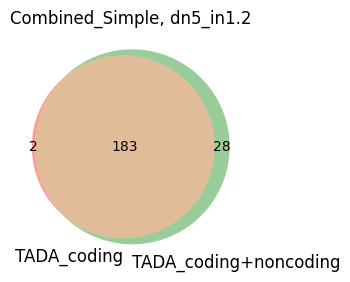

c1: 120, n1: 185, c2: 458, n2: 18128
enrichment: 25.67402336834651, log_enr: 3.2454797168573237, SE_log_enr: 0.07110675606541492, pval: 0.0, z: 45.64235378522447, conf_intervals: (np.float64(22.334063761160394), np.float64(29.51345903582016))
c1: 7, n1: 28, c2: 458, n2: 18128
enrichment: 9.895196506550217, log_enr: 2.292049438033712, SE_log_enr: 0.33056179448489753, pval: 4.096831616305019e-12, z: 6.933800203999163, conf_intervals: (np.float64(5.176660856823913), np.float64(18.91468585858227))


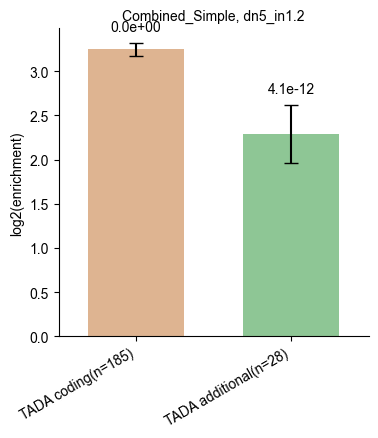

############# Combined_Simple dn10_in1.2


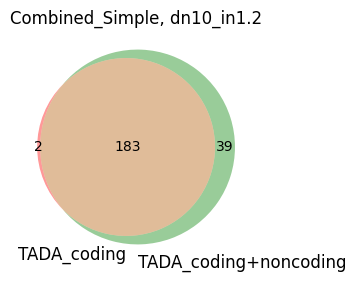

c1: 120, n1: 185, c2: 458, n2: 18128
enrichment: 25.67402336834651, log_enr: 3.2454797168573237, SE_log_enr: 0.07110675606541492, pval: 0.0, z: 45.64235378522447, conf_intervals: (np.float64(22.334063761160394), np.float64(29.51345903582016))
c1: 8, n1: 39, c2: 458, n2: 18128
enrichment: 8.119135595118127, log_enr: 2.094223694703792, SE_log_enr: 0.31857058431247676, pval: 4.904256420437379e-11, z: 6.573813772616332, conf_intervals: (np.float64(4.348525503461), np.float64(15.159244842751429))


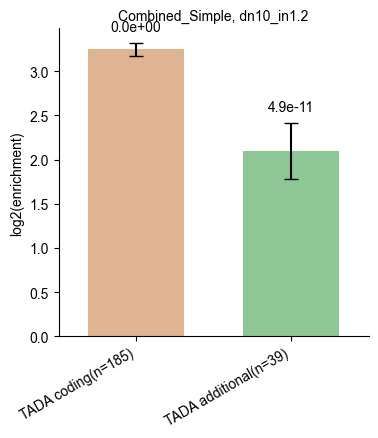

############# Combined_Simple dn15_in1.2


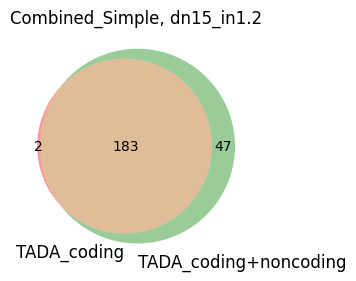

c1: 120, n1: 185, c2: 458, n2: 18128
enrichment: 25.67402336834651, log_enr: 3.2454797168573237, SE_log_enr: 0.07110675606541492, pval: 0.0, z: 45.64235378522447, conf_intervals: (np.float64(22.334063761160394), np.float64(29.51345903582016))
c1: 9, n1: 47, c2: 458, n2: 18128
enrichment: 7.579299451825698, log_enr: 2.0254207747797635, SE_log_enr: 0.3032536202531616, pval: 2.406331333998485e-11, z: 6.6789665135371035, conf_intervals: (np.float64(4.1831083764173105), np.float64(13.73279748244192))


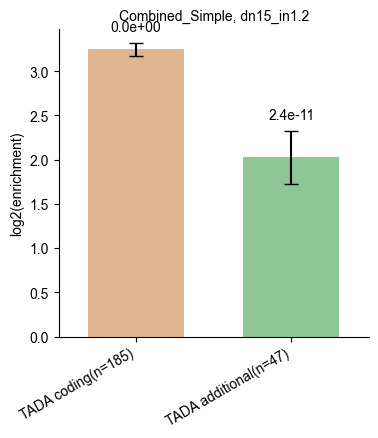

############# Combined_Simple dn10_in1.5


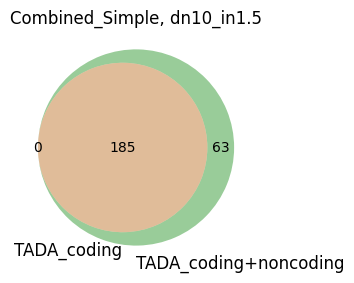

c1: 120, n1: 185, c2: 458, n2: 18128
enrichment: 25.67402336834651, log_enr: 3.2454797168573237, SE_log_enr: 0.07110675606541492, pval: 0.0, z: 45.64235378522447, conf_intervals: (np.float64(22.334063761160394), np.float64(29.51345903582016))
c1: 11, n1: 63, c2: 458, n2: 18128
enrichment: 6.910930893463644, log_enr: 1.9331043455604404, SE_log_enr: 0.2777846609629364, pval: 3.4268872227189793e-12, z: 6.959003203630333, conf_intervals: (np.float64(4.009459381366453), np.float64(11.912071247359268))


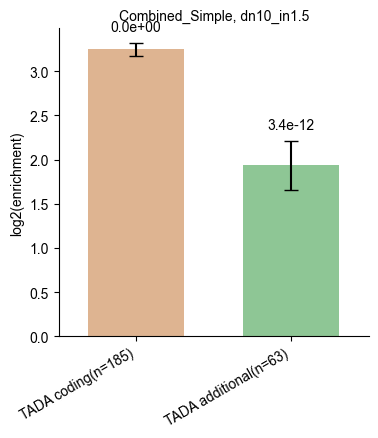

############# Combined_Simple dn15_in1.5


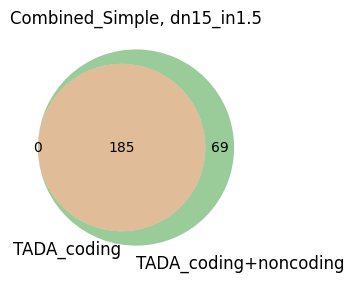

c1: 120, n1: 185, c2: 458, n2: 18128
enrichment: 25.67402336834651, log_enr: 3.2454797168573237, SE_log_enr: 0.07110675606541492, pval: 0.0, z: 45.64235378522447, conf_intervals: (np.float64(22.334063761160394), np.float64(29.51345903582016))
c1: 10, n1: 69, c2: 458, n2: 18128
enrichment: 5.736345800898677, log_enr: 1.7468223875503888, SE_log_enr: 0.29603291912729923, pval: 3.6180736772810937e-09, z: 5.900770740970281, conf_intervals: (np.float64(3.2110838490234164), np.float64(10.247525351135083))


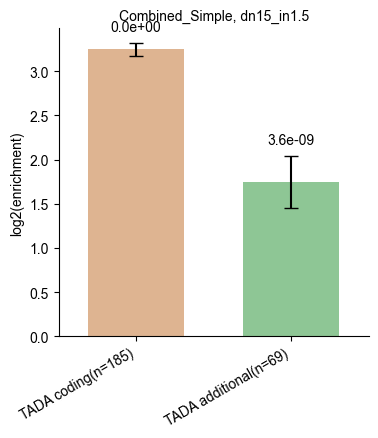

############# Cerebral_Cortex dn5_in1.2


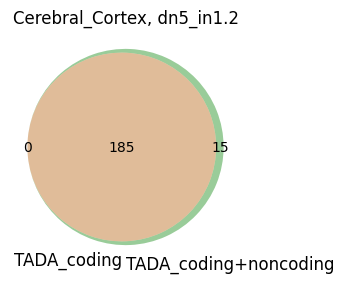

c1: 120, n1: 185, c2: 458, n2: 18128
enrichment: 25.67402336834651, log_enr: 3.2454797168573237, SE_log_enr: 0.07110675606541492, pval: 0.0, z: 45.64235378522447, conf_intervals: (np.float64(22.334063761160394), np.float64(29.51345903582016))
c1: 6, n1: 15, c2: 458, n2: 18128
enrichment: 15.832314410480349, log_enr: 2.7620530672794477, SE_log_enr: 0.3195750973248987, pval: 5.480770011448715e-18, z: 8.642892047597137, conf_intervals: (np.float64(8.462946391116835), np.float64(29.61878381451315))


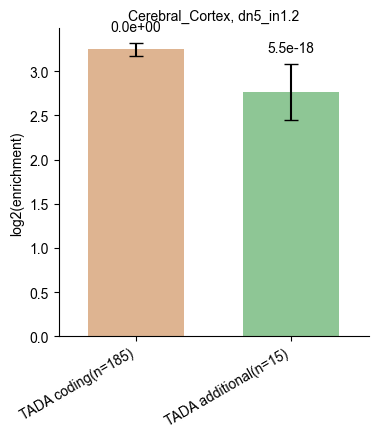

############# Cerebral_Cortex dn10_in1.2


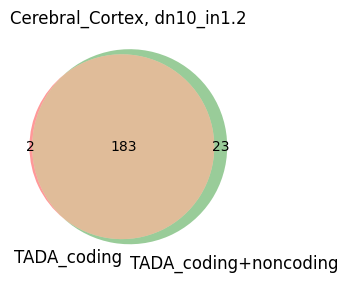

c1: 120, n1: 185, c2: 458, n2: 18128
enrichment: 25.67402336834651, log_enr: 3.2454797168573237, SE_log_enr: 0.07110675606541492, pval: 0.0, z: 45.64235378522447, conf_intervals: (np.float64(22.334063761160394), np.float64(29.51345903582016))
c1: 6, n1: 23, c2: 458, n2: 18128
enrichment: 10.325422441617619, log_enr: 2.334609052452508, SE_log_enr: 0.35400091613909695, pval: 4.254744533456931e-11, z: 6.594923758714721, conf_intervals: (np.float64(5.159192145700073), np.float64(20.664930785087833))


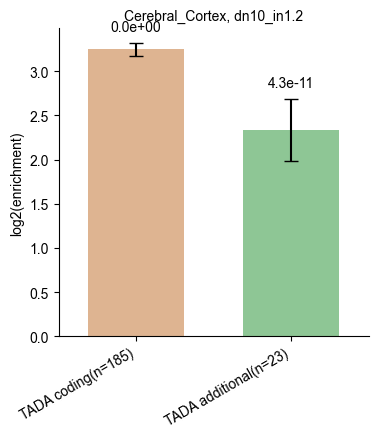

############# Cerebral_Cortex dn15_in1.2


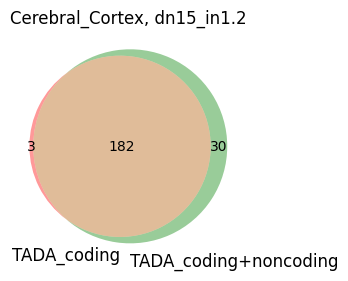

c1: 120, n1: 185, c2: 458, n2: 18128
enrichment: 25.67402336834651, log_enr: 3.2454797168573237, SE_log_enr: 0.07110675606541492, pval: 0.0, z: 45.64235378522447, conf_intervals: (np.float64(22.334063761160394), np.float64(29.51345903582016))
c1: 7, n1: 30, c2: 458, n2: 18128
enrichment: 9.23551673944687, log_enr: 2.2230565665467603, SE_log_enr: 0.3341437600106098, pval: 2.8718911165821392e-11, z: 6.652994407186216, conf_intervals: (np.float64(4.797748912114869), np.float64(17.778081139099253))


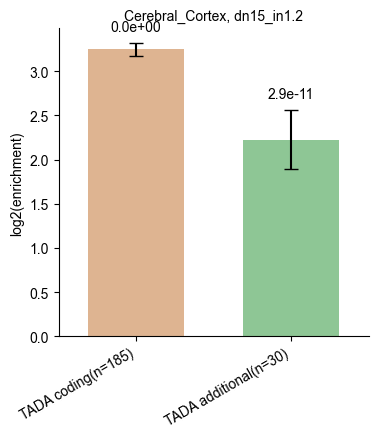

############# Cerebral_Cortex dn10_in1.5


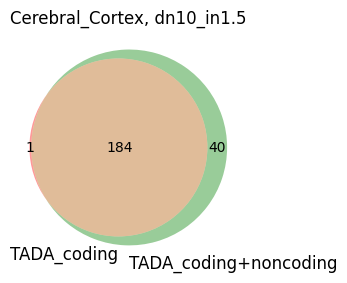

c1: 120, n1: 185, c2: 458, n2: 18128
enrichment: 25.67402336834651, log_enr: 3.2454797168573237, SE_log_enr: 0.07110675606541492, pval: 0.0, z: 45.64235378522447, conf_intervals: (np.float64(22.334063761160394), np.float64(29.51345903582016))
c1: 9, n1: 40, c2: 458, n2: 18128
enrichment: 8.905676855895196, log_enr: 2.1866889223758856, SE_log_enr: 0.2970510965159523, pval: 1.8209702483244847e-13, z: 7.361322506542088, conf_intervals: (np.float64(4.975269159884856), np.float64(15.94106322952442))


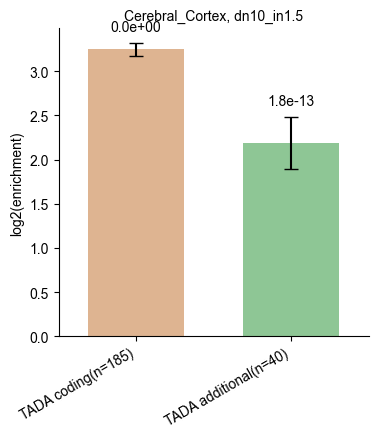

############# Cerebral_Cortex dn15_in1.5


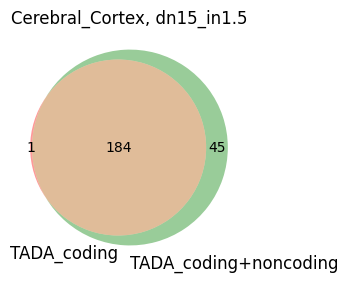

c1: 120, n1: 185, c2: 458, n2: 18128
enrichment: 25.67402336834651, log_enr: 3.2454797168573237, SE_log_enr: 0.07110675606541492, pval: 0.0, z: 45.64235378522447, conf_intervals: (np.float64(22.334063761160394), np.float64(29.51345903582016))
c1: 9, n1: 45, c2: 458, n2: 18128
enrichment: 7.916157205240174, log_enr: 2.0689058867195023, SE_log_enr: 0.301690456791572, pval: 6.997275713681016e-12, z: 6.857710743395642, conf_intervals: (np.float64(4.382430402575574), np.float64(14.299267561955373))


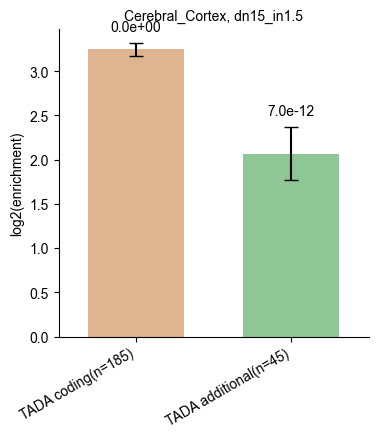

############# Combined dn5_in1.2


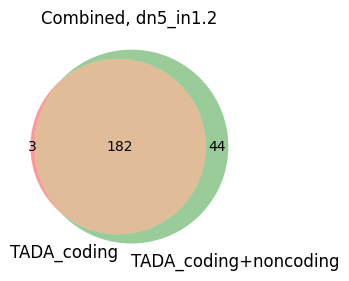

c1: 120, n1: 185, c2: 458, n2: 18128
enrichment: 25.67402336834651, log_enr: 3.2454797168573237, SE_log_enr: 0.07110675606541492, pval: 0.0, z: 45.64235378522447, conf_intervals: (np.float64(22.334063761160394), np.float64(29.51345903582016))
c1: 13, n1: 44, c2: 458, n2: 18128
enrichment: 11.694323144104803, log_enr: 2.459103522696878, SE_log_enr: 0.2373268780101038, pval: 3.70425145682076e-25, z: 10.36167307856376, conf_intervals: (np.float64(7.344497469411914), np.float64(18.620360939370794))


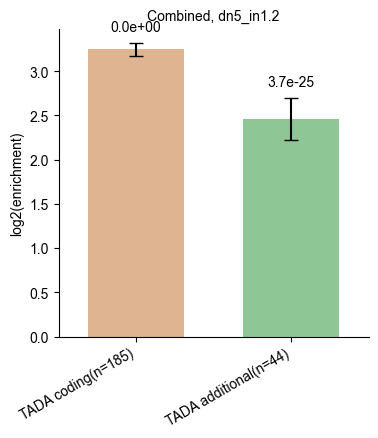

############# Combined dn10_in1.2


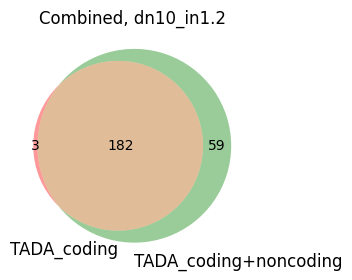

c1: 120, n1: 185, c2: 458, n2: 18128
enrichment: 25.67402336834651, log_enr: 3.2454797168573237, SE_log_enr: 0.07110675606541492, pval: 0.0, z: 45.64235378522447, conf_intervals: (np.float64(22.334063761160394), np.float64(29.51345903582016))
c1: 14, n1: 59, c2: 458, n2: 18128
enrichment: 9.392050921471393, log_enr: 2.2398636848631415, SE_log_enr: 0.2379236468206072, pval: 4.766435044815534e-21, z: 9.414212142402068, conf_intervals: (np.float64(5.891684241003098), np.float64(14.972055002135205))


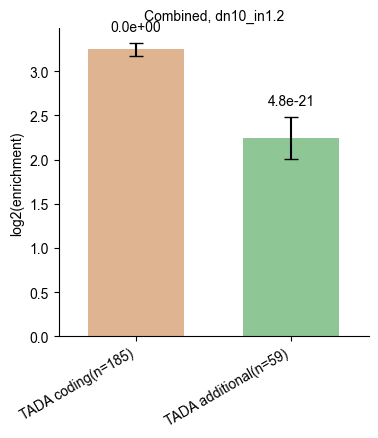

############# Combined dn15_in1.2


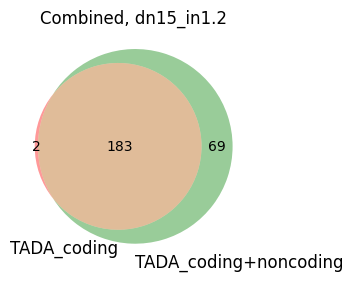

c1: 120, n1: 185, c2: 458, n2: 18128
enrichment: 25.67402336834651, log_enr: 3.2454797168573237, SE_log_enr: 0.07110675606541492, pval: 0.0, z: 45.64235378522447, conf_intervals: (np.float64(22.334063761160394), np.float64(29.51345903582016))
c1: 15, n1: 69, c2: 458, n2: 18128
enrichment: 8.604518701348015, log_enr: 2.152287495658553, SE_log_enr: 0.23302822977849003, pval: 2.5548714573090778e-20, z: 9.236166355056879, conf_intervals: (np.float64(5.449699981596772), np.float64(13.585654684086764))


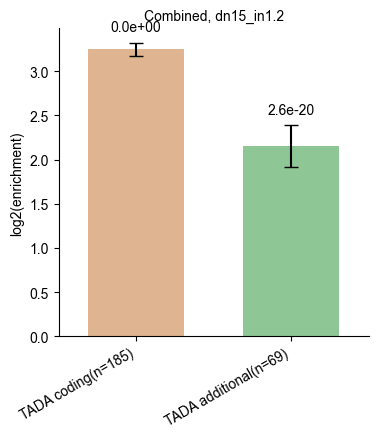

############# Combined dn10_in1.5


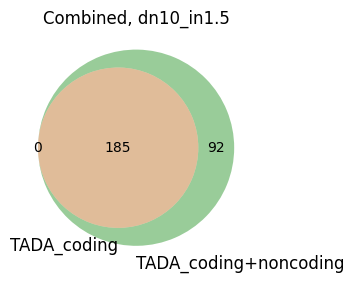

c1: 120, n1: 185, c2: 458, n2: 18128
enrichment: 25.67402336834651, log_enr: 3.2454797168573237, SE_log_enr: 0.07110675606541492, pval: 0.0, z: 45.64235378522447, conf_intervals: (np.float64(22.334063761160394), np.float64(29.51345903582016))
c1: 20, n1: 92, c2: 458, n2: 18128
enrichment: 8.604518701348015, log_enr: 2.152287495658553, SE_log_enr: 0.20312232179853398, pval: 3.1094392025238726e-26, z: 10.59601661009611, conf_intervals: (np.float64(5.778678714686793), np.float64(12.812226762785276))


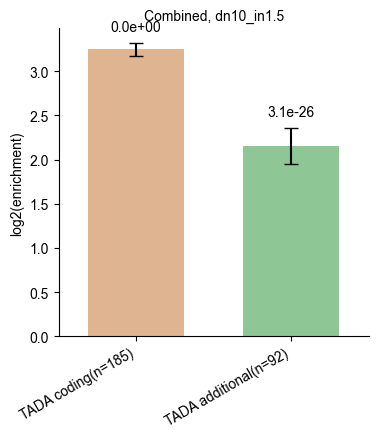

############# Combined dn15_in1.5


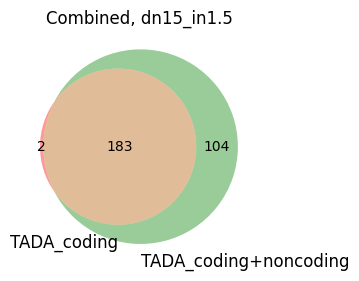

c1: 120, n1: 185, c2: 458, n2: 18128
enrichment: 25.67402336834651, log_enr: 3.2454797168573237, SE_log_enr: 0.07110675606541492, pval: 0.0, z: 45.64235378522447, conf_intervals: (np.float64(22.334063761160394), np.float64(29.51345903582016))
c1: 19, n1: 104, c2: 458, n2: 18128
enrichment: 7.231105139402081, log_enr: 1.9783918791786703, SE_log_enr: 0.21247220326951546, pval: 1.2628022768857906e-20, z: 9.311297424958369, conf_intervals: (np.float64(4.768129134882552), np.float64(10.96633083079768))


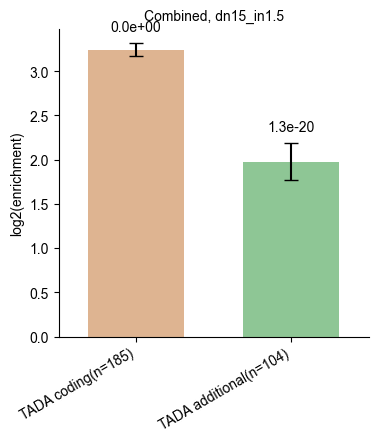

In [ ]:
method_tag = "ScaleByLOEUF"
for sample_tag in ["Combined_Simple", "Cerebral_Cortex", "Combined"]:
    for rr_tag in ["dn5_in1.2", "dn10_in1.2", "dn15_in1.2", "dn10_in1.5", "dn15_in1.5"]:
    
        print("#############", sample_tag, rr_tag)
        df_loeuf = pd.read_csv(f"{tada_output_path}TADA_FuRawSup11_{sample_tag}_Roulette_MR_{method_tag}_{rr_tag}.txt", sep = "\t")
        tada_coding_genes, tada_all_genes_scaledbyloeuf = tada_analysis(df_loeuf, asd_genes, title=f"{sample_tag}, {rr_tag}")

## Heatmap

############# Combined_Simple dn5_in1.2
TADA coding genes: 185
TADA noncoding unique: 28
TADA coding+noncoding genes (l10BF_ASD_EM>0): 157


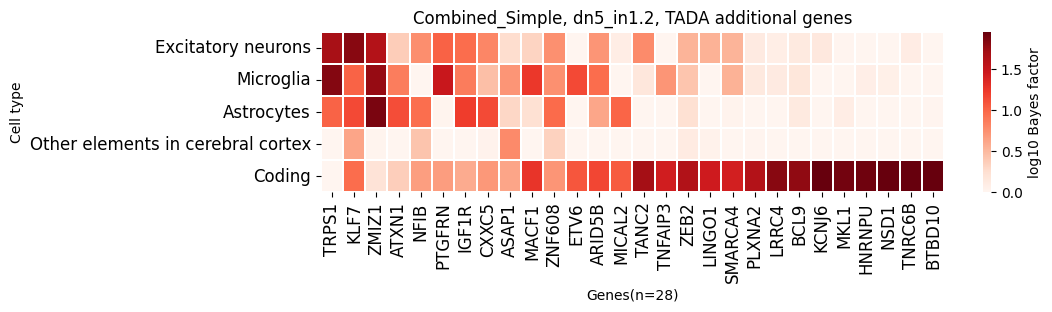

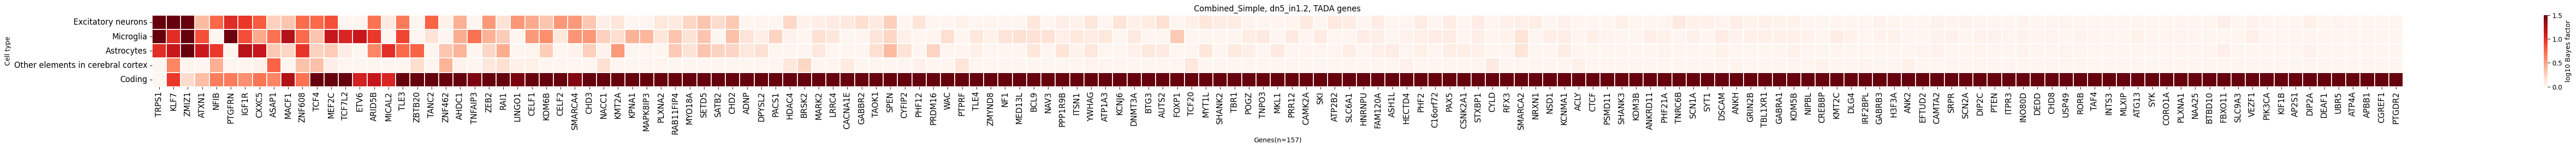

############# Combined_Simple dn10_in1.2
TADA coding genes: 185
TADA noncoding unique: 39
TADA coding+noncoding genes (l10BF_ASD_EM>0): 168


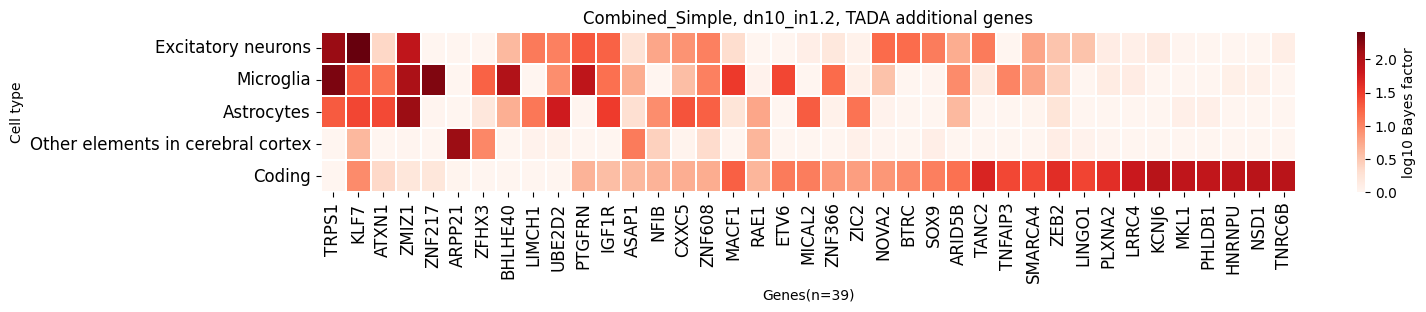

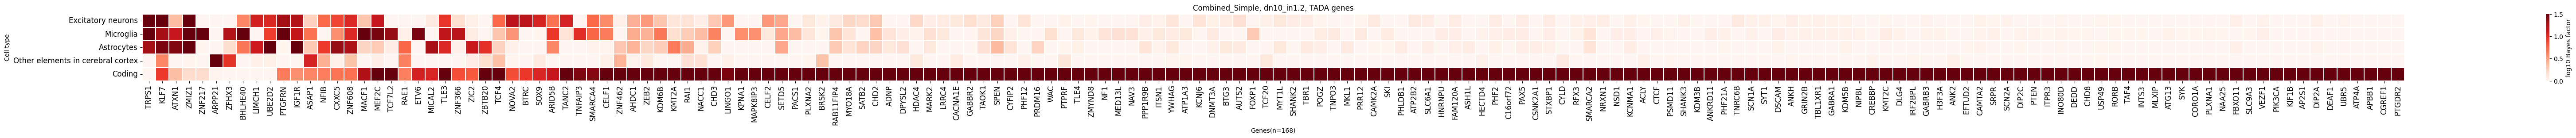

############# Combined_Simple dn15_in1.2
TADA coding genes: 185
TADA noncoding unique: 47
TADA coding+noncoding genes (l10BF_ASD_EM>0): 176


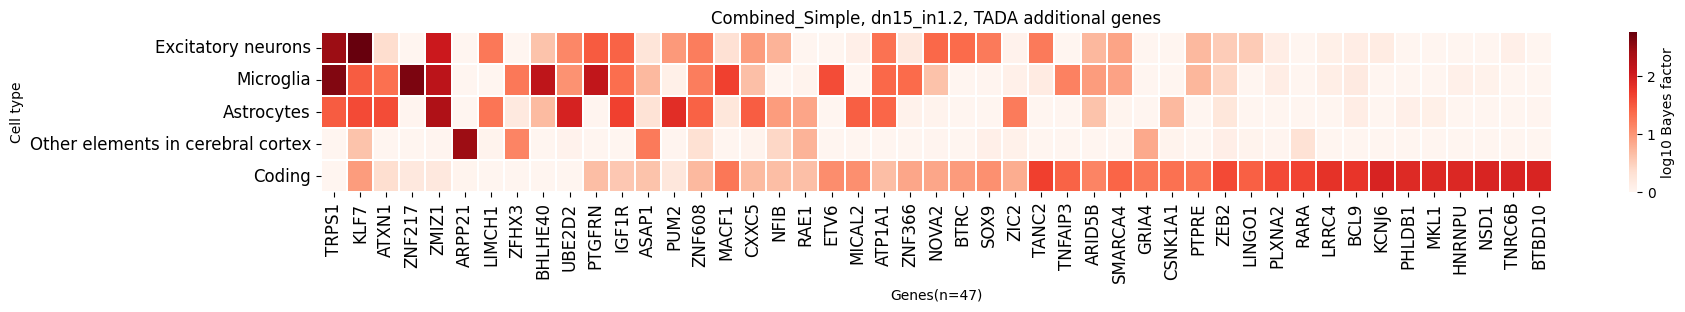

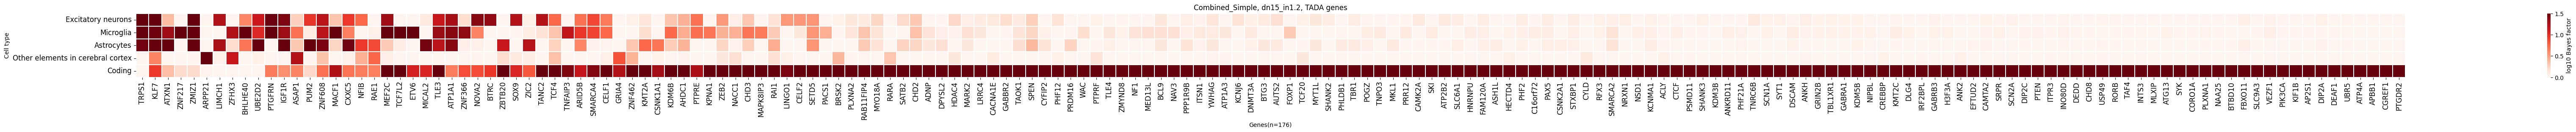

############# Combined_Simple dn10_in1.5
TADA coding genes: 185
TADA noncoding unique: 63
TADA coding+noncoding genes (l10BF_ASD_EM>0): 185


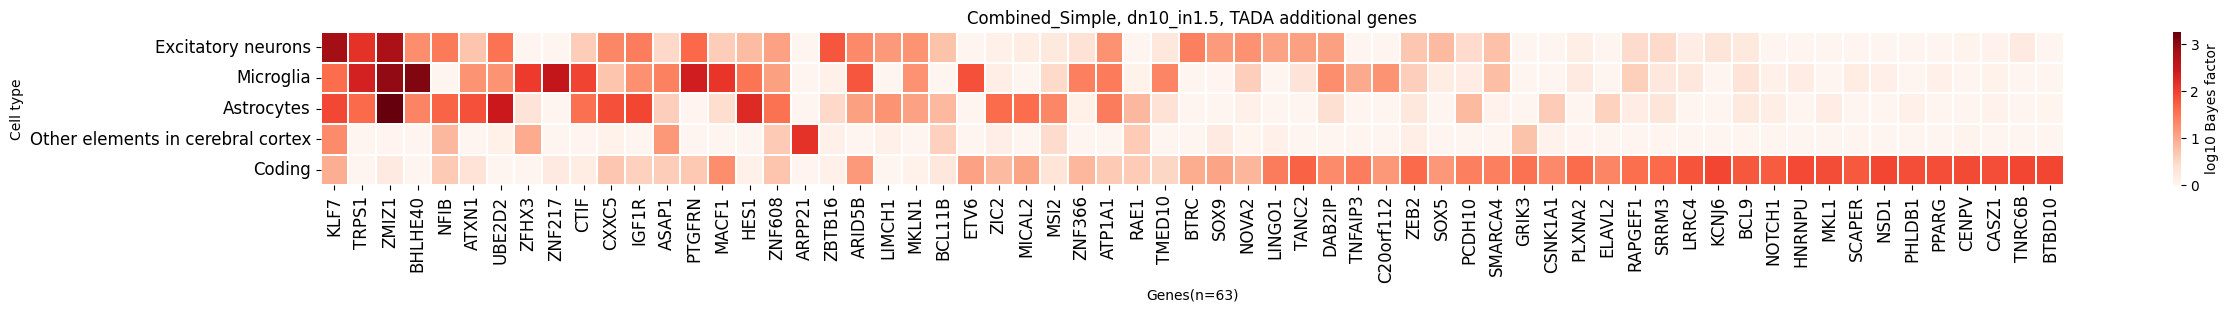

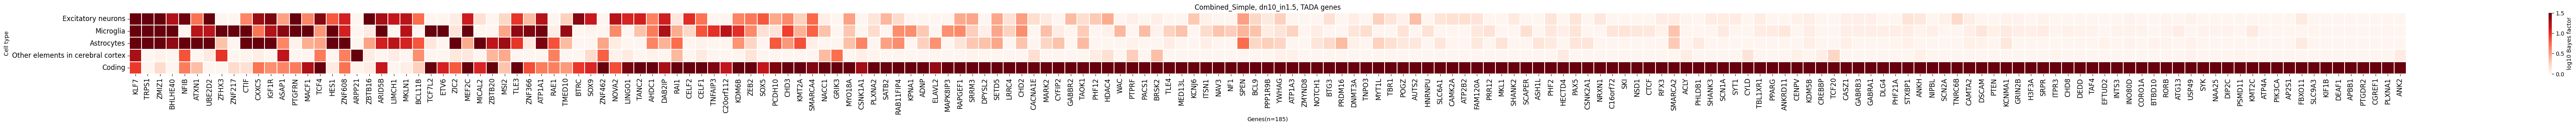

############# Combined_Simple dn15_in1.5
TADA coding genes: 185
TADA noncoding unique: 69
TADA coding+noncoding genes (l10BF_ASD_EM>0): 191


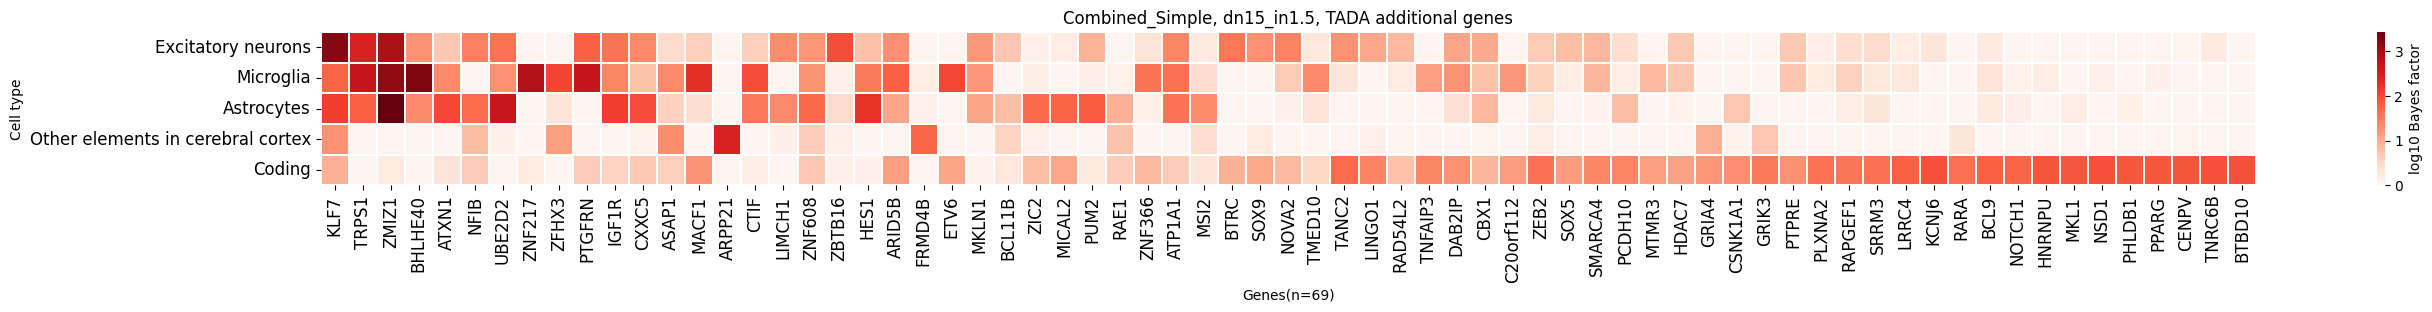

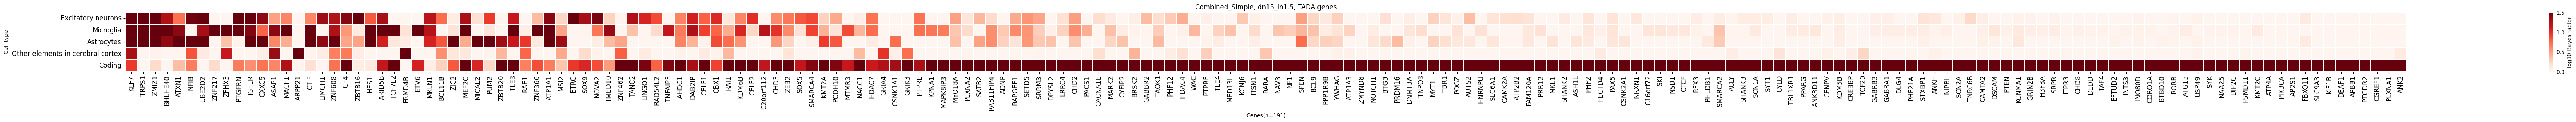

############# Cerebral_Cortex dn5_in1.2
TADA coding genes: 185
TADA noncoding unique: 15
TADA coding+noncoding genes (l10BF_ASD_EM>0): 112


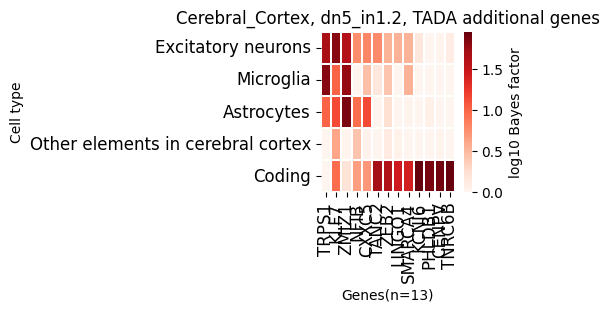

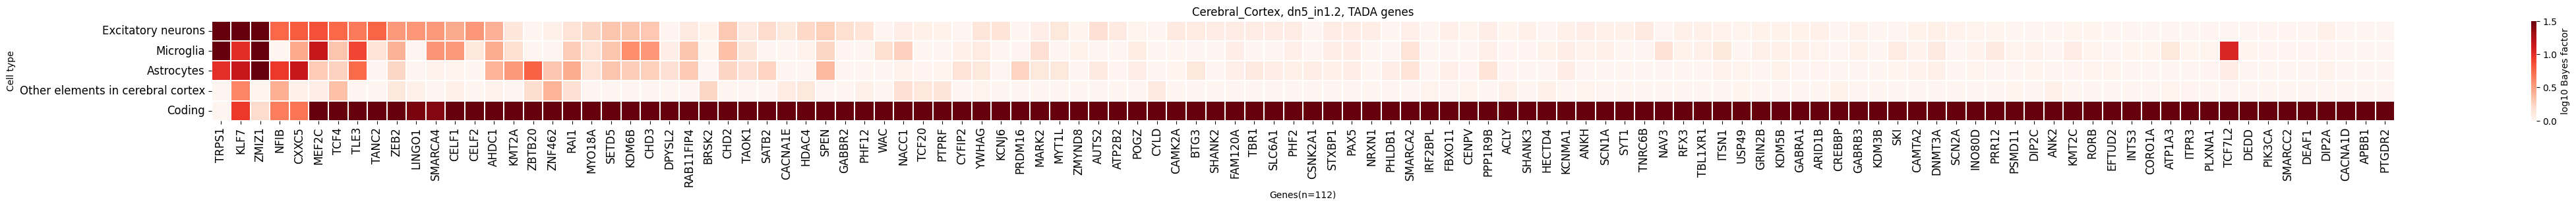

############# Cerebral_Cortex dn10_in1.2
TADA coding genes: 185
TADA noncoding unique: 23
TADA coding+noncoding genes (l10BF_ASD_EM>0): 121


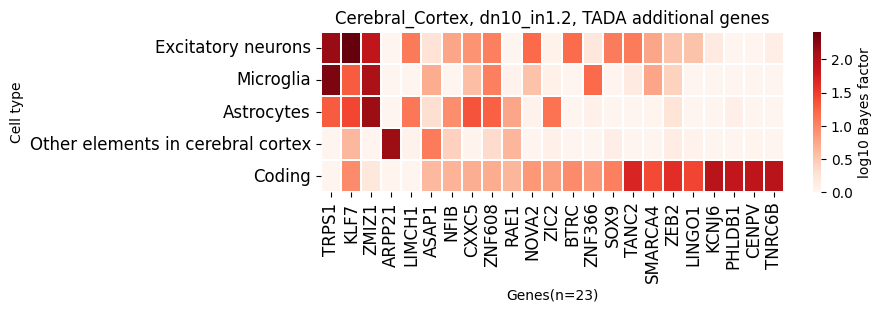

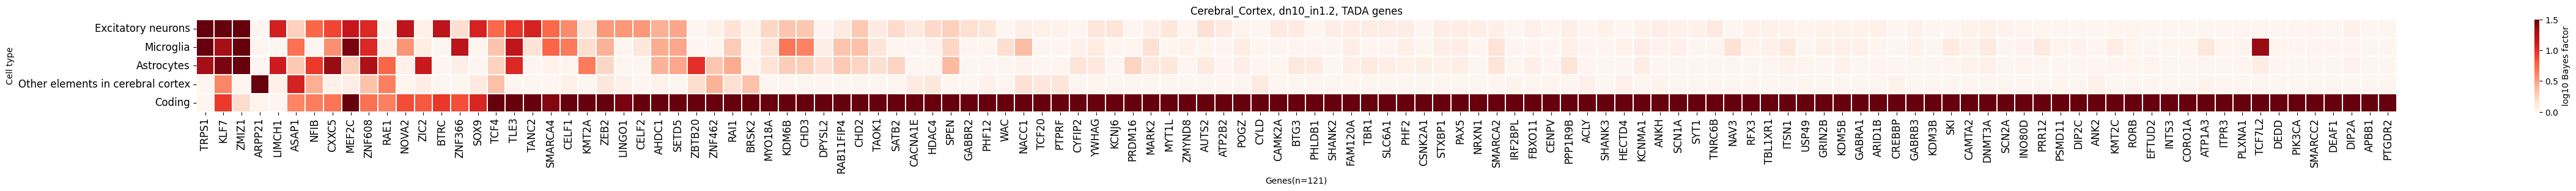

############# Cerebral_Cortex dn15_in1.2
TADA coding genes: 185
TADA noncoding unique: 30
TADA coding+noncoding genes (l10BF_ASD_EM>0): 128


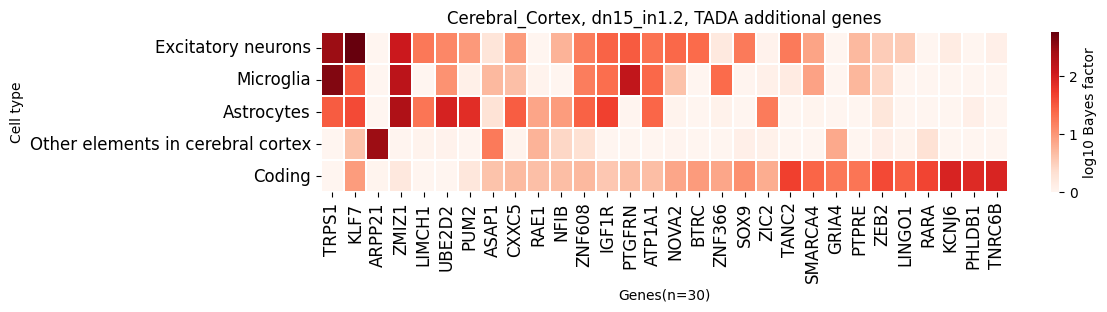

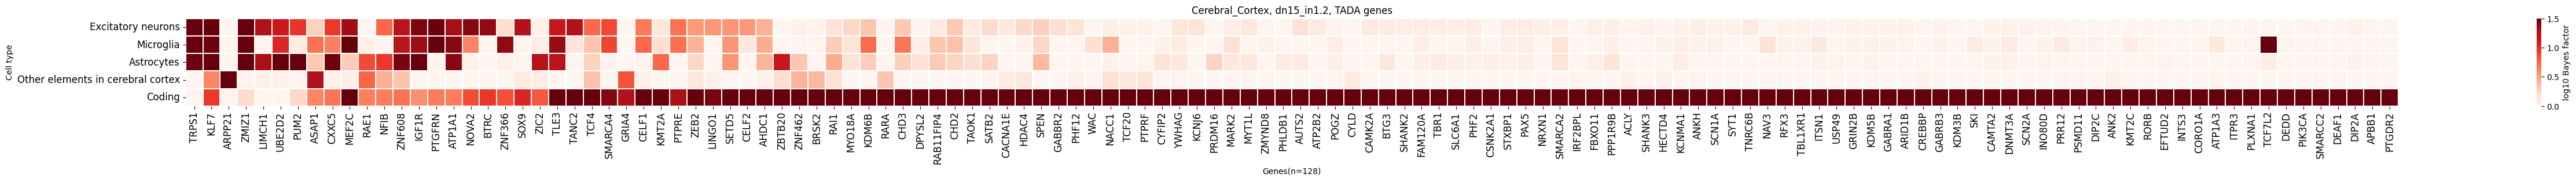

############# Cerebral_Cortex dn10_in1.5
TADA coding genes: 185
TADA noncoding unique: 40
TADA coding+noncoding genes (l10BF_ASD_EM>0): 129


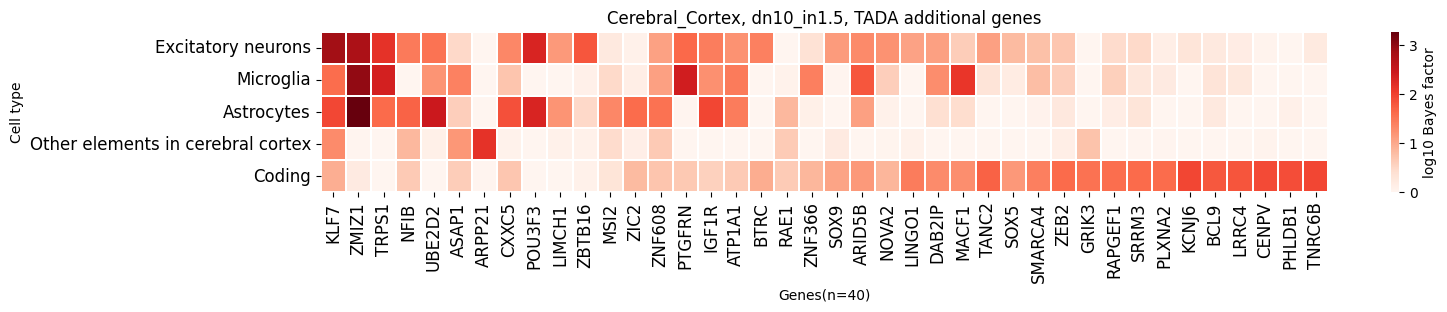

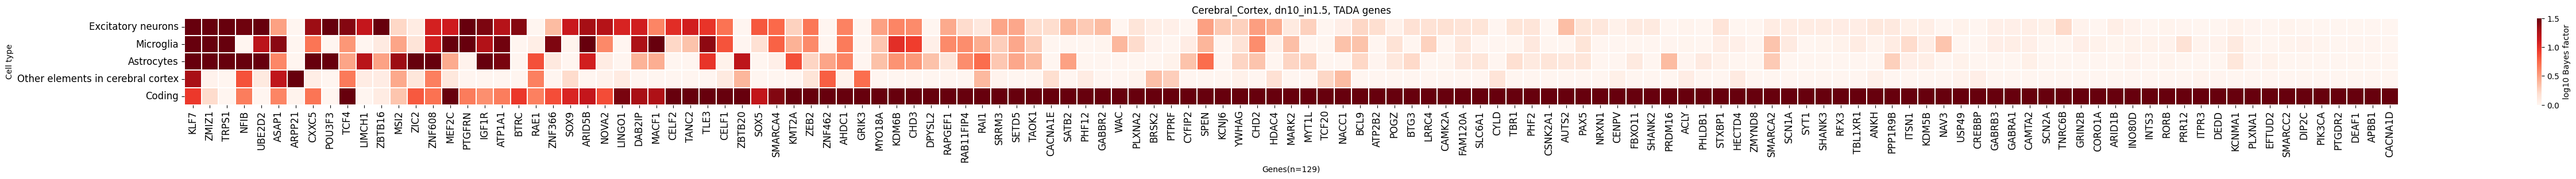

############# Cerebral_Cortex dn15_in1.5
TADA coding genes: 185
TADA noncoding unique: 45
TADA coding+noncoding genes (l10BF_ASD_EM>0): 134


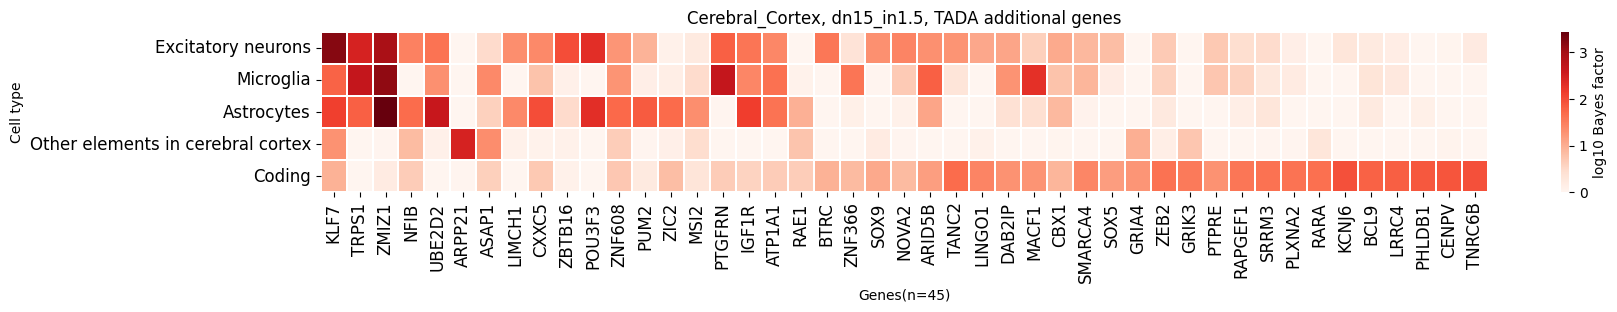

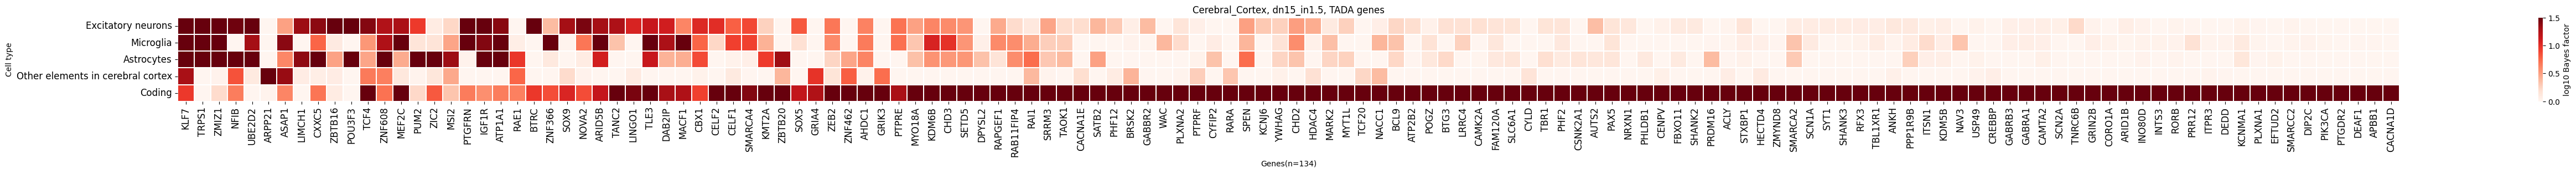

############# Combined dn5_in1.2
TADA coding genes: 185
TADA noncoding unique: 44
TADA coding+noncoding genes (l10BF_ASD_EM>0): 173


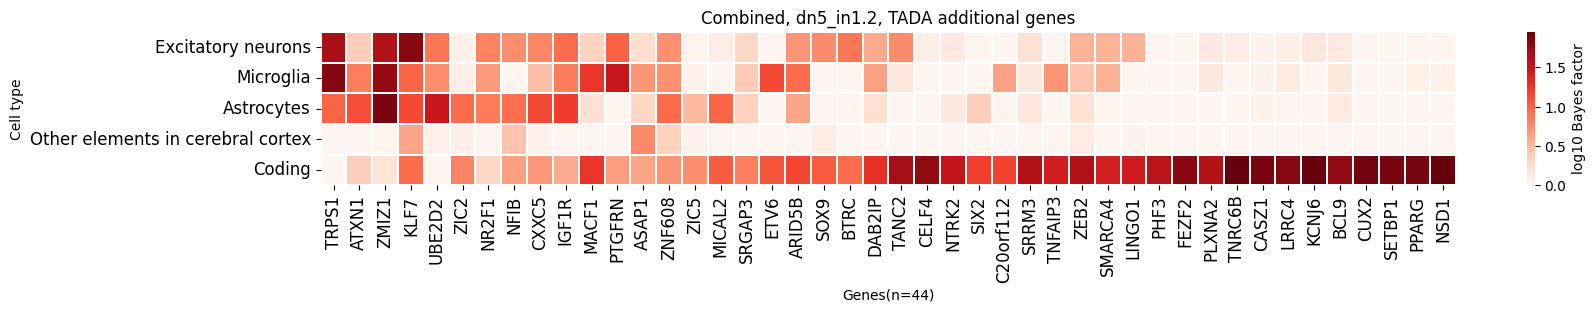

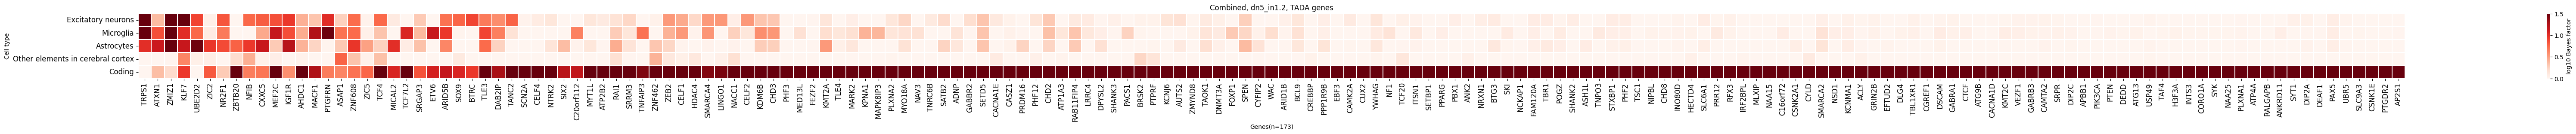

############# Combined dn10_in1.2
TADA coding genes: 185
TADA noncoding unique: 59
TADA coding+noncoding genes (l10BF_ASD_EM>0): 188


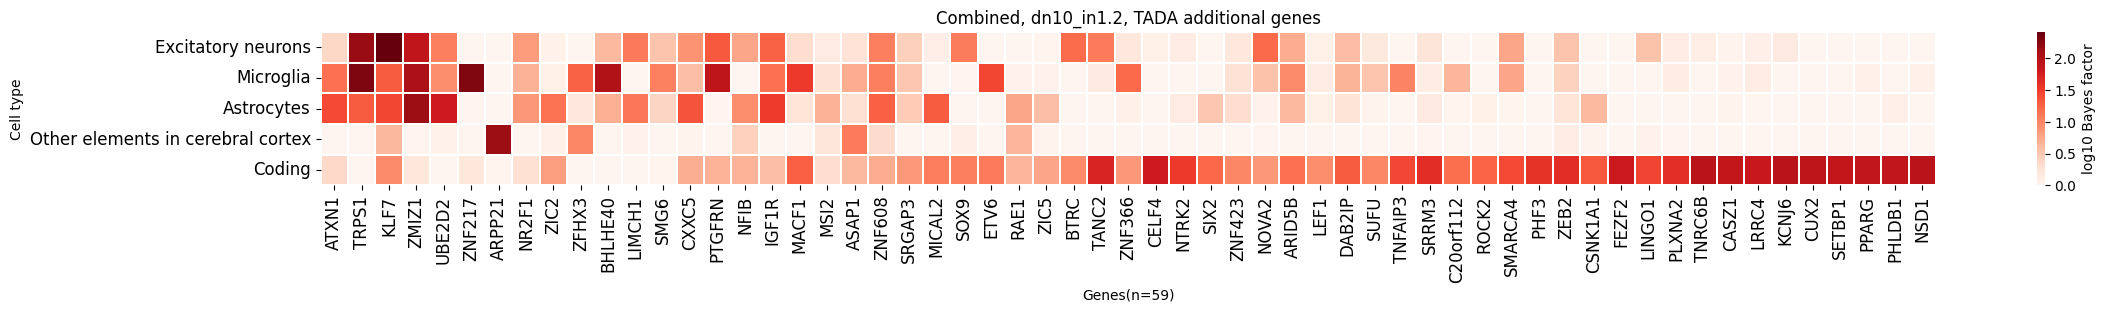

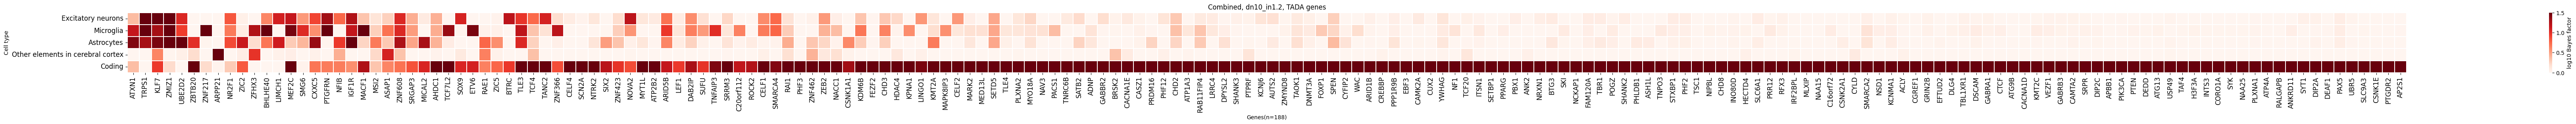

############# Combined dn15_in1.2
TADA coding genes: 185
TADA noncoding unique: 69
TADA coding+noncoding genes (l10BF_ASD_EM>0): 198


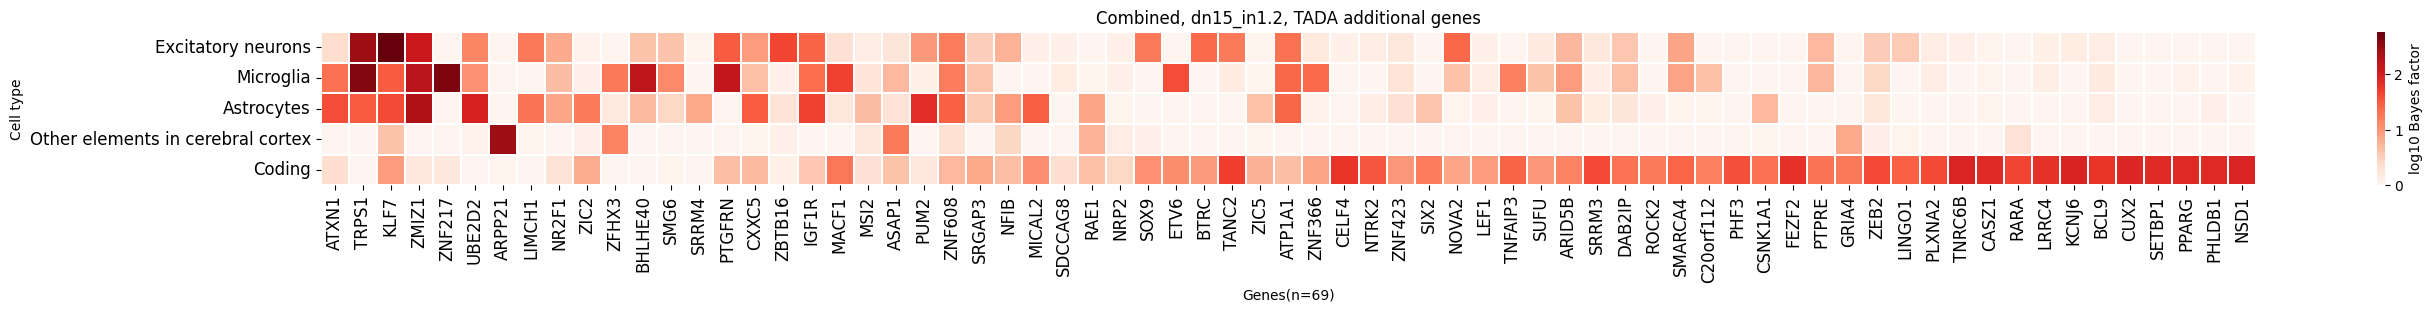

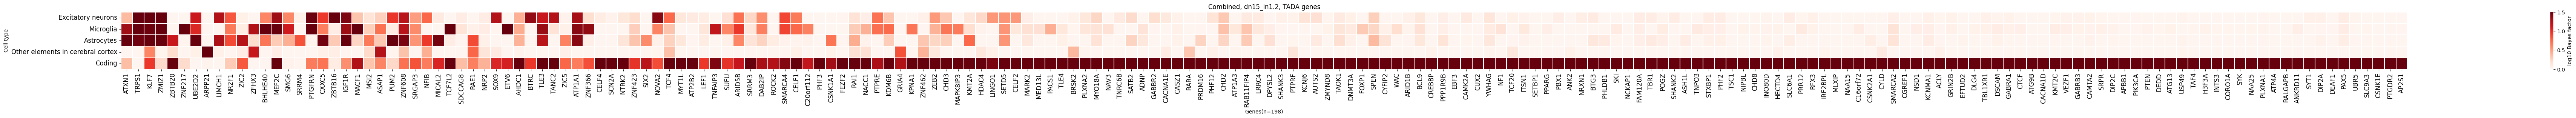

############# Combined dn10_in1.5
TADA coding genes: 185
TADA noncoding unique: 92
TADA coding+noncoding genes (l10BF_ASD_EM>0): 211


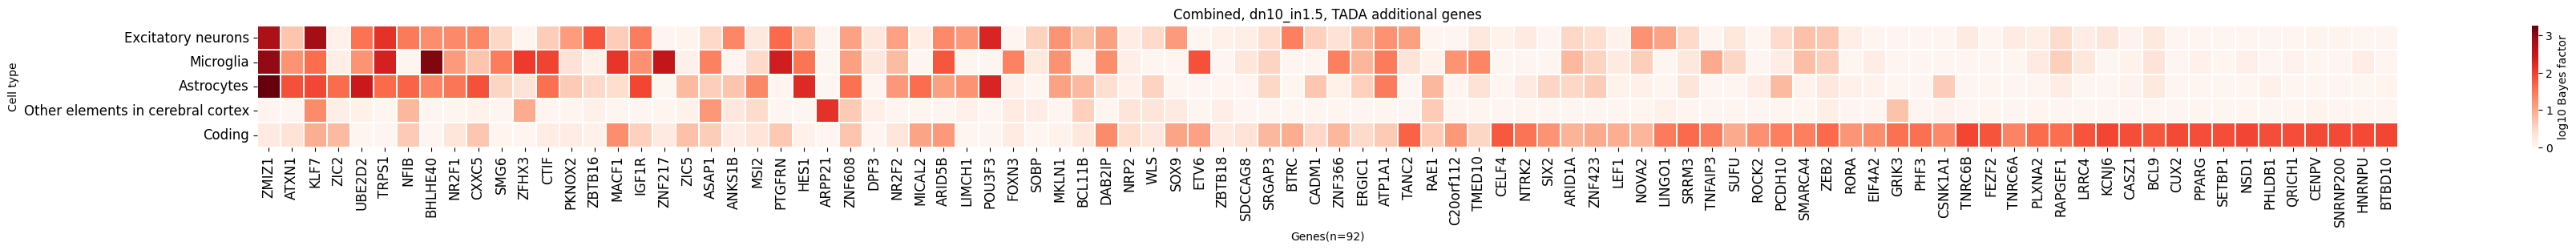

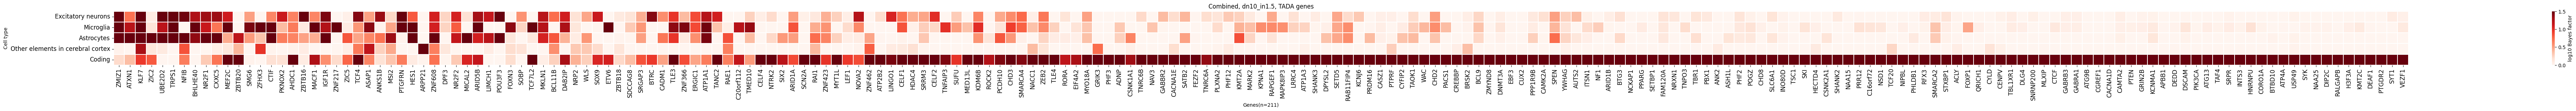

############# Combined dn15_in1.5
TADA coding genes: 185
TADA noncoding unique: 104
TADA coding+noncoding genes (l10BF_ASD_EM>0): 223


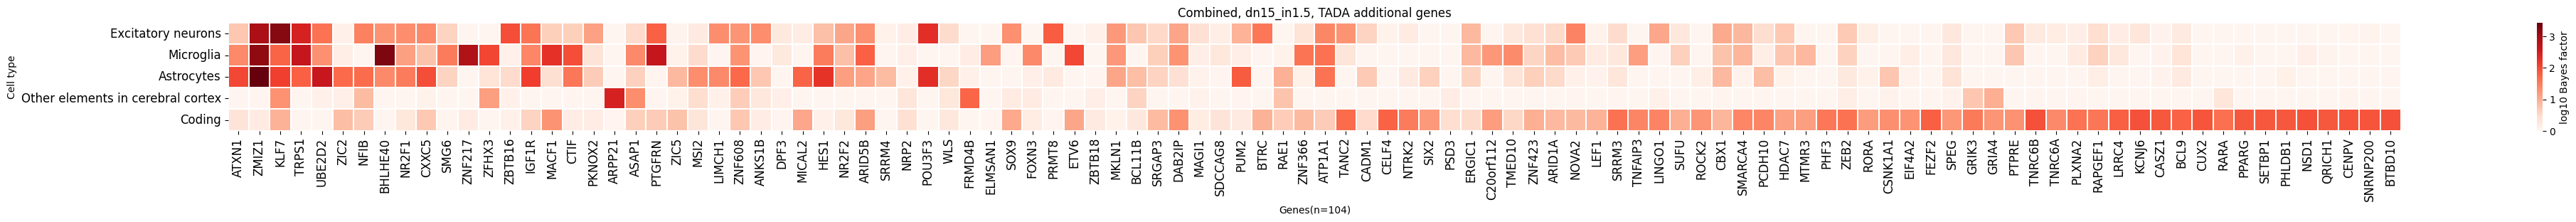

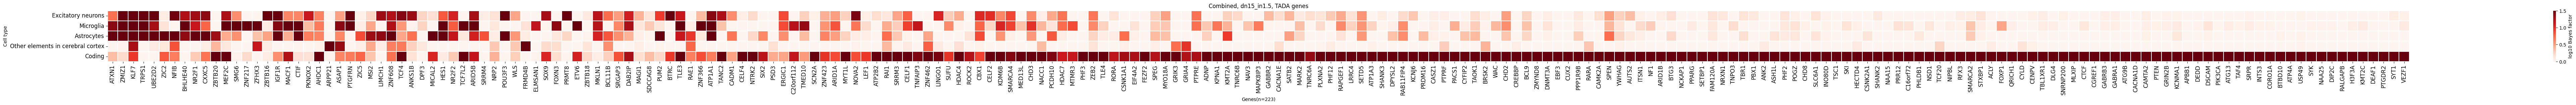

In [112]:
method_tag = "ScaleByLOEUF"
for sample_tag in ["Combined_Simple", "Cerebral_Cortex", "Combined"]:
    for rr_tag in ["dn5_in1.2", "dn10_in1.2", "dn15_in1.2", "dn10_in1.5", "dn15_in1.5"]:
        print("#############", sample_tag, rr_tag)
        df = pd.read_csv(f"{tada_output_path}TADA_FuRawSup11_{sample_tag}_Roulette_MR_{method_tag}_{rr_tag}.txt", sep = "\t")
        df["l10BF_ASD_Coding"] = df[["l10BF_ASD_PTV",	"l10BF_ASD_misB",	"l10BF_ASD_misA", "l10BF_ASD_DEL", "l10BF_ASD_DUP"]].sum(axis=1)
        df = df[["gene", "gene_id", "FDR_TADA_ASD", "FDR_TADA_ASD_AddEM", "l10BF_ASD_Coding", "l10BF_ASD_EM"]]
        tada_coding_genes = set(df[df["FDR_TADA_ASD"] < 0.05]["gene"])
        tada_all_genes = set(df[df["FDR_TADA_ASD_AddEM"] < 0.05]["gene"])
        tada_all_genes_unique = tada_all_genes - tada_coding_genes
        print("TADA coding genes:",len(tada_coding_genes))
        print("TADA noncoding unique:", len(tada_all_genes_unique))
        for x in ["Deconv_Excitatory_Neurons", "Deconv_Microglia", "Deconv_Astrocytes", "Other_Cerebral_Cortex"]:
            df_tmp = pd.read_csv(f"{tada_output_path}TADA_FuScaled_{x}_Roulette_MR_{method_tag}_{rr_tag}.txt", sep = "\t")
            x = x.replace("Deconv_", "")
            df_tmp[f"l10BF_ASD_EM_{x}"] = df_tmp.apply(lambda x: np.log10(x["bf.dn.em"] * x["bf.in.em"]), axis=1)
            df = pd.merge(df, df_tmp[["gene_id", f"l10BF_ASD_EM_{x}"]], on="gene_id")
        df = df.sort_values(by=["l10BF_ASD_EM", "l10BF_ASD_EM_Excitatory_Neurons", "l10BF_ASD_EM_Microglia", "l10BF_ASD_EM_Astrocytes", "l10BF_ASD_EM_Other_Cerebral_Cortex", "l10BF_ASD_Coding"], ascending=False)
        df = df[df["l10BF_ASD_EM"] > 0]
        df_long = df[df["gene"].isin(tada_all_genes)]
        df_short = df[df["gene"].isin(tada_all_genes_unique)]
        print("TADA coding+noncoding genes (l10BF_ASD_EM>0):", df_long.shape[0])
        lbf_heatmap(df_short, figtitle= f"{sample_tag}, {rr_tag}, TADA additional genes")
        lbf_heatmap(df_long, figtitle= f"{sample_tag}, {rr_tag}, TADA genes", vmax=1.5)

## Violin (Haploinsufficiency analysis)

28 185
/Genomics/argo/users/yz8667/Autism_network_integration/data/TADA/output/InhAll_DNVAll/TADA_FuRawSup11_Combined_Simple_Roulette_MR_ScaleByLOEUF_dn5_in1.2_codingsig.txt
TADA_coding: total genes = 185
/Genomics/argo/users/yz8667/Autism_network_integration/data/TADA/output/InhAll_DNVAll/TADA_FuRawSup11_Combined_Simple_Roulette_MR_ScaleByLOEUF_dn5_in1.2_codinginsig.txt
TADA_additional: total genes = 28
before haploinsufficiency annotation: 18852
after haploinsufficiency annotation: 11503


/Genomics/argo/users/yz8667/src/all_function_py3.py:3717: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x = put_x, y = put_y, data = df, palette = color_dict, cut = cut, scale = scale, linewidth = linewidth, saturation = 1, \
/Genomics/argo/users/yz8667/src/all_function_py3.py:3717: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='area'` for the same effect.
  sns.violinplot(x = put_x, y = put_y, data = df, palette = color_dict, cut = cut, scale = scale, linewidth = linewidth, saturation = 1, \


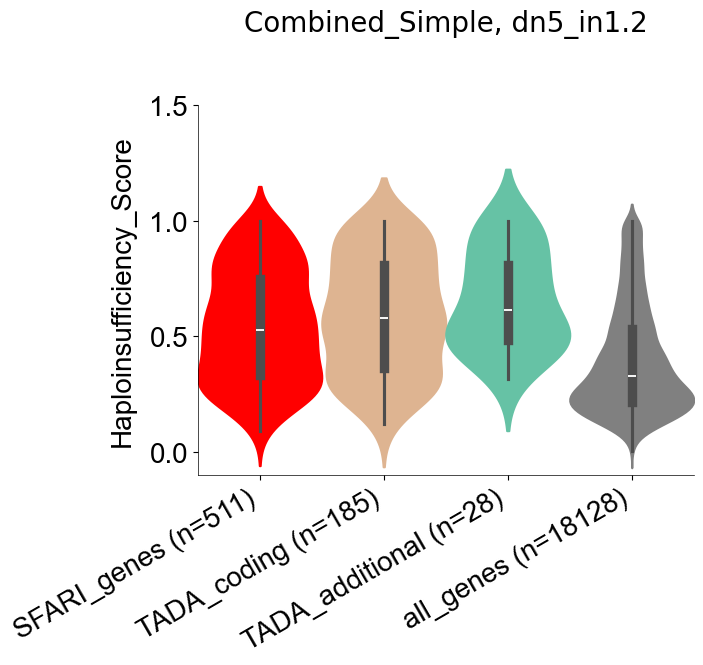

,group_x,group_y,pval
0,SFARI_genes (n=511),TADA_coding (n=185),7.419632e-02
1,SFARI_genes (n=511),TADA_additional (n=28),3.279898e-02
2,SFARI_genes (n=511),all_genes (n=18128),1.192437e-32
3,TADA_coding (n=185),TADA_additional (n=28),2.763833e-01
4,TADA_coding (n=185),all_genes (n=18128),9.238898e-20
5,TADA_additional (n=28),all_genes (n=18128),2.046584e-07


In [315]:
dr = "/Genomics/argo/users/yz8667/Autism_network_integration/data/TADA/output/InhAll_DNVAll/"
method_tag = "ScaleByLOEUF"
sample_tag = "Combined_Simple"
rr_tag = "dn5_in1.2"
df = pd.read_csv(f"{dr}TADA_FuRawSup11_{sample_tag}_Roulette_MR_{method_tag}_{rr_tag}.txt", sep = "\t")
df_coding_strong = df[df["FDR_TADA_ASD"] < 0.05]
df_coding_weak = df[(df["FDR_TADA_ASD_AddEM"] < 0.05) & (df["FDR_TADA_ASD"] >= 0.05)]
print(df_coding_weak.shape[0], df_coding_strong.shape[0])
df_coding_strong.to_csv(f"{dr}TADA_FuRawSup11_{sample_tag}_Roulette_MR_{method_tag}_{rr_tag}_codingsig.txt", sep = "\t", index = False)
df_coding_weak.to_csv(f"{dr}TADA_FuRawSup11_{sample_tag}_Roulette_MR_{method_tag}_{rr_tag}_codinginsig.txt", sep = "\t", index = False)


tag2file = {"TADA_coding": f"{dr}TADA_FuRawSup11_{sample_tag}_Roulette_MR_{method_tag}_{rr_tag}_codingsig.txt",
        "TADA_additional": f"{dr}TADA_FuRawSup11_{sample_tag}_Roulette_MR_{method_tag}_{rr_tag}_codinginsig.txt"}
tag2color = {"TADA_coding": "#deb491", "TADA_additional": "#66c2a5"}
df_output, df_unique = violin_analysis_new(tag2file, df_idmap, df_haplo, asd_genes, all_genes, title = f"{sample_tag}, {rr_tag}", fdr_col = "FDR_TADA_ASD_AddEM", gene_col = "gene", color_dict = tag2color)

## Try various FDR cutoffs

############# Combined_Simple dn5_in1.2


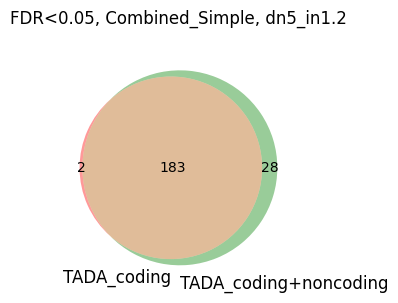

c1: 120, n1: 185, c2: 458, n2: 18128
enrichment: 25.67402336834651, log_enr: 3.2454797168573237, SE_log_enr: 0.07110675606541492, pval: 0.0, z: 45.64235378522447, conf_intervals: (np.float64(22.334063761160394), np.float64(29.51345903582016))
c1: 7, n1: 28, c2: 458, n2: 18128
enrichment: 9.895196506550217, log_enr: 2.292049438033712, SE_log_enr: 0.33056179448489753, pval: 4.096831616305019e-12, z: 6.933800203999163, conf_intervals: (np.float64(5.176660856823913), np.float64(18.91468585858227))


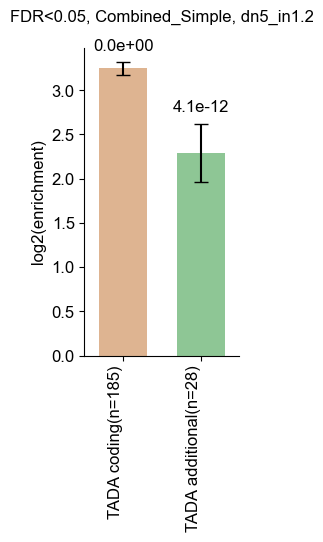

############# Combined_Simple dn5_in1.2


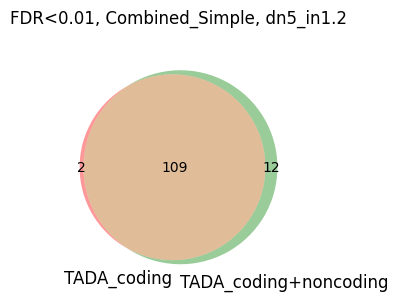

c1: 89, n1: 111, c2: 458, n2: 18128
enrichment: 31.735945552539437, log_enr: 3.457449967573408, SE_log_enr: 0.06599385484565408, pval: 0.0, z: 52.39048356335094, conf_intervals: (np.float64(27.88543163618825), np.float64(36.118151343466906))
c1: 6, n1: 12, c2: 458, n2: 18128
enrichment: 19.790393013100434, log_enr: 2.9851966185936574, SE_log_enr: 0.29233811958680966, pval: 1.7620830942794477e-24, z: 10.211451803866463, conf_intervals: (np.float64(11.15875546091407), np.float64(35.098865369426406))


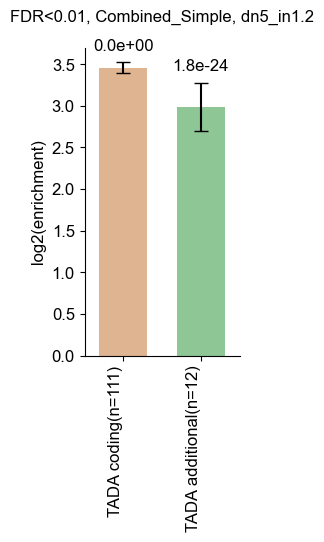

############# Combined_Simple dn5_in1.2


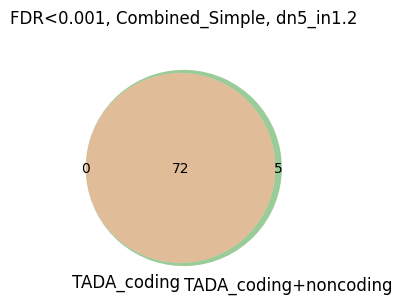

c1: 66, n1: 72, c2: 458, n2: 18128
enrichment: 36.28238719068413, log_enr: 3.5913324221639726, SE_log_enr: 0.05823116942707538, pval: 0.0, z: 61.67371284997985, conf_intervals: (np.float64(32.369008178037674), np.float64(40.66888960619754))
c1: 4, n1: 5, c2: 458, n2: 18128
enrichment: 31.664628820960697, log_enr: 3.4552002478393926, SE_log_enr: 0.22831610287103818, pval: 9.751515752811371e-52, z: 15.133405854386995, conf_intervals: (np.float64(20.24097285295534), np.float64(49.53559918553124))


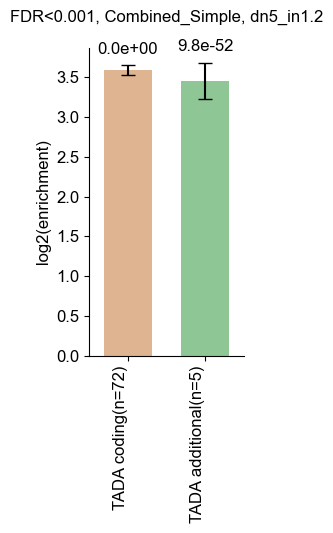

In [ ]:
method_tag = "ScaleByLOEUF"
sample_tag = "Combined_Simple"
rr_tag = "dn5_in1.2"
for significant_threshold in [0.05, 0.01, 0.001]:
        print("#############", sample_tag, rr_tag)
        df_loeuf = pd.read_csv(f"{tada_output_path}TADA_FuRawSup11_{sample_tag}_Roulette_MR_{method_tag}_{rr_tag}.txt", sep = "\t")
        tada_coding_genes, tada_all_genes_scaledbyloeuf = tada_analysis(df_loeuf, asd_genes, title=f"FDR<{significant_threshold}, {sample_tag}, {rr_tag}\n", significant_threshold=significant_threshold)

# WGS-only analysis

## UCSF coding count, Roulette mutation rate with gnomAD<=0 filter

In [ ]:
misA mutation rate = gnomad missense mutation rate * (misA count / missense count)
                   = gnomad missense mutation rate * (misA count / total number of coding variants) *  (total number of coding variants / total missense count)


,gene_id,FDR_TADA_ASD,l10BF_ASD_Coding,gene,LOEUF,pLI,bf.dn.ptv,bf.in.ptv,bf.dn.misb,bf.in.misb,bf.dn.misa,bf.in.misa,bf.dn.em,bf.in.em,bf,FDR_TADA_ASD_AddEM,pval,l10BF_ASD_EM
0,ENSG00000108510,0.406878,0.935454,MED13,0.030,1.000000e+00,4.683105,1.750161,1.000000,1.000000,1.0,1.051578,1.0,1.000000,8.618934,0.405824,0.009007,0.000000
1,ENSG00000164190,0.921183,0.000000,NIPBL,0.032,1.000000e+00,1.000000,1.000000,1.000000,1.000000,1.0,1.000000,1.0,1.079713,1.079713,0.896555,0.451721,0.033308
2,ENSG00000108055,0.288594,1.242701,SMC3,0.037,1.000000e+00,1.000000,1.000000,14.066533,1.243122,1.0,1.000000,1.0,1.012382,17.702927,0.277759,0.003723,0.005344
3,ENSG00000125107,0.834258,0.170883,CNOT1,0.038,1.000000e+00,1.000000,1.000000,1.000000,1.482118,1.0,1.000000,1.0,1.000000,1.482118,0.834030,0.171779,0.000000
4,ENSG00000117000,0.489351,0.725101,RLF,0.040,1.000000e+00,4.968376,1.000000,1.000000,1.000000,1.0,1.068775,1.0,1.214362,6.448355,0.464260,0.012645,0.084348
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17589,ENSG00000165474,0.918223,0.000000,GJB2,1.984,6.562000e-16,1.000000,1.000000,1.000000,1.000000,1.0,1.000000,1.0,1.000000,1.000000,0.916470,0.748498,0.000000
17590,ENSG00000150244,0.932292,0.000000,TRIM48,1.985,1.099500e-27,1.000000,1.000000,1.000000,1.000000,1.0,1.000000,1.0,1.000000,1.000000,0.921054,0.871387,0.000000
17591,ENSG00000231924,0.921181,0.000000,PSG1,1.986,1.624200e-29,1.000000,1.000000,1.000000,1.000000,1.0,1.000000,1.0,1.000000,1.000000,0.917946,0.784243,0.000000
17592,ENSG00000099949,0.689734,0.403909,LZTR1,1.994,1.021100e-92,1.682462,1.000000,1.000000,1.329072,1.0,1.133484,1.0,1.000000,2.534599,0.709224,0.055944,0.000000


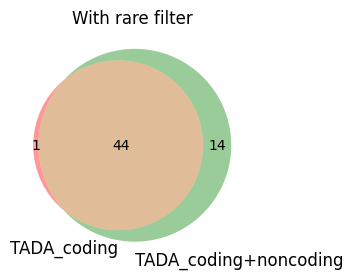

c1: 34, n1: 45, c2: 460, n2: 17588
enrichment: 28.888502415458937, log_enr: 3.363443675663402, SE_log_enr: 0.09647071358303179, pval: 2.5300292571903922e-266, z: 34.86491962940136, conf_intervals: (np.float64(23.911620435788304), np.float64(34.90125539793699))
c1: 8, n1: 14, c2: 460, n2: 17588
enrichment: 21.84844720496894, log_enr: 3.0841298528821373, SE_log_enr: 0.235984077147141, pval: 4.936354960061639e-39, z: 13.069228611382613, conf_intervals: (np.float64(13.757849868639012), np.float64(34.69689303387763))


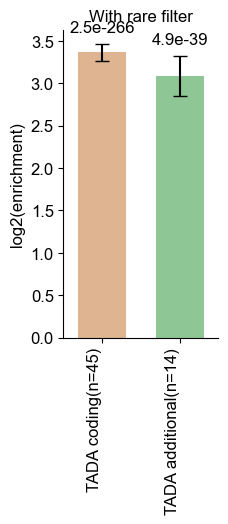

TADA coding+noncoding genes (l10BF_ASD_EM>0): 46


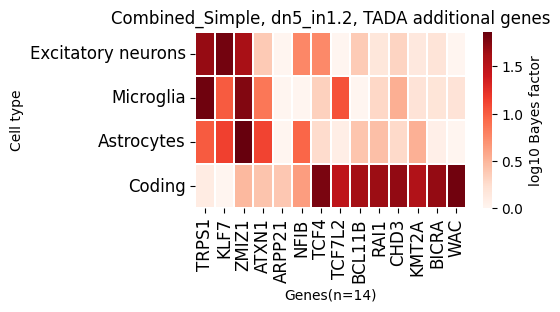

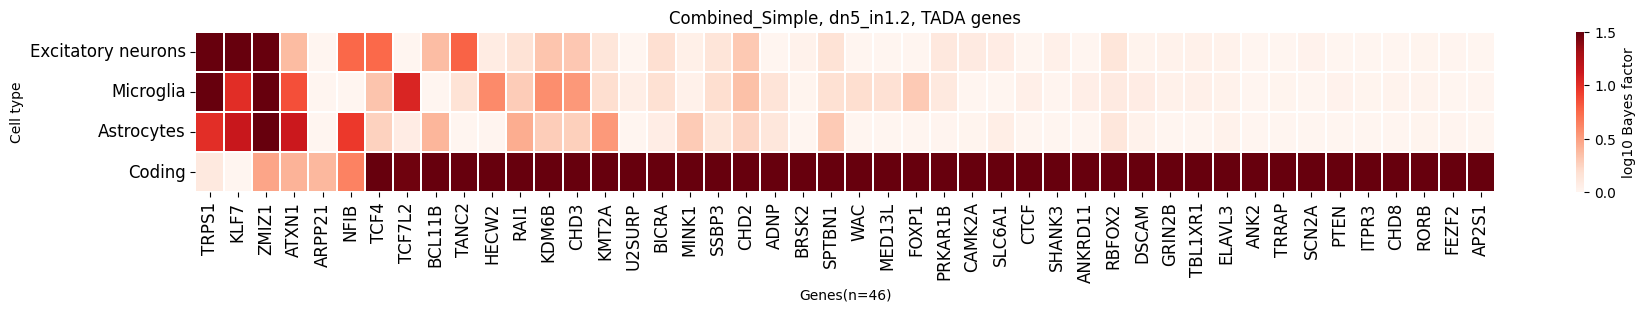

In [108]:
method_tag = "ScaleByLOEUF"
sample_tag = "Combined_Simple"
df_coding = pd.read_csv(f"{tada_output_path}TADA_coding_UCSF_rare_CodingOnly_Roulette_MR_{method_tag}.txt", sep = "\t")
df_coding = df_coding.rename(columns = {"fdr": "FDR_TADA_ASD"})
df_coding["l10BF_ASD_Coding"] = df_coding["bf"].apply(lambda x: np.log10(x))
df_coding = df_coding[["gene_id", "FDR_TADA_ASD", "l10BF_ASD_Coding"]]
df_all = pd.read_csv(f"{tada_output_path}TADA_coding_UCSF_rare_{sample_tag}_Roulette_MR_{method_tag}.txt", sep = "\t")
df_all = df_all.rename(columns = {"fdr": "FDR_TADA_ASD_AddEM"})
df_all["l10BF_ASD_EM"] = df_all.apply(lambda x: np.log10(x["bf.dn.em"] * x["bf.in.em"]), axis=1)
df_merge = pd.merge(df_coding, df_all, on="gene_id")
df_merge = df_merge.rename(columns = {"Hugo_Symbol": "gene"})
display(df_merge)
tada_coding_genes, tada_all_genes = tada_analysis(df_merge, asd_genes, title=f"With rare filter")
tada_all_genes_unique = tada_all_genes - tada_coding_genes
for x in ["Deconv_Excitatory_Neurons", "Deconv_Microglia", "Deconv_Astrocytes", "Other_Cerebral_Cortex"]:
    df_tmp = pd.read_csv(f"{tada_output_path}TADA_coding_UCSF_rare_{x}_Roulette_MR_{method_tag}.txt", sep = "\t")
    x = x.replace("Deconv_", "")
    df_tmp[f"l10BF_ASD_EM_{x}"] = df_tmp.apply(lambda x: np.log10(x["bf.dn.em"] * x["bf.in.em"]), axis=1)
    df_merge = pd.merge(df_merge, df_tmp[["gene_id", f"l10BF_ASD_EM_{x}"]], on="gene_id")
df_merge = df_merge.sort_values(by=["l10BF_ASD_EM", "l10BF_ASD_EM_Excitatory_Neurons", "l10BF_ASD_EM_Microglia", "l10BF_ASD_EM_Astrocytes", "l10BF_ASD_EM_Other_Cerebral_Cortex", "l10BF_ASD_Coding"], ascending=False)
df_merge = df_merge[df_merge["l10BF_ASD_EM"] > 0]
df_long = df_merge[df_merge["gene"].isin(tada_all_genes)]
df_short = df_merge[df_merge["gene"].isin(tada_all_genes_unique)]
print("TADA coding+noncoding genes (l10BF_ASD_EM>0):", df_long.shape[0])
lbf_heatmap(df_short, figtitle= f"{sample_tag}, {rr_tag}, TADA additional genes")
lbf_heatmap(df_long, figtitle= f"{sample_tag}, {rr_tag}, TADA genes", vmax=1.5)

## UCSF coding count, Roulette mutation rate without gnomAD<=0 filter

############# mutscaled


,gene_id,FDR_TADA_ASD,l10BF_ASD_Coding,gene,LOEUF,pLI,bf.dn.ptv,bf.in.ptv,bf.dn.misb,bf.in.misb,bf.dn.misa,bf.in.misa,bf.dn.em,bf.in.em,bf,FDR_TADA_ASD_AddEM,pval,l10BF_ASD_EM
0,ENSG00000108510,0.525069,0.611881,MED13,0.030,1.000000e+00,3.890587,1.0,1.000000,1.000000,1.0,1.051638,1.0,1.000000,4.091488,0.560584,0.026869,0.000000
1,ENSG00000164190,0.887309,0.029641,NIPBL,0.032,1.000000e+00,1.000000,1.0,1.000000,1.000000,1.0,1.070634,1.0,1.079713,1.155978,0.870903,0.313339,0.033308
2,ENSG00000108055,0.201616,1.397580,SMC3,0.037,1.000000e+00,1.000000,1.0,14.045633,1.651233,1.0,1.077037,1.0,1.012382,25.288584,0.205633,0.002622,0.005344
3,ENSG00000125107,0.315646,1.162893,CNOT1,0.038,1.000000e+00,1.000000,1.0,13.984860,1.040482,1.0,1.000000,1.0,1.000000,14.550992,0.314313,0.006274,0.000000
4,ENSG00000117000,0.492807,0.675146,RLF,0.040,1.000000e+00,4.151228,1.0,1.000000,1.000000,1.0,1.140169,1.0,1.214362,5.747697,0.473988,0.016674,0.084348
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17589,ENSG00000165474,0.930421,0.000000,GJB2,1.984,6.562000e-16,1.000000,1.0,1.000000,1.000000,1.0,1.000000,1.0,1.000000,1.000000,0.919460,0.887804,0.000000
17590,ENSG00000150244,0.930422,0.000000,TRIM48,1.985,1.099500e-27,1.000000,1.0,1.000000,1.000000,1.0,1.000000,1.0,1.000000,1.000000,0.918316,0.854678,0.000000
17591,ENSG00000231924,0.930423,0.000000,PSG1,1.986,1.624200e-29,1.000000,1.0,1.000000,1.000000,1.0,1.000000,1.0,1.000000,1.000000,0.922418,0.986188,0.000000
17592,ENSG00000099949,0.604817,0.492608,LZTR1,1.994,1.021100e-92,1.871395,1.0,1.000000,1.326602,1.0,1.252280,1.0,1.000000,3.108906,0.630541,0.040206,0.000000


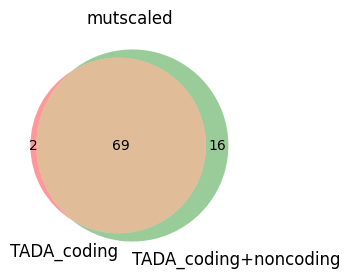

c1: 39, n1: 71, c2: 460, n2: 17588
enrichment: 21.00220453153705, log_enr: 3.044627409905891, SE_log_enr: 0.11693406130948905, pval: 1.88195821308631e-149, z: 26.03713046319057, conf_intervals: (np.float64(16.700536775861178), np.float64(26.411881312825056))
c1: 9, n1: 16, c2: 460, n2: 17588
enrichment: 21.507065217391304, log_enr: 3.0683814959139983, SE_log_enr: 0.22522914377733252, pval: 2.9080422334647555e-42, z: 13.623376817289158, conf_intervals: (np.float64(13.831387774105059), np.float64(33.44233144349479))


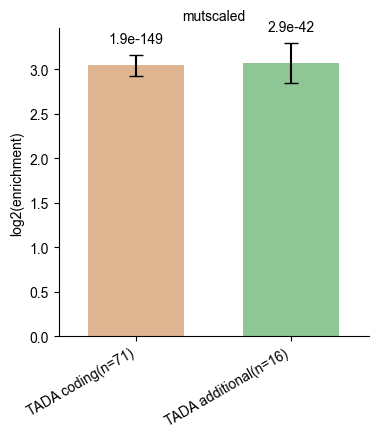

TADA coding+noncoding genes (l10BF_ASD_EM>0): 61


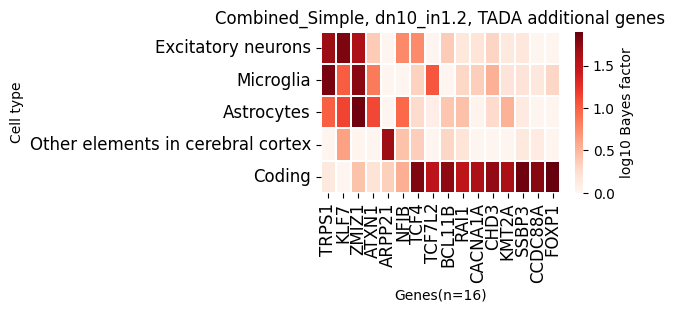

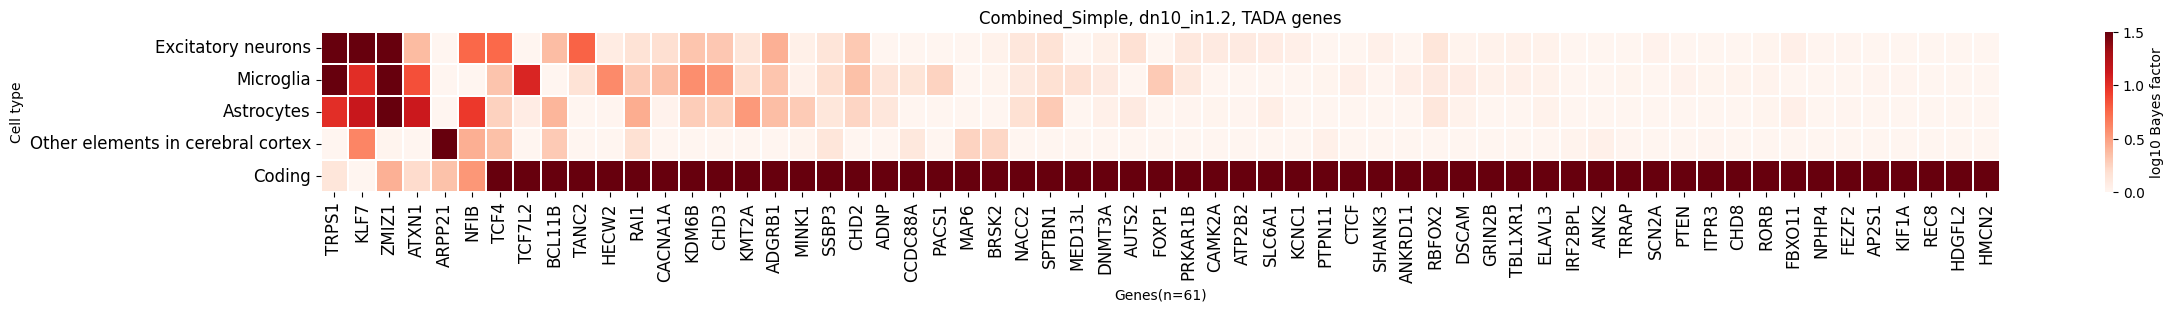

############# mutunscaled


,gene_id,FDR_TADA_ASD,l10BF_ASD_Coding,gene,LOEUF,pLI,bf.dn.ptv,bf.in.ptv,bf.dn.misb,bf.in.misb,bf.dn.misa,bf.in.misa,bf.dn.em,bf.in.em,bf,FDR_TADA_ASD_AddEM,pval,l10BF_ASD_EM
0,ENSG00000108510,0.275520,1.219424,MED13,0.030,1.000000e+00,15.070189,1.0,1.000000,1.000000,1.0,1.099778,1.0,1.000000,16.573860,0.276895,0.006292,0.000000
1,ENSG00000164190,0.867875,0.048159,NIPBL,0.032,1.000000e+00,1.000000,1.0,1.000000,1.000000,1.0,1.117271,1.0,1.079713,1.206333,0.851259,0.285334,0.033308
2,ENSG00000108055,0.172412,1.405666,SMC3,0.037,1.000000e+00,1.000000,1.0,13.840250,1.644486,1.0,1.118128,1.0,1.012382,25.763818,0.180736,0.002809,0.005344
3,ENSG00000125107,0.307552,1.169364,CNOT1,0.038,1.000000e+00,1.000000,1.0,13.660205,1.033668,1.0,1.045985,1.0,1.000000,14.769430,0.305644,0.007758,0.000000
4,ENSG00000117000,0.257276,1.249404,RLF,0.040,1.000000e+00,14.889961,1.0,1.000000,1.000000,1.0,1.192644,1.0,1.214362,21.565155,0.211943,0.003727,0.084348
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17589,ENSG00000165474,0.925953,0.000000,GJB2,1.984,6.562000e-16,1.000000,1.0,1.000000,1.000000,1.0,1.000000,1.0,1.000000,1.000000,0.914464,0.889779,0.000000
17590,ENSG00000150244,0.925955,0.000000,TRIM48,1.985,1.099500e-27,1.000000,1.0,1.000000,1.000000,1.0,1.000000,1.0,1.000000,1.000000,0.913236,0.858900,0.000000
17591,ENSG00000231924,0.907245,0.000000,PSG1,1.986,1.624200e-29,1.000000,1.0,1.000000,1.000000,1.0,1.000000,1.0,1.000000,1.000000,0.908406,0.755148,0.000000
17592,ENSG00000099949,0.726167,0.262131,LZTR1,1.994,1.021100e-92,1.039614,1.0,1.000000,1.317328,1.0,1.335259,1.0,1.000000,1.828653,0.746290,0.107378,0.000000


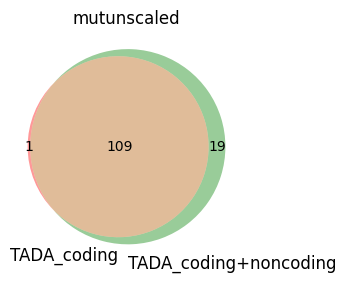

c1: 62, n1: 110, c2: 460, n2: 17588
enrichment: 21.550513833992095, log_enr: 3.0703996600702355, SE_log_enr: 0.09568270095850477, pval: 6.199191424823419e-226, z: 32.08939159652059, conf_intervals: (np.float64(17.86538447274093), np.float64(25.995782358767904))
c1: 9, n1: 19, c2: 460, n2: 17588
enrichment: 18.11121281464531, log_enr: 2.896531238987339, SE_log_enr: 0.24616374277968295, pval: 5.795744490190447e-32, z: 11.766685078312856, conf_intervals: (np.float64(11.17924762375648), np.float64(29.341512117534776))


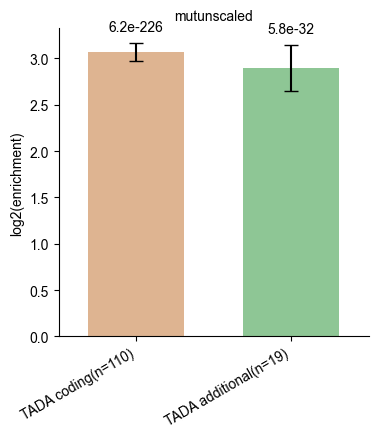

TADA coding+noncoding genes (l10BF_ASD_EM>0): 95


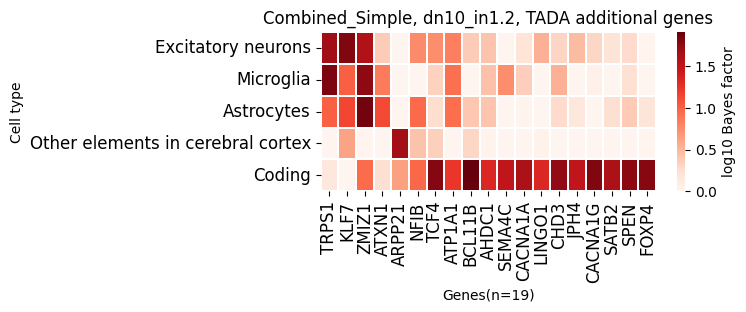

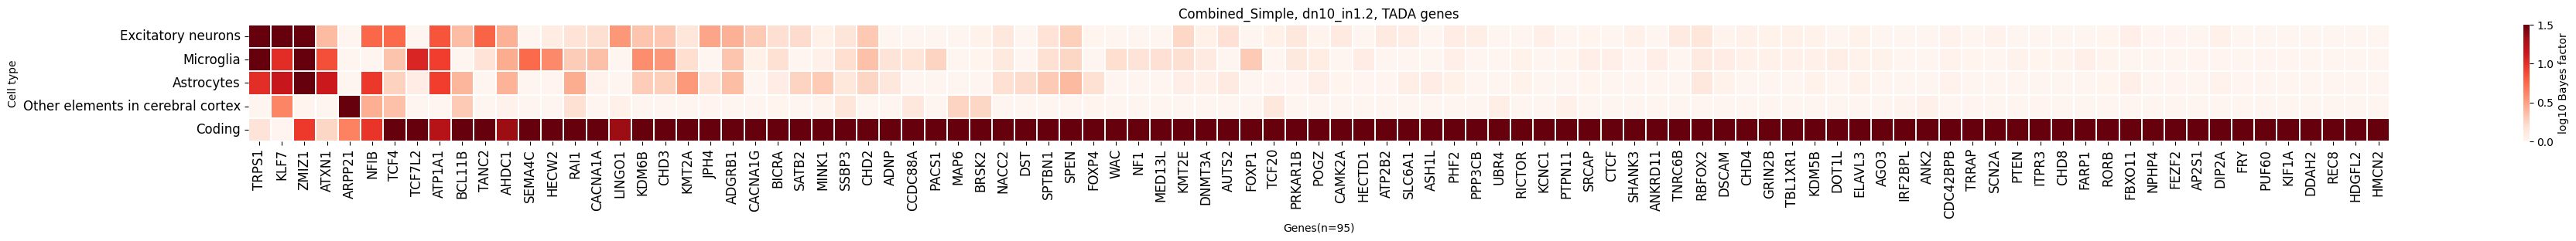

In [ ]:
method_tag = "ScaleByLOEUF"
sample_tag = "Combined_Simple"
for mutrate_tag in ["mutscaled", "mutunscaled"]:
    print("#############", mutrate_tag)
    df_coding = pd.read_csv(f"{tada_output_path}TADA_coding_UCSF_{mutrate_tag}_CodingOnly_Roulette_MR_{method_tag}.txt", sep = "\t")
    df_coding = df_coding.rename(columns = {"fdr": "FDR_TADA_ASD"})
    df_coding["l10BF_ASD_Coding"] = df_coding["bf"].apply(lambda x: np.log10(x))
    df_coding = df_coding[["gene_id", "FDR_TADA_ASD", "l10BF_ASD_Coding"]]
    df_all = pd.read_csv(f"{tada_output_path}TADA_coding_UCSF_{mutrate_tag}_{sample_tag}_Roulette_MR_{method_tag}.txt", sep = "\t")
    df_all = df_all.rename(columns = {"fdr": "FDR_TADA_ASD_AddEM"})
    df_all["l10BF_ASD_EM"] = df_all.apply(lambda x: np.log10(x["bf.dn.em"] * x["bf.in.em"]), axis=1)
    df_merge = pd.merge(df_coding, df_all, on="gene_id")
    df_merge = df_merge.rename(columns = {"Hugo_Symbol": "gene"})
    display(df_merge)
    tada_coding_genes, tada_all_genes = tada_analysis(df_merge, asd_genes, title=f"{mutrate_tag}")
    tada_all_genes_unique = tada_all_genes - tada_coding_genes
    for x in ["Deconv_Excitatory_Neurons", "Deconv_Microglia", "Deconv_Astrocytes", "Other_Cerebral_Cortex"]:
        df_tmp = pd.read_csv(f"{tada_output_path}TADA_coding_UCSF_{mutrate_tag}_{x}_Roulette_MR_{method_tag}.txt", sep = "\t")
        x = x.replace("Deconv_", "")
        df_tmp[f"l10BF_ASD_EM_{x}"] = df_tmp.apply(lambda x: np.log10(x["bf.dn.em"] * x["bf.in.em"]), axis=1)
        df_merge = pd.merge(df_merge, df_tmp[["gene_id", f"l10BF_ASD_EM_{x}"]], on="gene_id")
    df_merge = df_merge.sort_values(by=["l10BF_ASD_EM", "l10BF_ASD_EM_Excitatory_Neurons", "l10BF_ASD_EM_Microglia", "l10BF_ASD_EM_Astrocytes", "l10BF_ASD_EM_Other_Cerebral_Cortex", "l10BF_ASD_Coding"], ascending=False)
    df_merge = df_merge[df_merge["l10BF_ASD_EM"] > 0]
    df_long = df_merge[df_merge["gene"].isin(tada_all_genes)]
    df_short = df_merge[df_merge["gene"].isin(tada_all_genes_unique)]
    print("TADA coding+noncoding genes (l10BF_ASD_EM>0):", df_long.shape[0])
    lbf_heatmap(df_short, figtitle= f"{sample_tag}, {rr_tag}, TADA additional genes")
    lbf_heatmap(df_long, figtitle= f"{sample_tag}, {rr_tag}, TADA genes", vmax=1.5)

## FuScaled coding count, Fu's coding mutation rate

,gene_id,FDR_TADA_ASD,l10BF_ASD_Coding,gene,LOEUF,pLI,bf.dn.ptv,bf.in.ptv,bf.dn.misb,bf.in.misb,bf.dn.misa,bf.in.misa,bf.dn.em,bf.in.em,bf,FDR_TADA_ASD_AddEM,pval,l10BF_ASD_EM
0,ENSG00000108510,0.028447,2.269417,MED13,0.030,1.000000e+00,149.549459,1.0,1.000000,1.101599,1.0,1.128779,1.0,1.000000,185.959012,0.034750,0.000121,0.000000
1,ENSG00000164190,0.830872,0.115551,NIPBL,0.032,1.000000e+00,1.000000,1.0,1.000000,1.244634,1.0,1.048358,1.0,1.079713,1.408834,0.817882,0.173510,0.033308
2,ENSG00000108055,0.525869,0.861268,SMC3,0.037,1.000000e+00,1.000000,1.0,7.265549,1.000000,1.0,1.000000,1.0,1.012382,7.355511,0.500730,0.020628,0.005344
3,ENSG00000125107,0.398363,1.081340,CNOT1,0.038,1.000000e+00,1.000000,1.0,6.673483,1.446610,1.0,1.249212,1.0,1.000000,12.059796,0.387545,0.009444,0.000000
4,ENSG00000117000,0.914891,0.000000,RLF,0.040,1.000000e+00,1.000000,1.0,1.000000,1.000000,1.0,1.000000,1.0,1.214362,1.214362,0.858329,0.276913,0.084348
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18123,ENSG00000150244,0.928816,0.000000,TRIM48,1.985,1.099500e-27,1.000000,1.0,1.000000,1.000000,1.0,1.000000,1.0,1.000000,1.000000,0.916327,0.848520,0.000000
18124,ENSG00000231924,0.928817,0.000000,PSG1,1.986,1.624200e-29,1.000000,1.0,1.000000,1.000000,1.0,1.000000,1.0,1.000000,1.000000,0.920629,0.977360,0.000000
18125,ENSG00000163386,0.928818,0.000000,NBPF10,1.988,4.100800e-85,1.000000,1.0,1.000000,1.000000,1.0,1.000000,1.0,1.000000,1.000000,0.916962,0.865414,0.000000
18126,ENSG00000099949,0.758645,0.200420,LZTR1,1.994,1.021100e-92,1.116063,1.0,1.000000,1.305286,1.0,1.088994,1.0,1.000000,1.586426,0.782407,0.125319,0.000000


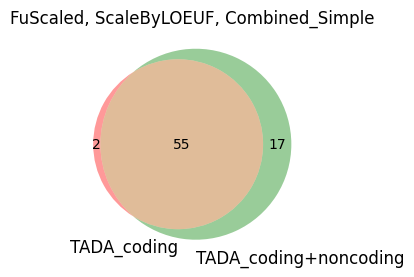

c1: 50, n1: 57, c2: 464, n2: 18107
enrichment: 34.23132183908046, log_enr: 3.5331410681879833, SE_log_enr: 0.06749878150377735, pval: 0.0, z: 52.34377553897418, conf_intervals: (np.float64(29.989457026348283), np.float64(39.073178077922385))
c1: 9, n1: 17, c2: 464, n2: 18107
enrichment: 20.65960953346856, log_enr: 3.0281805638743906, SE_log_enr: 0.2332113351725509, pval: 1.494112983804066e-38, z: 12.984705746115933, conf_intervals: (np.float64(13.080136034285346), np.float64(32.63111828169186))


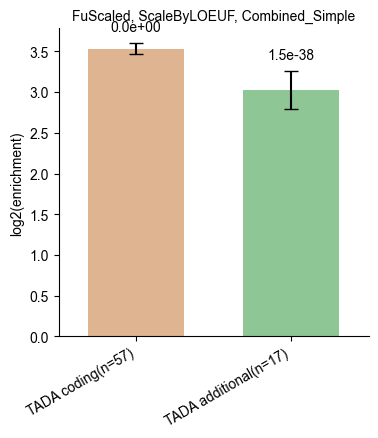

TADA coding+noncoding genes (l10BF_ASD_EM>0): 55


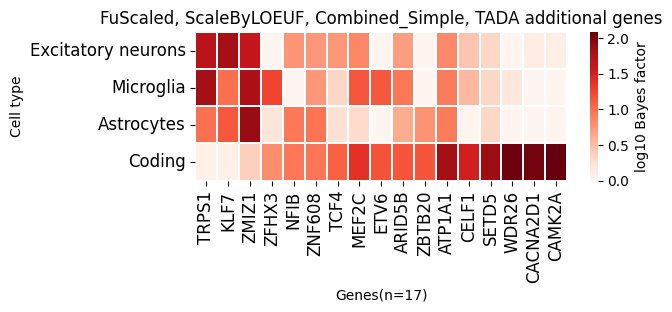

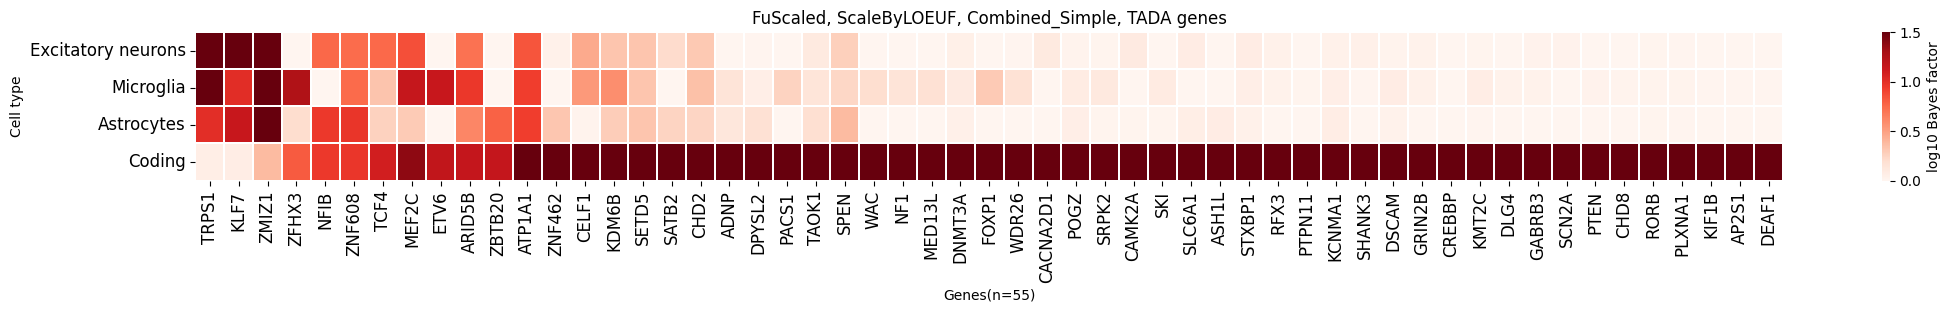

In [260]:
method_tag = "ScaleByLOEUF"
sample_tag = "Combined_Simple"
coding_tag = "FuScaled"
df_coding = pd.read_csv(f"{tada_output_path}TADA_{coding_tag}_codingOnly.txt", sep = "\t")
df_coding = df_coding.rename(columns = {"fdr": "FDR_TADA_ASD"})
df_coding["l10BF_ASD_Coding"] = df_coding["bf"].apply(lambda x: np.log10(x))
df_coding = df_coding[["gene_id", "FDR_TADA_ASD", "l10BF_ASD_Coding"]]
df_all = pd.read_csv(f"{tada_output_path}TADA_{coding_tag}_{sample_tag}_Roulette_MR_{method_tag}.txt", sep = "\t")
df_all = df_all.rename(columns = {"fdr": "FDR_TADA_ASD_AddEM"})
df_all["l10BF_ASD_EM"] = df_all.apply(lambda x: np.log10(x["bf.dn.em"] * x["bf.in.em"]), axis=1)
df_merge = pd.merge(df_coding, df_all, on="gene_id")
df_merge = df_merge.rename(columns = {"Hugo_Symbol": "gene"})
display(df_merge)
tada_coding_genes, tada_all_genes = tada_analysis(df_merge, asd_genes, title=f"{coding_tag}, {method_tag}, {sample_tag}")
tada_all_genes_unique = tada_all_genes - tada_coding_genes
for x in ["Deconv_Excitatory_Neurons", "Deconv_Microglia", "Deconv_Astrocytes"]:#, "Other_Cerebral_Cortex"]:
    df_tmp = pd.read_csv(f"{tada_output_path}TADA_{coding_tag}_{x}_Roulette_MR_{method_tag}.txt", sep = "\t")
    x = x.replace("Deconv_", "")
    df_tmp[f"l10BF_ASD_EM_{x}"] = df_tmp.apply(lambda x: np.log10(x["bf.dn.em"] * x["bf.in.em"]), axis=1)
    df_merge = pd.merge(df_merge, df_tmp[["gene_id", f"l10BF_ASD_EM_{x}"]], on="gene_id")
df_merge = df_merge.sort_values(by=["l10BF_ASD_EM", "l10BF_ASD_EM_Excitatory_Neurons", "l10BF_ASD_EM_Microglia", "l10BF_ASD_EM_Astrocytes", "l10BF_ASD_Coding"], ascending=False)
df_merge = df_merge[df_merge["l10BF_ASD_EM"] > 0]
df_long = df_merge[df_merge["gene"].isin(tada_all_genes)]
df_short = df_merge[df_merge["gene"].isin(tada_all_genes_unique)]
print("TADA coding+noncoding genes (l10BF_ASD_EM>0):", df_long.shape[0])
lbf_heatmap(df_short, figtitle= f"{coding_tag}, {method_tag}, {sample_tag}, TADA additional genes")
lbf_heatmap(df_long, figtitle= f"{coding_tag}, {method_tag}, {sample_tag}, TADA genes", vmax=1.5)

## UCSF coding count, Fu's coding mutation rate

In [ ]:
df_loeuf = pd.read_csv("/Genomics/argo/users/yz8667/Autism_network_integration/data/TADA/output/InhAll_DNVAll/TADA_FuRawSup11_Combined_Simple_Roulette_MR_ScaleByLOEUF.txt", sep = "\t")
df_loeuf
# 

,gene,gene_gencodeV33,gene_id,FDR_TADA_ASD,p_TADA_ASD,l10BF_ASD_PTV,l10BF_ASD_misB,l10BF_ASD_misA,l10BF_ASD_DEL,l10BF_ASD_DUP,l10BF_ASD_EM,BF_ASD_PTV,BF_ASD_misB,BF_ASD_misA,BF_ASD_DEL,BF_ASD_DUP,BF_ASD_EM,BF_ASD,FDR_TADA_ASD_AddEM,p_TADA_ASD_AddEM
0,MED13,MED13,ENSG00000108510,1.390292e-07,2.104537e-10,6.671037e+00,0.362988,0.062879,0.0,0.000000,0.000000,4.688530e+06,2.306685,1.155790,1.0,1.000000,1.000000,1.249983e+07,1.296459e-07,1.980326e-10
1,NIPBL,NIPBL,ENSG00000164190,9.954028e-06,2.290304e-08,0.000000e+00,1.586224,0.144206,0.0,3.659043,0.033308,1.000000e+00,38.567683,1.393818,1.0,4560.822556,1.079713,2.647166e+05,7.895777e-06,1.833227e-08
2,SMC3,SMC3,ENSG00000108055,1.584900e-01,3.195632e-03,0.000000e+00,1.440559,0.000000,0.0,0.000000,0.005344,1.000000e+00,27.577746,1.000000,1.0,1.000000,1.012382,2.791921e+01,1.646678e-01,4.034511e-03
3,CNOT1,CNOT1,ENSG00000125107,5.438422e-01,4.129344e-02,0.000000e+00,0.627486,0.000000,0.0,0.000000,0.000000,1.000000e+00,4.241178,1.000000,1.0,1.000000,1.000000,4.241178e+00,5.474731e-01,5.084453e-02
4,RLF,RLF,ENSG00000117000,6.212839e-01,6.376324e-02,4.636165e-01,0.000000,0.023187,0.0,0.000000,0.084348,2.908148e+00,1.000000,1.054841,1.0,1.000000,1.214362,3.725217e+00,5.761548e-01,5.963352e-02
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18123,TRIM48,TRIM48,ENSG00000150244,8.833030e-01,5.662839e-01,1.928655e-16,0.000000,0.000000,0.0,0.000000,0.000000,1.000000e+00,1.000000,1.000000,1.0,1.000000,1.000000,1.000000e+00,8.873131e-01,7.393219e-01
18124,PSG1,PSG1,ENSG00000231924,9.110422e-01,9.999425e-01,0.000000e+00,0.000000,0.000000,0.0,0.000000,0.000000,1.000000e+00,1.000000,1.000000,1.0,1.000000,1.000000,1.000000e+00,8.906305e-01,7.835519e-01
18125,NBPF10,NBPF10,ENSG00000163386,9.110443e-01,1.000000e+00,0.000000e+00,0.000000,0.000000,0.0,0.000000,0.000000,1.000000e+00,1.000000,1.000000,1.0,1.000000,1.000000,1.000000e+00,9.028326e-01,9.997678e-01
18126,LZTR1,LZTR1,ENSG00000099949,7.821813e-01,1.861275e-01,3.525056e-03,0.090901,0.083536,0.0,0.000000,0.000000,1.008150e+00,1.232823,1.212093,1.0,1.000000,1.000000,1.506474e+00,7.856974e-01,2.328758e-01


,gene_id,gene,LOEUF,pLI,bf.dn.ptv,bf.in.ptv,bf.dn.misb,bf.in.misb,bf.dn.misa,bf.in.misa,bf.dn.em,bf.in.em,bf,FDR_TADA_ASD_AddEM,pval,FDR_TADA_ASD
0,ENSG00000000419,DPM1,0.873,1.623700e-04,1.0,1.000000,1.0,1.000000,1.0,1.000000,1.0,1.100054,1.100054,0.888288,0.334016,0.928106
1,ENSG00000000457,SCYL3,0.421,2.815100e-01,1.0,1.000000,1.0,1.000000,1.0,1.000000,1.0,1.000000,1.000000,0.919155,0.710044,0.922964
2,ENSG00000000460,C1orf112,0.730,3.352300e-10,1.0,1.189095,1.0,1.000000,1.0,1.000000,1.0,1.000000,1.189095,0.865979,0.231826,0.849320
3,ENSG00000000938,FGR,0.425,4.840800e-01,1.0,1.000000,1.0,1.160202,1.0,1.000000,1.0,1.145976,1.329564,0.834166,0.155072,0.858592
4,ENSG00000000971,CFH,0.324,8.606100e-01,1.0,1.000000,1.0,1.000000,1.0,1.136693,1.0,1.000000,1.136693,0.878822,0.282808,0.866506
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18123,ENSG00000273171,AC002094.3,1.427,9.783500e-05,1.0,1.000000,1.0,1.000000,1.0,1.000000,1.0,1.005434,1.005434,0.915556,0.633239,0.932423
18124,ENSG00000273173,SNURF,0.836,4.619000e-01,1.0,1.021523,1.0,1.000000,1.0,1.000000,1.0,1.039706,1.062083,0.898086,0.406415,0.905935
18125,ENSG00000273217,AC008695.1,0.301,9.633800e-01,1.0,1.000000,1.0,1.000000,1.0,1.000000,1.0,1.000000,1.000000,0.927888,0.999887,0.921327
18126,ENSG00000273266,HOXC4,0.735,1.684600e-01,1.0,1.000000,1.0,1.000000,1.0,1.000000,1.0,1.000000,1.000000,0.927890,0.999944,0.926621


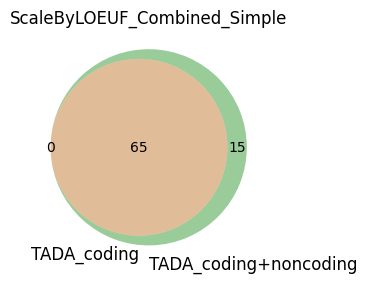

c1: 43, n1: 65, c2: 464, n2: 18107
enrichment: 25.81568302387268, log_enr: 3.250982176392313, SE_log_enr: 0.09985561437641084, pval: 1.6760835698022692e-232, z: 32.556829144704565, conf_intervals: (np.float64(21.22688988093784), np.float64(31.39647370515418))
c1: 6, n1: 15, c2: 464, n2: 18107
enrichment: 15.609482758620691, log_enr: 2.7478785987202325, SE_log_enr: 0.31953082035011504, pval: 7.990425580778928e-18, z: 8.59972942738149, conf_intervals: (np.float64(8.344558909725627), np.float64(29.199380653625013))


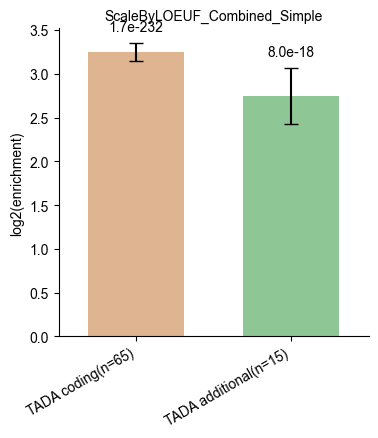

In [18]:
dr = "/Genomics/argo/users/yz8667/Autism_network_integration/data/TADA/output/InhAll_DNVAll/"
method_tag = "ScaleByLOEUF"
sample_tag = "Combined_Simple"
df1 = pd.read_csv(dr + "TADA_UCSF_codingOnly.txt", sep="\t").rename(columns = {"fdr": "FDR_TADA_ASD"})
df2 = pd.read_csv(dr + f"TADA_UCSF_{sample_tag}_Roulette_MR_{method_tag}_dn5_in1.2.txt", sep = "\t").rename(columns = {"fdr": "FDR_TADA_ASD_AddEM"})
df = pd.merge(df2, df1[["gene_id", "FDR_TADA_ASD"]], on="gene_id").rename(columns = {"Hugo_Symbol": "gene"})
display(df)
tada_coding_genes, tada_all_genes_scaledbyloeuf = tada_analysis(df, asd_genes, method_tag + "_" + sample_tag)